Files in the dataset directory:
- validation.csv
- train.csv
- test.csv


Dataset loaded successfully!
Train set shape: (16218, 10)
Test set shape: (2028, 10)
Validation set shape: (2030, 10)


TRAIN SET ANALYSIS:
Columns: ['statement', 'label', 'class', 'source', 'subject', 'context', 'speaker', 'speaker_job_title', 'party_affiliation', 'state_info', 'class_name']

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16218 entries, 0 to 16217
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   statement          16218 non-null  object
 1   label              16218 non-null  int64 
 2   class              16218 non-null  object
 3   source             16218 non-null  object
 4   subject            16215 non-null  object
 5   context            16053 non-null  object
 6   speaker            16215 non-null  object
 7   speaker_job_title  11681 non-null  object
 8   party_affiliation  16215 non-null

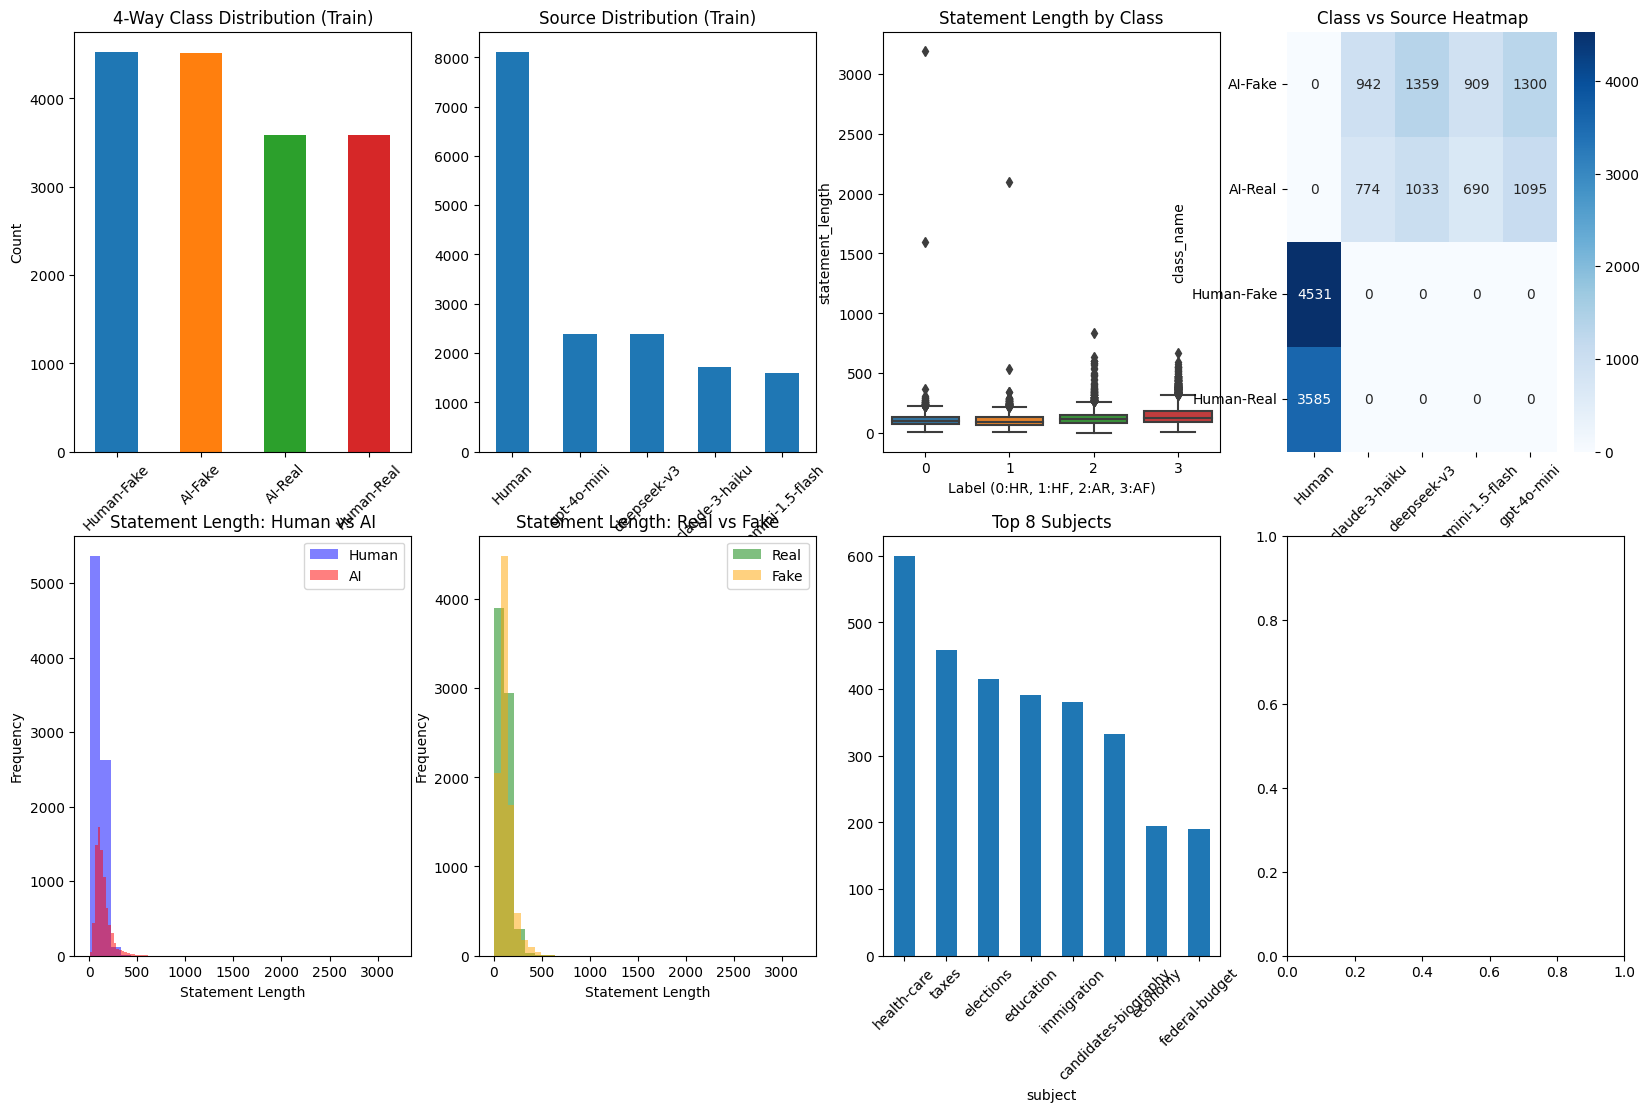

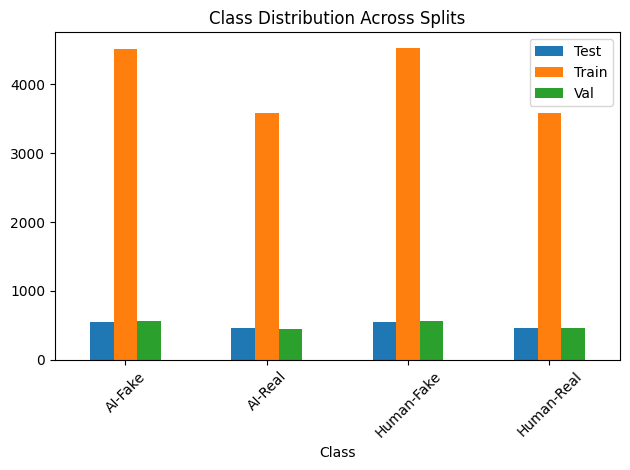


DATASET READY FOR 4-WAY CLASSIFICATION
Total samples: 20276
Classes: ['Human-Real', 'Human-Fake', 'AI-Real', 'AI-Fake']
Features available: ['statement', 'source', 'subject', 'context', 'speaker', 'speaker_job_title', 'party_affiliation', 'state_info']
Target variable: 'label' (0=Human-Real, 1=Human-Fake, 2=AI-Real, 3=AI-Fake)

Class balance in training set:
  Human-Real: 3585 samples (22.1%)
  Human-Fake: 4531 samples (27.9%)
  AI-Real: 3592 samples (22.1%)
  AI-Fake: 4510 samples (27.8%)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import os

# Set display options for better dataframe viewing
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

# Load the dataset
dataset_path = '/kaggle/input/dataset/split'

# Check what files are available
print("Files in the dataset directory:")
for file in os.listdir(dataset_path):
    print(f"- {file}")
print("\n" + "="*50 + "\n")

# Load train, test, validation sets
try:
    train_df = pd.read_csv(f'{dataset_path}/train.csv')
    test_df = pd.read_csv(f'{dataset_path}/test.csv')
    val_df = pd.read_csv(f'{dataset_path}/validation.csv')
    
    print("Dataset loaded successfully!")
    print(f"Train set shape: {train_df.shape}")
    print(f"Test set shape: {test_df.shape}")
    print(f"Validation set shape: {val_df.shape}")
    
except Exception as e:
    print(f"Error loading files: {e}")
    # Let's check what files exist and their names
    files = os.listdir(dataset_path)
    print(f"Available files: {files}")
    
    # Try different common names
    for filename in files:
        if filename.endswith('.csv'):
            df_temp = pd.read_csv(f'{dataset_path}/{filename}')
            print(f"\n{filename} shape: {df_temp.shape}")
            print(f"{filename} columns: {df_temp.columns.tolist()}")

print("\n" + "="*50 + "\n")

# If successful, continue with analysis
if 'train_df' in locals():
    # Define class mapping for clarity
    class_mapping = {
        0: 'Human-Real',
        1: 'Human-Fake', 
        2: 'AI-Real',
        3: 'AI-Fake'
    }
    
    # Add readable class names
    train_df['class_name'] = train_df['label'].map(class_mapping)
    test_df['class_name'] = test_df['label'].map(class_mapping)
    val_df['class_name'] = val_df['label'].map(class_mapping)
    
    # Display column information
    print("TRAIN SET ANALYSIS:")
    print(f"Columns: {train_df.columns.tolist()}")
    print(f"\nDataset Info:")
    print(train_df.info())
    
    print("\n" + "="*30 + "\n")
    
    # Show first few rows (excluding 'class' column if it exists)
    columns_to_show = [col for col in train_df.columns if col != 'class']
    print("First 3 rows (excluding 'class' column):")
    print(train_df[columns_to_show].head(3))
    
    print("\n" + "="*30 + "\n")
    
    # 4-way label distribution
    print("4-WAY CLASSIFICATION LABEL DISTRIBUTION:")
    print("\nTrain set:")
    train_dist = train_df['label'].value_counts().sort_index()
    for label, count in train_dist.items():
        print(f"Label {label} ({class_mapping[label]}): {count}")
    
    print("\nTest set:")
    test_dist = test_df['label'].value_counts().sort_index()
    for label, count in test_dist.items():
        print(f"Label {label} ({class_mapping[label]}): {count}")
    
    print("\nValidation set:")
    val_dist = val_df['label'].value_counts().sort_index()
    for label, count in val_dist.items():
        print(f"Label {label} ({class_mapping[label]}): {count}")
    
    print("\n" + "="*30 + "\n")
    
    # Check class balance
    print("CLASS BALANCE ANALYSIS:")
    total_train = len(train_df)
    print("Train set percentages:")
    for label, count in train_dist.items():
        percentage = (count / total_train) * 100
        print(f"{class_mapping[label]}: {percentage:.2f}%")
    
    print("\n" + "="*30 + "\n")
    
    # Source distribution by class
    print("SOURCE DISTRIBUTION BY CLASS:")
    source_class_dist = train_df.groupby(['label', 'source']).size().unstack(fill_value=0)
    print(source_class_dist)
    
    print("\n" + "="*30 + "\n")
    
    # Check for missing values
    print("Missing values in train set:")
    missing_values = train_df.isnull().sum()
    print(missing_values[missing_values > 0])
    if missing_values.sum() == 0:
        print("No missing values found!")
    
    print("\n" + "="*30 + "\n")
    
    # Statement length analysis
    train_df['statement_length'] = train_df['statement'].str.len()
    
    print("Statement length statistics by class:")
    length_stats = train_df.groupby('class_name')['statement_length'].describe()
    print(length_stats)
    
    print("\n" + "="*30 + "\n")
    
    # Sample statements from each category
    print("Sample statements by class:")
    for label in sorted(train_df['label'].unique()):
        class_name = class_mapping[label]
        print(f"\n{class_name} examples:")
        samples = train_df[train_df['label'] == label]['statement'].head(2)
        for i, stmt in enumerate(samples, 1):
            print(f"{i}. {stmt[:150]}...")
    
    # Create comprehensive visualization
    plt.figure(figsize=(20, 12))
    
    # Plot 1: 4-way class distribution
    plt.subplot(2, 4, 1)
    class_counts = train_df['class_name'].value_counts()
    class_counts.plot(kind='bar', color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
    plt.title('4-Way Class Distribution (Train)')
    plt.xlabel('Class')
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    
    # Plot 2: Source distribution
    plt.subplot(2, 4, 2)
    train_df['source'].value_counts().plot(kind='bar')
    plt.title('Source Distribution (Train)')
    plt.xticks(rotation=45)
    
    # Plot 3: Statement length by class
    plt.subplot(2, 4, 3)
    sns.boxplot(data=train_df, x='label', y='statement_length')
    plt.title('Statement Length by Class')
    plt.xlabel('Label (0:HR, 1:HF, 2:AR, 3:AF)')
    
    # Plot 4: Heatmap of class vs source
    plt.subplot(2, 4, 4)
    source_class_crosstab = pd.crosstab(train_df['class_name'], train_df['source'])
    sns.heatmap(source_class_crosstab, annot=True, fmt='d', cmap='Blues')
    plt.title('Class vs Source Heatmap')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    
    # Plot 5: Statement length distribution by Human vs AI
    plt.subplot(2, 4, 5)
    human_lengths = train_df[train_df['label'].isin([0,1])]['statement_length']
    ai_lengths = train_df[train_df['label'].isin([2,3])]['statement_length']
    plt.hist(human_lengths, alpha=0.5, label='Human', bins=30, color='blue')
    plt.hist(ai_lengths, alpha=0.5, label='AI', bins=30, color='red')
    plt.xlabel('Statement Length')
    plt.ylabel('Frequency')
    plt.legend()
    plt.title('Statement Length: Human vs AI')
    
    # Plot 6: Statement length distribution by Real vs Fake
    plt.subplot(2, 4, 6)
    real_lengths = train_df[train_df['label'].isin([0,2])]['statement_length']
    fake_lengths = train_df[train_df['label'].isin([1,3])]['statement_length']
    plt.hist(real_lengths, alpha=0.5, label='Real', bins=30, color='green')
    plt.hist(fake_lengths, alpha=0.5, label='Fake', bins=30, color='orange')
    plt.xlabel('Statement Length')
    plt.ylabel('Frequency')
    plt.legend()
    plt.title('Statement Length: Real vs Fake')
    
    # Plot 7: Subject distribution (if exists)
    plt.subplot(2, 4, 7)
    if 'subject' in train_df.columns:
        top_subjects = train_df['subject'].value_counts().head(8)
        top_subjects.plot(kind='bar')
        plt.title('Top 8 Subjects')
        plt.xticks(rotation=45)
    
    # Plot 8: Class distribution across splits
    plt.subplot(2, 4, 8)
    split_data = []
    for split_name, df in [('Train', train_df), ('Test', test_df), ('Val', val_df)]:
        for label in [0,1,2,3]:
            count = (df['label'] == label).sum()
            split_data.append({'Split': split_name, 'Class': class_mapping[label], 'Count': count})
    
    split_df = pd.DataFrame(split_data)
    split_pivot = split_df.pivot(index='Class', columns='Split', values='Count')
    split_pivot.plot(kind='bar')
    plt.title('Class Distribution Across Splits')
    plt.xticks(rotation=45)
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    print("\n" + "="*50)
    print("DATASET READY FOR 4-WAY CLASSIFICATION")
    print("="*50)
    print(f"Total samples: {len(train_df) + len(test_df) + len(val_df)}")
    print(f"Classes: {list(class_mapping.values())}")
    print(f"Features available: {[col for col in train_df.columns if col not in ['class', 'label', 'class_name', 'statement_length']]}")
    print("Target variable: 'label' (0=Human-Real, 1=Human-Fake, 2=AI-Real, 3=AI-Fake)")
    
    # Final summary statistics
    print(f"\nClass balance in training set:")
    for i in range(4):
        count = (train_df['label'] == i).sum()
        pct = (count / len(train_df)) * 100
        print(f"  {class_mapping[i]}: {count} samples ({pct:.1f}%)")

# **Preprocessing**

In [2]:
import re
import pandas as pd
import numpy as np
from sklearn.preprocessing import OrdinalEncoder
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

class FourWayPreprocessor:
    """Complete preprocessing pipeline for 4-way classification dataset
    
    Fixed issues:
    1. source column removed (prevents leakage)
    2. context column added to encoding
    3. OrdinalEncoder handles unseen categories properly
    4. High cardinality columns use Top-N grouping
    """
    
    def __init__(self, top_n_subject=50, top_n_speaker=100, top_n_context=30):
        self.class_mapping = {
            0: 'Human-Real',
            1: 'Human-Fake', 
            2: 'AI-Real',
            3: 'AI-Fake'
        }
        
        # Top-N thresholds for high cardinality columns
        self.top_n_subject = top_n_subject
        self.top_n_speaker = top_n_speaker
        self.top_n_context = top_n_context
        
        # Will be fitted on train data only
        self.ordinal_encoder = None
        self.top_subjects = None
        self.top_speakers = None
        self.top_contexts = None
        
        # Categorical columns to encode (source removed, context added)
        self.categorical_columns = [
            'subject_grouped', 'speaker_grouped', 'context_grouped',
            'speaker_job_title', 'party_affiliation', 'state_info'
        ]
        
        self.preprocessing_stats = {}
        
    def basic_text_cleaning(self, text):
        """Minimal text cleaning that preserves stylometric signals"""
        if pd.isna(text):
            return ""
        
        text = str(text)
        
        # Unicode normalization
        text = text.replace('"', '"').replace('"', '"')
        text = text.replace(''', "'").replace(''', "'")
        
        # Handle URLs and emails (replace with tokens)
        text = re.sub(r'https?://[^\s]+', '[URL]', text)
        text = re.sub(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b', '[EMAIL]', text)
        
        # Normalize excessive character repetition (but preserve some)
        text = re.sub(r'(.)\1{4,}', r'\1\1\1', text)
        
        # Normalize whitespace
        text = re.sub(r'\s+', ' ', text)
        text = text.strip()
        
        return text
    
    def handle_missing_values(self, df):
        """Handle missing values appropriately for each column type"""
        df = df.copy()
        
        # Drop leaky columns: source (causes leakage) and class (target-derived)
        cols_to_drop = [col for col in ['source', 'class'] if col in df.columns]
        if cols_to_drop:
            df = df.drop(columns=cols_to_drop)
        
        # Text/categorical columns - fill with 'unknown'
        text_columns = ['statement', 'subject', 'context', 'speaker', 
                       'speaker_job_title', 'party_affiliation', 'state_info']
        
        for col in text_columns:
            if col in df.columns:
                df[col] = df[col].fillna('unknown').astype(str)
                df[col] = df[col].replace('', 'unknown')
        
        return df
    
    def fit_top_n_grouping(self, train_df):
        """Learn top-N categories from training data only for high cardinality columns"""
        print("Fitting Top-N grouping on training data...")
        
        self.top_subjects = set(
            train_df['subject'].value_counts().head(self.top_n_subject).index
        )
        self.top_speakers = set(
            train_df['speaker'].value_counts().head(self.top_n_speaker).index
        )
        self.top_contexts = set(
            train_df['context'].value_counts().head(self.top_n_context).index
        )
        
        print(f"  subject: keeping top {self.top_n_subject} of {train_df['subject'].nunique()} unique values")
        print(f"  speaker: keeping top {self.top_n_speaker} of {train_df['speaker'].nunique()} unique values")
        print(f"  context: keeping top {self.top_n_context} of {train_df['context'].nunique()} unique values")
    
    def apply_top_n_grouping(self, df):
        """Replace rare categories with 'other' based on fitted top-N"""
        df = df.copy()
        
        df['subject_grouped'] = df['subject'].apply(
            lambda x: x if x in self.top_subjects else 'other'
        )
        df['speaker_grouped'] = df['speaker'].apply(
            lambda x: x if x in self.top_speakers else 'other'
        )
        df['context_grouped'] = df['context'].apply(
            lambda x: x if x in self.top_contexts else 'other'
        )
        
        return df
    
    def fit_encoder(self, train_df):
        """Fit OrdinalEncoder on training data only - handles unseen categories with -1"""
        print("Fitting OrdinalEncoder on training data...")
        
        self.ordinal_encoder = OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1,
            dtype=np.float32
        )
        
        self.ordinal_encoder.fit(train_df[self.categorical_columns])
        
        for col, cats in zip(self.categorical_columns, self.ordinal_encoder.categories_):
            print(f"  {col}: {len(cats)} categories")
    
    def transform_categorical(self, df, dataset_name):
        """Transform categorical variables using fitted encoder"""
        print(f"Encoding categorical variables for {dataset_name}...")
        df = df.copy()
        
        encoded = self.ordinal_encoder.transform(df[self.categorical_columns])
        
        encoded_col_names = [f'{col}_encoded' for col in self.categorical_columns]
        encoded_df = pd.DataFrame(encoded, columns=encoded_col_names, index=df.index)
        
        df = pd.concat([df, encoded_df], axis=1)
        
        # Report unseen categories
        unseen_counts = (encoded == -1).sum(axis=0)
        total_unseen = unseen_counts.sum()
        if total_unseen > 0:
            print(f"  Unseen categories mapped to -1:")
            for col_name, count in zip(encoded_col_names, unseen_counts):
                if count > 0:
                    print(f"    {col_name}: {count} rows")
        else:
            print(f"  No unseen categories found.")
        
        return df
    
    def add_derived_features(self, df):
        """Add non-leaky derived features"""
        df = df.copy()
        
        # Text-based features
        df['statement_length'] = df['statement_cleaned'].str.len()
        df['statement_word_count'] = df['statement_cleaned'].str.split().str.len()
        
        # Binary metadata presence indicators
        df['has_job_title'] = df['speaker_job_title'].apply(
            lambda x: 0 if x.lower() in ['unknown', ''] else 1
        )
        df['has_state_info'] = df['state_info'].apply(
            lambda x: 0 if x.lower() in ['unknown', ''] else 1
        )
        df['has_context'] = df['context'].apply(
            lambda x: 0 if x.lower() in ['unknown', ''] else 1
        )
        df['speaker_is_political'] = df['party_affiliation'].apply(
            lambda x: 0 if x.lower() in ['none', 'unknown', ''] else 1
        )
        
        return df
    
    def remove_duplicates_and_leakage(self, train_df, test_df, val_df):
        """Remove duplicates and prevent data leakage"""
        print("Checking for duplicates and data leakage...")
        
        # Remove exact duplicates from training set
        initial_train_size = len(train_df)
        train_clean = train_df.drop_duplicates(subset=['statement'], keep='first').copy()
        duplicates_removed = initial_train_size - len(train_clean)
        
        # Check for data leakage between splits
        train_texts = set(train_clean['statement'].str.lower().str.strip())
        test_texts = set(test_df['statement'].str.lower().str.strip())
        val_texts = set(val_df['statement'].str.lower().str.strip())
        
        train_test_overlap = train_texts & test_texts
        train_val_overlap = train_texts & val_texts
        
        total_overlaps = train_test_overlap | train_val_overlap
        
        if total_overlaps:
            print(f"  Found {len(total_overlaps)} overlapping texts between splits")
            train_clean = train_clean[
                ~train_clean['statement'].str.lower().str.strip().isin(total_overlaps)
            ]
        
        self.preprocessing_stats.update({
            'duplicates_removed': duplicates_removed,
            'leakage_texts_removed': len(total_overlaps),
            'train_test_overlap': len(train_test_overlap),
            'train_val_overlap': len(train_val_overlap)
        })
        
        print(f"  Removed {duplicates_removed} duplicates from training")
        print(f"  Removed {len(total_overlaps)} overlapping texts")
        print(f"  Train size after cleaning: {len(train_clean)}")
        
        return train_clean, test_df, val_df
    
    def add_class_names(self, df):
        """Add human-readable class names"""
        df = df.copy()
        df['class_name'] = df['label'].map(self.class_mapping)
        return df
    
    def validate_dataset(self, df, dataset_name):
        """Validate dataset integrity"""
        print(f"Validating {dataset_name} dataset...")
        
        # Check required columns
        required_cols = ['statement_cleaned', 'label']
        missing_cols = [col for col in required_cols if col not in df.columns]
        if missing_cols:
            raise ValueError(f"Missing required columns in {dataset_name}: {missing_cols}")
        
        # Check label values
        valid_labels = set(range(4))
        actual_labels = set(df['label'].unique())
        invalid_labels = actual_labels - valid_labels
        if invalid_labels:
            raise ValueError(f"Invalid label values in {dataset_name}: {invalid_labels}")
        
        # Check for completely empty statements
        empty_statements = (df['statement_cleaned'] == '').sum()
        if empty_statements > 0:
            print(f"  Warning: {empty_statements} empty statements in {dataset_name}")
        
        # Check that source column is removed
        if 'source' in df.columns:
            print(f"  Warning: 'source' column still present in {dataset_name}!")
        
        print(f"  {dataset_name} validation passed! | shape: {df.shape}")
    
    def generate_preprocessing_summary(self, train_df, test_df, val_df):
        """Generate comprehensive preprocessing summary"""
        summary = {
            'timestamp': datetime.now().isoformat(),
            'preprocessing_stats': self.preprocessing_stats,
            'dataset_shapes': {
                'train': list(train_df.shape),
                'test': list(test_df.shape),
                'validation': list(val_df.shape)
            },
            'class_distributions': {
                'train': train_df['label'].value_counts().sort_index().to_dict(),
                'test': test_df['label'].value_counts().sort_index().to_dict(),
                'validation': val_df['label'].value_counts().sort_index().to_dict()
            },
            'text_length_stats': {
                'train': {
                    'mean': float(train_df['statement_cleaned'].str.len().mean()),
                    'std': float(train_df['statement_cleaned'].str.len().std()),
                    'min': int(train_df['statement_cleaned'].str.len().min()),
                    'max': int(train_df['statement_cleaned'].str.len().max())
                }
            },
            'columns_removed': ['source', 'class'],
            'high_cardinality_handling': {
                'subject': f'top {self.top_n_subject}',
                'speaker': f'top {self.top_n_speaker}',
                'context': f'top {self.top_n_context}'
            },
            'feature_groups': {
                'EXP1_text_only': self.feature_groups['EXP1_text_only'],
                'EXP2_text_and_metadata': self.feature_groups['EXP2_text_and_metadata'],
            },
            'class_mapping': self.class_mapping
        }
        
        return summary
    
    @property
    def feature_groups(self):
        """Define feature sets for each experiment"""
        text_features = ['statement_cleaned']
        
        metadata_features = [
            # Encoded categoricals
            'speaker_grouped_encoded',
            'speaker_job_title_encoded',
            'party_affiliation_encoded',
            'state_info_encoded',
            # Binary presence indicators
            'has_job_title',
            'has_state_info',
            'has_context',
            'speaker_is_political',
            # Text statistics
            'statement_length',
            'statement_word_count'
        ]
        
        return {
            'EXP1_text_only'        : text_features,
            'EXP2_text_and_metadata': text_features + metadata_features,
        }
    
    def get_feature_set(self, df, experiment_name):
        """Return X (features) and y (labels) for a specific experiment"""
        groups = self.feature_groups
        
        if experiment_name not in groups:
            raise ValueError(
                f"Unknown experiment: {experiment_name}\n"
                f"Available: {list(groups.keys())}"
            )
        
        cols = groups[experiment_name]
        available = [col for col in cols if col in df.columns]
        missing = [col for col in cols if col not in df.columns]
        
        if missing:
            print(f"  Warning: Missing features for {experiment_name}: {missing}")
        
        X = df[available].copy()
        y = df['label'].copy()
        
        return X, y
    
    def preprocess_all_splits(self, train_df, test_df, val_df):
        """Main preprocessing pipeline"""
        print("\n" + "="*60)
        print("4-WAY CLASSIFICATION PREPROCESSING PIPELINE")
        print("="*60)
        
        print(f"Input shapes:")
        print(f"  Train: {train_df.shape}")
        print(f"  Test: {test_df.shape}") 
        print(f"  Validation: {val_df.shape}")
        
        # Step 1: Remove duplicates and handle data leakage
        train_clean, test_clean, val_clean = self.remove_duplicates_and_leakage(
            train_df, test_df, val_df
        )
        
        # Step 2: Handle missing values + drop source and class columns
        print("\nHandling missing values (dropping source & class columns)...")
        train_clean = self.handle_missing_values(train_clean)
        test_clean = self.handle_missing_values(test_clean)
        val_clean = self.handle_missing_values(val_clean)
        
        # Step 3: Clean text
        print("\nApplying text cleaning...")
        train_clean['statement_cleaned'] = train_clean['statement'].apply(self.basic_text_cleaning)
        test_clean['statement_cleaned'] = test_clean['statement'].apply(self.basic_text_cleaning)
        val_clean['statement_cleaned'] = val_clean['statement'].apply(self.basic_text_cleaning)
        
        # Step 4: Top-N grouping for high cardinality columns (fit on train only)
        print("\n" + "-"*40)
        self.fit_top_n_grouping(train_clean)
        train_clean = self.apply_top_n_grouping(train_clean)
        test_clean = self.apply_top_n_grouping(test_clean)
        val_clean = self.apply_top_n_grouping(val_clean)
        
        # Step 5: Fit encoder on training data only
        print("\n" + "-"*40)
        self.fit_encoder(train_clean)
        
        # Step 6: Transform categorical variables
        train_processed = self.transform_categorical(train_clean, 'training')
        test_processed = self.transform_categorical(test_clean, 'test') 
        val_processed = self.transform_categorical(val_clean, 'validation')
        
        # Step 7: Add derived features
        print("\nAdding derived features...")
        train_processed = self.add_derived_features(train_processed)
        test_processed = self.add_derived_features(test_processed)
        val_processed = self.add_derived_features(val_processed)
        
        # Step 8: Add class names for readability
        train_processed = self.add_class_names(train_processed)
        test_processed = self.add_class_names(test_processed)
        val_processed = self.add_class_names(val_processed)
        
        # Step 9: Validate all datasets
        print("\n" + "-"*40)
        self.validate_dataset(train_processed, 'training')
        self.validate_dataset(test_processed, 'test')
        self.validate_dataset(val_processed, 'validation')
        
        # Step 10: Generate summary
        summary = self.generate_preprocessing_summary(train_processed, test_processed, val_processed)
        
        print(f"\n" + "="*60)
        print("PREPROCESSING COMPLETE")
        print("="*60)
        
        print(f"\nFinal shapes:")
        print(f"  Train: {train_processed.shape}")
        print(f"  Test: {test_processed.shape}")
        print(f"  Validation: {val_processed.shape}")
        
        print(f"\nClass distribution (Training):")
        for label, count in train_processed['label'].value_counts().sort_index().items():
            class_name = self.class_mapping[label]
            percentage = (count / len(train_processed)) * 100
            print(f"  {label} ({class_name}): {count} ({percentage:.1f}%)")
        
        print(f"\nColumns removed: source (leakage), class (target-derived)")
        
        print(f"\nFeature groups for experiments:")
        for exp_name, features in self.feature_groups.items():
            print(f"  {exp_name}: {len(features)} features")
        
        print(f"\nAll columns in processed data:")
        print(f"  {train_processed.columns.tolist()}")
        
        return train_processed, test_processed, val_processed, summary


# Run the preprocessing
def main_preprocessing():
    """Run complete preprocessing pipeline"""
    
    # Initialize preprocessor
    preprocessor = FourWayPreprocessor(
        top_n_subject=50,
        top_n_speaker=100,
        top_n_context=30
    )
    
    # Run preprocessing
    train_processed, test_processed, val_processed, summary = preprocessor.preprocess_all_splits(
        train_df, test_df, val_df
    )
    
    # Save processed datasets
    train_processed.to_csv('train_processed_4way.csv', index=False)
    test_processed.to_csv('test_processed_4way.csv', index=False)
    val_processed.to_csv('val_processed_4way.csv', index=False)
    
    # Save summary
    import json
    with open('preprocessing_summary_4way.json', 'w') as f:
        json.dump(summary, f, indent=2)
    
    print(f"\nFiles saved:")
    print(f"  - train_processed_4way.csv")
    print(f"  - test_processed_4way.csv") 
    print(f"  - val_processed_4way.csv")
    print(f"  - preprocessing_summary_4way.json")
    
    return train_processed, test_processed, val_processed, preprocessor

# Execute preprocessing
if 'train_df' in locals():
    train_processed, test_processed, val_processed, preprocessor = main_preprocessing()
    
    # Sanity check - feature sets for each experiment
    print(f"\n" + "="*60)
    print("SANITY CHECK — Feature Sets for Each Experiment")
    print("="*60)
    
    for exp_name in ['EXP1_text_only', 'EXP2_text_and_metadata']:
        X, y = preprocessor.get_feature_set(train_processed, exp_name)
        print(f"\n{exp_name}:")
        print(f"  X shape: {X.shape}")
        print(f"  y shape: {y.shape}")
        print(f"  Columns: {X.columns.tolist()}")
    
    print(f"\n" + "="*60)
    print("SAMPLE PROCESSED DATA")
    print("="*60)
    
    sample_cols = ['statement_cleaned', 'label', 'class_name', 
                   'subject_grouped', 'speaker_grouped', 'context_grouped',
                   'has_job_title', 'speaker_is_political']
    available_sample_cols = [col for col in sample_cols if col in train_processed.columns]
    print(train_processed[available_sample_cols].head(3))
    
    # Verify source is removed
    print(f"\n'source' column present: {'source' in train_processed.columns}")
    print(f"'class' column present: {'class' in train_processed.columns}")
    
    print(f"\nPreprocessed datasets ready for model training!")
    print(f"Experiments to run:")
    print(f"  EXP1: Text only")
    print(f"  EXP2: Text + metadata")
    
else:
    print("Please run the data loading code first!")


4-WAY CLASSIFICATION PREPROCESSING PIPELINE
Input shapes:
  Train: (16218, 12)
  Test: (2028, 11)
  Validation: (2030, 11)
Checking for duplicates and data leakage...
  Found 1 overlapping texts between splits
  Removed 2 duplicates from training
  Removed 1 overlapping texts
  Train size after cleaning: 16215

Handling missing values (dropping source & class columns)...

Applying text cleaning...

----------------------------------------
Fitting Top-N grouping on training data...
  subject: keeping top 50 of 3637 unique values
  speaker: keeping top 100 of 2781 unique values
  context: keeping top 30 of 4227 unique values

----------------------------------------
Fitting OrdinalEncoder on training data...
  subject_grouped: 51 categories
  speaker_grouped: 101 categories
  context_grouped: 31 categories
  speaker_job_title: 1151 categories
  party_affiliation: 24 categories
  state_info: 80 categories
Encoding categorical variables for training...
  No unseen categories found.
Encodi

# Feature Engineering

In [3]:
import pandas as pd
import numpy as np
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack, csr_matrix, issparse
import nltk
import warnings
warnings.filterwarnings('ignore')

# NLTK downloads
for resource in ['punkt', 'averaged_perceptron_tagger', 'stopwords', 'vader_lexicon', 'punkt_tab']:
    try:
        nltk.download(resource, quiet=True)
    except:
        pass

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk import pos_tag
from scipy.stats import entropy
from collections import Counter

try:
    from textblob import TextBlob
    TEXTBLOB_AVAILABLE = True
except ImportError:
    TEXTBLOB_AVAILABLE = False
    print("TextBlob not available")

try:
    from nltk.sentiment import SentimentIntensityAnalyzer
    vader_analyzer = SentimentIntensityAnalyzer()
    VADER_AVAILABLE = True
except:
    VADER_AVAILABLE = False
    print("VADER not available")

STOP_WORDS = set(stopwords.words('english'))

print("Libraries loaded successfully!")


# ============================================================
# FEATURE FAMILY 1 : LEXICAL TF-IDF
# ============================================================

class F1_LexicalTFIDF:
    """Word-level TF-IDF (unigrams + bigrams)"""

    def __init__(self, max_features=5000, ngram_range=(1, 2)):
        self.vectorizer = TfidfVectorizer(
            analyzer='word',
            ngram_range=ngram_range,
            max_features=max_features,
            min_df=3,
            max_df=0.95,
            sublinear_tf=True,
            strip_accents='unicode'
        )
        self.fitted = False

    def fit(self, texts):
        self.vectorizer.fit(texts)
        self.fitted = True
        print(f"  F1 LexicalTFIDF: {len(self.vectorizer.vocabulary_)} features")
        return self

    def transform(self, texts):
        return self.vectorizer.transform(texts)


# ============================================================
# FEATURE FAMILY 2 : CHARACTER N-GRAMS
# ============================================================

class F2_CharacterNgrams:
    """Character-level TF-IDF (3-grams to 5-grams)"""

    def __init__(self, max_features=5000, ngram_range=(3, 5)):
        self.vectorizer = TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=ngram_range,
            max_features=max_features,
            min_df=3,
            max_df=0.95,
            sublinear_tf=True
        )
        self.fitted = False

    def fit(self, texts):
        self.vectorizer.fit(texts)
        self.fitted = True
        print(f"  F2 CharacterNgrams: {len(self.vectorizer.vocabulary_)} features")
        return self

    def transform(self, texts):
        return self.vectorizer.transform(texts)


# ============================================================
# FEATURE FAMILY 3 : STRUCTURAL
# ============================================================

class F3_StructuralFeatures:
    """Text structure statistics"""

    def extract(self, text):
        if not text or len(text.strip()) == 0:
            return {f'struct_{k}': 0 for k in [
                'char_count', 'word_count', 'sentence_count',
                'avg_word_length', 'std_word_length',
                'avg_sentence_length', 'std_sentence_length',
                'sentence_length_variance', 'words_per_char',
                'long_word_ratio', 'short_word_ratio'
            ]}

        words = word_tokenize(text.lower())
        sentences = sent_tokenize(text)
        alpha_words = [w for w in words if w.isalpha()]
        n_words = max(len(alpha_words), 1)
        n_sentences = max(len(sentences), 1)
        word_lengths = [len(w) for w in alpha_words]
        sent_lengths = [len(word_tokenize(s)) for s in sentences]

        f = {}
        f['struct_char_count'] = len(text)
        f['struct_word_count'] = n_words
        f['struct_sentence_count'] = n_sentences
        f['struct_avg_word_length'] = np.mean(word_lengths) if word_lengths else 0
        f['struct_std_word_length'] = np.std(word_lengths) if word_lengths else 0
        f['struct_avg_sentence_length'] = np.mean(sent_lengths) if sent_lengths else 0
        f['struct_std_sentence_length'] = np.std(sent_lengths) if sent_lengths else 0
        f['struct_sentence_length_variance'] = np.var(sent_lengths) if sent_lengths else 0
        f['struct_words_per_char'] = n_words / max(len(text), 1)
        f['struct_long_word_ratio'] = sum(1 for l in word_lengths if l >= 7) / n_words
        f['struct_short_word_ratio'] = sum(1 for l in word_lengths if l <= 3) / n_words
        return f

    def transform(self, df, text_col='statement_cleaned'):
        print(f"  F3 StructuralFeatures: extracting...")
        records = [self.extract(str(row[text_col])) for _, row in df.iterrows()]
        result = pd.DataFrame(records)
        print(f"  F3 StructuralFeatures: {result.shape[1]} features")
        return result


# ============================================================
# FEATURE FAMILY 4 : VOCABULARY RICHNESS
# ============================================================

class F4_VocabularyRichness:
    """Lexical diversity metrics"""

    def extract(self, text):
        if not text or len(text.strip()) == 0:
            return {f'vocab_{k}': 0 for k in [
                'type_token_ratio', 'hapax_ratio', 'unique_word_ratio',
                'word_entropy', 'stopword_ratio', 'content_word_ratio',
                'vocabulary_richness', 'contraction_ratio'
            ]}

        words = word_tokenize(text.lower())
        alpha_words = [w for w in words if w.isalpha()]
        n_words = max(len(alpha_words), 1)
        word_freq = Counter(alpha_words)

        f = {}
        f['vocab_type_token_ratio'] = len(set(alpha_words)) / n_words
        f['vocab_hapax_ratio'] = sum(1 for c in word_freq.values() if c == 1) / n_words
        f['vocab_unique_word_ratio'] = len(set(alpha_words)) / n_words

        freq_probs = [c / n_words for c in word_freq.values()]
        f['vocab_word_entropy'] = entropy(freq_probs) if freq_probs else 0

        stopword_count = sum(1 for w in alpha_words if w in STOP_WORDS)
        f['vocab_stopword_ratio'] = stopword_count / n_words
        f['vocab_content_word_ratio'] = 1 - f['vocab_stopword_ratio']

        m1 = sum(word_freq.values())
        m2 = sum(v * v for v in word_freq.values())
        f['vocab_vocabulary_richness'] = 10000 * (m2 - m1) / (m1 * m1) if m1 > 0 else 0

        contractions = ["n't", "'s", "'m", "'re", "'ve", "'ll", "'d"]
        f['vocab_contraction_ratio'] = sum(1 for w in words if any(c in w for c in contractions)) / n_words
        return f

    def transform(self, df, text_col='statement_cleaned'):
        print(f"  F4 VocabularyRichness: extracting...")
        records = [self.extract(str(row[text_col])) for _, row in df.iterrows()]
        result = pd.DataFrame(records)
        print(f"  F4 VocabularyRichness: {result.shape[1]} features")
        return result


# ============================================================
# FEATURE FAMILY 5 : READABILITY
# ============================================================

class F5_ReadabilityFeatures:
    """Readability scores"""

    @staticmethod
    def _count_syllables(word):
        word = word.lower()
        count = 0
        vowels = 'aeiouy'
        prev_v = False
        for ch in word:
            is_v = ch in vowels
            if is_v and not prev_v:
                count += 1
            prev_v = is_v
        if word.endswith('e'):
            count -= 1
        return max(count, 1)

    def extract(self, text):
        if not text or len(text.strip()) == 0:
            return {
                'read_flesch_ease': 0, 'read_flesch_grade': 0,
                'read_ari': 0, 'read_coleman_liau': 0,
                'read_avg_syllables': 0,
                'read_complex_word_ratio': 0, 'read_simple_word_ratio': 0
            }

        words = word_tokenize(text)
        sentences = sent_tokenize(text)
        alpha_words = [w for w in words if w.isalpha()]
        n_words = max(len(alpha_words), 1)
        n_sentences = max(len(sentences), 1)
        n_chars = len(''.join(alpha_words))
        syllables = [self._count_syllables(w) for w in alpha_words]
        total_syl = sum(syllables)

        f = {}
        f['read_flesch_ease'] = 206.835 - 1.015 * (n_words / n_sentences) - 84.6 * (total_syl / n_words)
        f['read_flesch_grade'] = 0.39 * (n_words / n_sentences) + 11.8 * (total_syl / n_words) - 15.59
        f['read_ari'] = 4.71 * (n_chars / n_words) + 0.5 * (n_words / n_sentences) - 21.43
        L = (n_chars / n_words) * 100
        S = (n_sentences / n_words) * 100
        f['read_coleman_liau'] = 0.0588 * L - 0.296 * S - 15.8
        f['read_avg_syllables'] = total_syl / n_words
        f['read_complex_word_ratio'] = sum(1 for s in syllables if s >= 3) / n_words
        f['read_simple_word_ratio'] = sum(1 for s in syllables if s == 1) / n_words
        return f

    def transform(self, df, text_col='statement_cleaned'):
        print(f"  F5 ReadabilityFeatures: extracting...")
        records = [self.extract(str(row[text_col])) for _, row in df.iterrows()]
        result = pd.DataFrame(records)
        print(f"  F5 ReadabilityFeatures: {result.shape[1]} features")
        return result


# ============================================================
# FEATURE FAMILY 6 : POS DISTRIBUTION
# ============================================================

class F6_POSDistribution:
    """Part-of-Speech tag distribution"""

    POS_MAP = {
        'noun': ['NN', 'NNS', 'NNP', 'NNPS'],
        'verb': ['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ'],
        'adj': ['JJ', 'JJR', 'JJS'],
        'adv': ['RB', 'RBR', 'RBS'],
        'pron': ['PRP', 'PRP$', 'WP', 'WP$'],
        'det': ['DT', 'WDT'],
        'prep': ['IN'],
        'conj': ['CC'],
        'num': ['CD']
    }

    def extract(self, text):
        cats = list(self.POS_MAP.keys())
        empty = {f'pos_{c}_ratio': 0 for c in cats}
        empty.update({'pos_diversity': 0, 'pos_noun_verb_ratio': 0,
                      'pos_adj_noun_ratio': 0, 'pos_content_function_ratio': 0})

        if not text or len(text.strip()) == 0:
            return empty

        try:
            words = word_tokenize(text)
            tags = pos_tag(words)
            n_words = max(len(words), 1)
            tag_cnt = Counter(t for _, t in tags)

            f = {}
            cat_counts = {}
            for cat, tag_list in self.POS_MAP.items():
                cnt = sum(tag_cnt.get(t, 0) for t in tag_list)
                cat_counts[cat] = cnt
                f[f'pos_{cat}_ratio'] = cnt / n_words

            f['pos_diversity'] = len(set(t for _, t in tags)) / n_words
            f['pos_noun_verb_ratio'] = cat_counts['noun'] / max(cat_counts['verb'], 1)
            f['pos_adj_noun_ratio'] = cat_counts['adj'] / max(cat_counts['noun'], 1)
            content = sum(cat_counts[c] for c in ['noun', 'verb', 'adj', 'adv'])
            function = sum(cat_counts[c] for c in ['pron', 'det', 'prep', 'conj'])
            f['pos_content_function_ratio'] = content / max(function, 1)
            return f

        except Exception:
            return empty

    def transform(self, df, text_col='statement_cleaned'):
        print(f"  F6 POSDistribution: extracting (this may take a while)...")
        records = [self.extract(str(row[text_col])) for _, row in df.iterrows()]
        result = pd.DataFrame(records)
        print(f"  F6 POSDistribution: {result.shape[1]} features")
        return result


# ============================================================
# FEATURE FAMILY 7 : SENTIMENT
# ============================================================

class F7_SentimentFeatures:
    """Sentiment and subjectivity"""

    def extract(self, text):
        f = {}
        if not text or len(text.strip()) == 0:
            return {
                'sent_vader_compound': 0, 'sent_vader_pos': 0,
                'sent_vader_neg': 0, 'sent_vader_neu': 1,
                'sent_polarity': 0, 'sent_subjectivity': 0,
                'sent_abs_compound': 0
            }

        if VADER_AVAILABLE:
            try:
                scores = vader_analyzer.polarity_scores(text)
                f['sent_vader_compound'] = scores['compound']
                f['sent_vader_pos'] = scores['pos']
                f['sent_vader_neg'] = scores['neg']
                f['sent_vader_neu'] = scores['neu']
            except:
                f.update({'sent_vader_compound': 0, 'sent_vader_pos': 0,
                          'sent_vader_neg': 0, 'sent_vader_neu': 1})
        else:
            f.update({'sent_vader_compound': 0, 'sent_vader_pos': 0,
                      'sent_vader_neg': 0, 'sent_vader_neu': 1})

        if TEXTBLOB_AVAILABLE:
            try:
                blob = TextBlob(text)
                f['sent_polarity'] = blob.sentiment.polarity
                f['sent_subjectivity'] = blob.sentiment.subjectivity
            except:
                f['sent_polarity'] = 0
                f['sent_subjectivity'] = 0
        else:
            f['sent_polarity'] = 0
            f['sent_subjectivity'] = 0

        f['sent_abs_compound'] = abs(f['sent_vader_compound'])
        return f

    def transform(self, df, text_col='statement_cleaned'):
        print(f"  F7 SentimentFeatures: extracting...")
        records = [self.extract(str(row[text_col])) for _, row in df.iterrows()]
        result = pd.DataFrame(records)
        print(f"  F7 SentimentFeatures: {result.shape[1]} features")
        return result


# ============================================================
# FEATURE FAMILY 8 : PUNCTUATION
# ============================================================

class F8_PunctuationFeatures:
    """Punctuation usage patterns"""

    def extract(self, text):
        if not text or len(text.strip()) == 0:
            return {f'punct_{k}': 0 for k in [
                'comma_ratio', 'period_ratio', 'question_ratio',
                'exclamation_ratio', 'quote_ratio', 'colon_ratio',
                'semicolon_ratio', 'dash_ratio', 'paren_ratio',
                'punct_diversity', 'total_punct_ratio'
            ]}

        words = word_tokenize(text)
        n_words = max(len(words), 1)
        n_chars = max(len(text), 1)

        f = {}
        f['punct_comma_ratio'] = text.count(',') / n_words
        f['punct_period_ratio'] = text.count('.') / n_words
        f['punct_question_ratio'] = text.count('?') / n_words
        f['punct_exclamation_ratio'] = text.count('!') / n_words
        f['punct_quote_ratio'] = (text.count('"') + text.count("'") +
                                   text.count('\u201c') + text.count('\u201d')) / n_words
        f['punct_colon_ratio'] = text.count(':') / n_words
        f['punct_semicolon_ratio'] = text.count(';') / n_words
        f['punct_dash_ratio'] = (text.count('-') + text.count('\u2014') + text.count('\u2013')) / n_words
        f['punct_paren_ratio'] = (text.count('(') + text.count(')')) / n_words

        punct_chars = [c for c in text if c in '.,!?;:"\'-\u2014\u2013()[]{}']
        unique_punct = set(punct_chars)
        f['punct_punct_diversity'] = len(unique_punct) / max(len(punct_chars), 1)
        f['punct_total_punct_ratio'] = len(punct_chars) / n_chars
        return f

    def transform(self, df, text_col='statement_cleaned'):
        print(f"  F8 PunctuationFeatures: extracting...")
        records = [self.extract(str(row[text_col])) for _, row in df.iterrows()]
        result = pd.DataFrame(records)
        print(f"  F8 PunctuationFeatures: {result.shape[1]} features")
        return result


# ============================================================
# EXPERIMENT RUNNER (FIXED — saves dense_cache)
# ============================================================

class FeatureFamilyExperimentRunner:
    """
    Feature family ablation study.
    Same model (LR) across all experiments for fair comparison.
    
    FIX: Now saves _dense_cache and dataframes for later use by trainer.
    """

    CLASS_NAMES = ['Human-Real', 'Human-Fake', 'AI-Real', 'AI-Fake']

    def __init__(self):
        self.results = {}
        self.f1 = F1_LexicalTFIDF(max_features=5000, ngram_range=(1, 2))
        self.f2 = F2_CharacterNgrams(max_features=5000, ngram_range=(3, 5))
        self.f3 = F3_StructuralFeatures()
        self.f4 = F4_VocabularyRichness()
        self.f5 = F5_ReadabilityFeatures()
        self.f6 = F6_POSDistribution()
        self.f7 = F7_SentimentFeatures()
        self.f8 = F8_PunctuationFeatures()

        # Will be saved after run() for trainer to use later
        self.sparse_cache = None
        self._dense_cache = None
        self.train_df = None
        self.val_df = None
        self.test_df = None

    def _extract_dense_all(self, df, text_col='statement_cleaned'):
        return {
            'f3': self.f3.transform(df, text_col),
            'f4': self.f4.transform(df, text_col),
            'f5': self.f5.transform(df, text_col),
            'f6': self.f6.transform(df, text_col),
            'f7': self.f7.transform(df, text_col),
            'f8': self.f8.transform(df, text_col),
        }

    def _build_X(self, split, families, dense_cache):
        sparse_parts = []
        dense_parts = []

        for fam in families:
            if fam == 'f1':
                sparse_parts.append(self.sparse_cache[split]['f1'])
            elif fam == 'f2':
                sparse_parts.append(self.sparse_cache[split]['f2'])
            else:
                part = dense_cache[split][fam]
                dense_parts.append(
                    part.fillna(0).replace([np.inf, -np.inf], 0).values
                )

        if sparse_parts and dense_parts:
            dense_arr = np.hstack(dense_parts)
            sparse_part = hstack(sparse_parts)
            return hstack([sparse_part, csr_matrix(dense_arr)])
        elif sparse_parts:
            return hstack(sparse_parts) if len(sparse_parts) > 1 else sparse_parts[0]
        else:
            return np.hstack(dense_parts)

    def _run_single(self, exp_name, families,
                    y_train, y_val, y_test,
                    dense_cache, C=1.0):

        X_train = self._build_X('train', families, dense_cache)
        X_val = self._build_X('val', families, dense_cache)
        X_test = self._build_X('test', families, dense_cache)

        model = LogisticRegression(
            C=C,
            max_iter=1000,
            solver='saga',
            multi_class='multinomial',
            random_state=42,
            n_jobs=-1
        )
        model.fit(X_train, y_train)

        val_pred = model.predict(X_val)
        test_pred = model.predict(X_test)

        result = {
            'families': families,
            'val_accuracy': accuracy_score(y_val, val_pred),
            'val_macro_f1': f1_score(y_val, val_pred, average='macro'),
            'test_accuracy': accuracy_score(y_test, test_pred),
            'test_macro_f1': f1_score(y_test, test_pred, average='macro'),
            'val_pred': val_pred,
            'test_pred': test_pred,
            'model': model
        }

        print(f"  {exp_name:45s} | "
              f"Val Acc={result['val_accuracy']:.4f}  "
              f"Val F1={result['val_macro_f1']:.4f}  "
              f"Test Acc={result['test_accuracy']:.4f}  "
              f"Test F1={result['test_macro_f1']:.4f}")

        return result

    def run(self, train_df, val_df, test_df, text_col='statement_cleaned'):

        y_train = train_df['label'].values
        y_val = val_df['label'].values
        y_test = test_df['label'].values

        texts_train = train_df[text_col].fillna('').astype(str)
        texts_val = val_df[text_col].fillna('').astype(str)
        texts_test = test_df[text_col].fillna('').astype(str)

        # Step 1: Sparse features
        print("\n" + "="*60)
        print("STEP 1: Fitting TF-IDF Vectorizers (on train only)")
        print("="*60)

        self.f1.fit(texts_train)
        self.f2.fit(texts_train)

        self.sparse_cache = {
            'train': {'f1': self.f1.transform(texts_train), 'f2': self.f2.transform(texts_train)},
            'val':   {'f1': self.f1.transform(texts_val),   'f2': self.f2.transform(texts_val)},
            'test':  {'f1': self.f1.transform(texts_test),  'f2': self.f2.transform(texts_test)}
        }

        # Step 2: Dense features
        print("\n" + "="*60)
        print("STEP 2: Extracting Dense Features")
        print("="*60)

        print("\nTraining set:")
        train_dense = self._extract_dense_all(train_df, text_col)
        print("\nValidation set:")
        val_dense = self._extract_dense_all(val_df, text_col)
        print("\nTest set:")
        test_dense = self._extract_dense_all(test_df, text_col)

        dense_cache = {
            'train': train_dense,
            'val': val_dense,
            'test': test_dense
        }

        # ✅ FIX: Save for later use by trainer
        self._dense_cache = dense_cache
        self.train_df = train_df
        self.val_df = val_df
        self.test_df = test_df

        # Step 3: Individual experiments
        print("\n" + "="*60)
        print("STEP 3: Individual Feature Family Experiments")
        print("="*60)

        individual = {
            'F1: Lexical TF-IDF': ['f1'],
            'F2: Character N-grams': ['f2'],
            'F3: Structural': ['f3'],
            'F4: Vocabulary Richness': ['f4'],
            'F5: Readability': ['f5'],
            'F6: POS Distribution': ['f6'],
            'F7: Sentiment': ['f7'],
            'F8: Punctuation': ['f8'],
        }

        for name, families in individual.items():
            self.results[name] = self._run_single(
                name, families, y_train, y_val, y_test, dense_cache
            )

        # Step 4: Combinations
        print("\n" + "="*60)
        print("STEP 4: Combination Experiments")
        print("="*60)

        combinations = {
            'F1+F2: Lexical+Char': ['f1', 'f2'],
            'F1+F2+F3: +Structural': ['f1', 'f2', 'f3'],
            'F1+F2+F4: +Vocabulary': ['f1', 'f2', 'f4'],
            'F1+F2+F8: +Punctuation': ['f1', 'f2', 'f8'],
            'F1+F2+F3+F4: +Struct+Vocab': ['f1', 'f2', 'f3', 'f4'],
            'F1+F2+F3+F8: +Struct+Punct': ['f1', 'f2', 'f3', 'f8'],
            'F1+F2+F3+F4+F8: +Struct+Vocab+Punct': ['f1', 'f2', 'f3', 'f4', 'f8'],
            'F1+F2+F5+F6: +Read+POS': ['f1', 'f2', 'f5', 'f6'],
            'F1+F2+F7: +Sentiment': ['f1', 'f2', 'f7'],
            'ALL (F1-F8)': ['f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8'],
        }

        for name, families in combinations.items():
            self.results[name] = self._run_single(
                name, families, y_train, y_val, y_test, dense_cache
            )

        # Step 5: Summary
        self._print_summary()

        return self.results

    def _print_summary(self):
        print("\n" + "="*90)
        print("ABLATION STUDY — RESULTS SUMMARY")
        print("="*90)
        print(f"{'Experiment':<45} {'Val Acc':>8} {'Val F1':>8} {'Test Acc':>9} {'Test F1':>8}")
        print("-"*90)

        print("\n── Individual Families ──")
        for name in ['F1: Lexical TF-IDF', 'F2: Character N-grams',
                      'F3: Structural', 'F4: Vocabulary Richness',
                      'F5: Readability', 'F6: POS Distribution',
                      'F7: Sentiment', 'F8: Punctuation']:
            r = self.results[name]
            print(f"  {name:<43} {r['val_accuracy']:>8.4f} {r['val_macro_f1']:>8.4f} "
                  f"{r['test_accuracy']:>9.4f} {r['test_macro_f1']:>8.4f}")

        print("\n── Combinations ──")
        for name, r in self.results.items():
            if name not in ['F1: Lexical TF-IDF', 'F2: Character N-grams',
                           'F3: Structural', 'F4: Vocabulary Richness',
                           'F5: Readability', 'F6: POS Distribution',
                           'F7: Sentiment', 'F8: Punctuation']:
                print(f"  {name:<43} {r['val_accuracy']:>8.4f} {r['val_macro_f1']:>8.4f} "
                      f"{r['test_accuracy']:>9.4f} {r['test_macro_f1']:>8.4f}")

        best_name = max(self.results, key=lambda k: self.results[k]['val_macro_f1'])
        best = self.results[best_name]
        print("\n" + "="*90)
        print(f"  BEST (by Val Macro F1): {best_name}")
        print(f"  Val  Accuracy={best['val_accuracy']:.4f}   Val  Macro F1={best['val_macro_f1']:.4f}")
        print(f"  Test Accuracy={best['test_accuracy']:.4f}   Test Macro F1={best['test_macro_f1']:.4f}")
        print("="*90)

    def print_best_classification_report(self):
        best_name = max(self.results, key=lambda k: self.results[k]['val_macro_f1'])
        best = self.results[best_name]

        y_val = self.val_df['label'].values
        y_test = self.test_df['label'].values

        print(f"\n{'='*60}")
        print(f"CLASSIFICATION REPORT — {best_name}")
        print(f"{'='*60}")

        print("\n── Validation ──")
        print(classification_report(y_val, best['val_pred'], target_names=self.CLASS_NAMES))

        print("── Test ──")
        print(classification_report(y_test, best['test_pred'], target_names=self.CLASS_NAMES))


# ============================================================
# RUN ABLATION
# ============================================================

if 'train_processed' in dir():

    runner = FeatureFamilyExperimentRunner()

    results = runner.run(
        train_processed,
        val_processed,
        test_processed,
        text_col='statement_cleaned'
    )

    runner.print_best_classification_report()

else:
    print("ERROR: Run preprocessing first!")

Libraries loaded successfully!

STEP 1: Fitting TF-IDF Vectorizers (on train only)
  F1 LexicalTFIDF: 5000 features
  F2 CharacterNgrams: 5000 features

STEP 2: Extracting Dense Features

Training set:
  F3 StructuralFeatures: extracting...
  F3 StructuralFeatures: 11 features
  F4 VocabularyRichness: extracting...
  F4 VocabularyRichness: 8 features
  F5 ReadabilityFeatures: extracting...
  F5 ReadabilityFeatures: 7 features
  F6 POSDistribution: extracting (this may take a while)...
  F6 POSDistribution: 13 features
  F7 SentimentFeatures: extracting...
  F7 SentimentFeatures: 7 features
  F8 PunctuationFeatures: extracting...
  F8 PunctuationFeatures: 11 features

Validation set:
  F3 StructuralFeatures: extracting...
  F3 StructuralFeatures: 11 features
  F4 VocabularyRichness: extracting...
  F4 VocabularyRichness: 8 features
  F5 ReadabilityFeatures: extracting...
  F5 ReadabilityFeatures: 7 features
  F6 POSDistribution: extracting (this may take a while)...
  F6 POSDistribution

In [8]:
# ============================================================
# STEP 3.1: WITHIN-FAMILY TEXT FEATURE SELECTION
# ============================================================

from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from scipy.sparse import issparse

def run_step_3_1_feature_selection(k_values=[1000, 2000, 3000,4000, 5000]):
    """
    Step 3.1:
    After feature-family selection, apply chi-square feature selection
    on the best text-only feature set.
    """
    
    print("="*70)
    print("STEP 3.1: WITHIN-FAMILY TEXT FEATURE SELECTION")
    print("="*70)
    
    # --------------------------------------------------------
    # 1. Get best family setup from Step 3
    # --------------------------------------------------------
    best_exp = max(runner.results, key=lambda k: runner.results[k]['val_macro_f1'])
    families = runner.results[best_exp]['families']
    
    print(f"Best family from Step 3: {best_exp}")
    print(f"Feature families: {families}")
    
    X_train_text = runner._build_X('train', families, runner._dense_cache)
    X_val_text   = runner._build_X('val',   families, runner._dense_cache)
    X_test_text  = runner._build_X('test',  families, runner._dense_cache)
    
    y_train = train_processed['label'].values
    y_val   = val_processed['label'].values
    y_test  = test_processed['label'].values
    
    print(f"\nOriginal text feature shape:")
    print(f"  Train: {X_train_text.shape}")
    print(f"  Val:   {X_val_text.shape}")
    print(f"  Test:  {X_test_text.shape}")
    
    # --------------------------------------------------------
    # 2. Try different k values
    # --------------------------------------------------------
    selection_results = []
    best_val_f1 = -1
    best_bundle = None
    
    print("\n" + "-"*70)
    print(f"{'k':<10} {'Val Acc':<10} {'Val F1':<10} {'Test Acc':<10} {'Test F1':<10}")
    print("-"*70)
    
    for k in k_values:
        k_eff = min(k, X_train_text.shape[1])
        
        selector = SelectKBest(score_func=chi2, k=k_eff)
        X_train_sel = selector.fit_transform(X_train_text, y_train)
        X_val_sel   = selector.transform(X_val_text)
        X_test_sel  = selector.transform(X_test_text)
        
        # same LR setup as EXP1
        model = LogisticRegression(
            C=1.0,
            max_iter=5000,
            tol=1e-3,
            multi_class='multinomial',
            solver='saga',
            random_state=42,
            n_jobs=-1
        )
        
        model.fit(X_train_sel, y_train)
        
        val_pred = model.predict(X_val_sel)
        test_pred = model.predict(X_test_sel)
        
        val_acc = accuracy_score(y_val, val_pred)
        val_f1 = f1_score(y_val, val_pred, average='macro')
        test_acc = accuracy_score(y_test, test_pred)
        test_f1 = f1_score(y_test, test_pred, average='macro')
        
        print(f"{k_eff:<10} {val_acc:<10.4f} {val_f1:<10.4f} {test_acc:<10.4f} {test_f1:<10.4f}")
        
        selection_results.append({
            'k': k_eff,
            'val_accuracy': val_acc,
            'val_macro_f1': val_f1,
            'test_accuracy': test_acc,
            'test_macro_f1': test_f1
        })
        
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_bundle = {
                'best_exp': best_exp,
                'families': families,
                'k': k_eff,
                'selector': selector,
                'X_train': X_train_sel,
                'X_val': X_val_sel,
                'X_test': X_test_sel,
                'y_train': y_train,
                'y_val': y_val,
                'y_test': y_test,
                'val_accuracy': val_acc,
                'val_macro_f1': val_f1,
                'test_accuracy': test_acc,
                'test_macro_f1': test_f1
            }
    
    print("\n" + "="*70)
    print("BEST STEP 3.1 SETUP")
    print("="*70)
    print(f"Best k           : {best_bundle['k']}")
    print(f"Val Accuracy     : {best_bundle['val_accuracy']:.4f}")
    print(f"Val Macro F1     : {best_bundle['val_macro_f1']:.4f}")
    print(f"Test Accuracy    : {best_bundle['test_accuracy']:.4f}")
    print(f"Test Macro F1    : {best_bundle['test_macro_f1']:.4f}")
    
    step3_1_results = {
        'selection_results': selection_results,
        'best': best_bundle
    }
    
    globals()['step3_1_results'] = step3_1_results
    
    return step3_1_results


# Run Step 3.1
step3_1_results = run_step_3_1_feature_selection(
    k_values=[1000,2000,3000,4000, 5000]
)

STEP 3.1: WITHIN-FAMILY TEXT FEATURE SELECTION
Best family from Step 3: F1+F2+F8: +Punctuation
Feature families: ['f1', 'f2', 'f8']

Original text feature shape:
  Train: (16215, 10011)
  Val:   (2030, 10011)
  Test:  (2028, 10011)

----------------------------------------------------------------------
k          Val Acc    Val F1     Test Acc   Test F1   
----------------------------------------------------------------------
1000       0.5562     0.5376     0.5740     0.5546    
2000       0.5739     0.5600     0.6040     0.5892    
3000       0.5788     0.5657     0.6055     0.5910    
4000       0.5951     0.5847     0.6095     0.5966    
5000       0.5897     0.5797     0.6006     0.5879    

BEST STEP 3.1 SETUP
Best k           : 4000
Val Accuracy     : 0.5951
Val Macro F1     : 0.5847
Test Accuracy    : 0.6095
Test Macro F1    : 0.5966


PREPARING STEP 4 DATA FROM STEP 3.1 RESULTS
  Best text experiment : F1+F2+F8: +Punctuation
  Families            : ['f1', 'f2', 'f8']
  Selected k          : 4000
  Val Macro F1        : 0.5847
  Test Macro F1       : 0.5966

  X_train : (16215, 4000)  sparse=True
  X_val   : (2030, 4000)
  X_test  : (2028, 4000)

EXP1: TEXT-ONLY 4-WAY CLASSIFICATION
  Train  : (16215, 4000)  (sparse=True)
  Val    : (2030, 4000)
  Test   : (2028, 4000)
  Classes: ['Human-Real', 'Human-Fake', 'AI-Real', 'AI-Fake']

Balanced Class Weights:
  Human-Real     : weight=1.1308  n=3585 (22.1%)
  Human-Fake     : weight=0.8947  n=4531 (27.9%)
  AI-Real        : weight=1.1292  n=3590 (22.1%)
  AI-Fake        : weight=0.8990  n=4509 (27.8%)

Initializing models...

Training: Logistic Regression
  Running 5-fold cross-validation...
  CV Accuracy : 0.5991 ± 0.0096
  CV Macro F1 : 0.5853 ± 0.0090
  Training on full training set...

  Results (6.5s):
                     Train      Val     Test
  Accuracy          

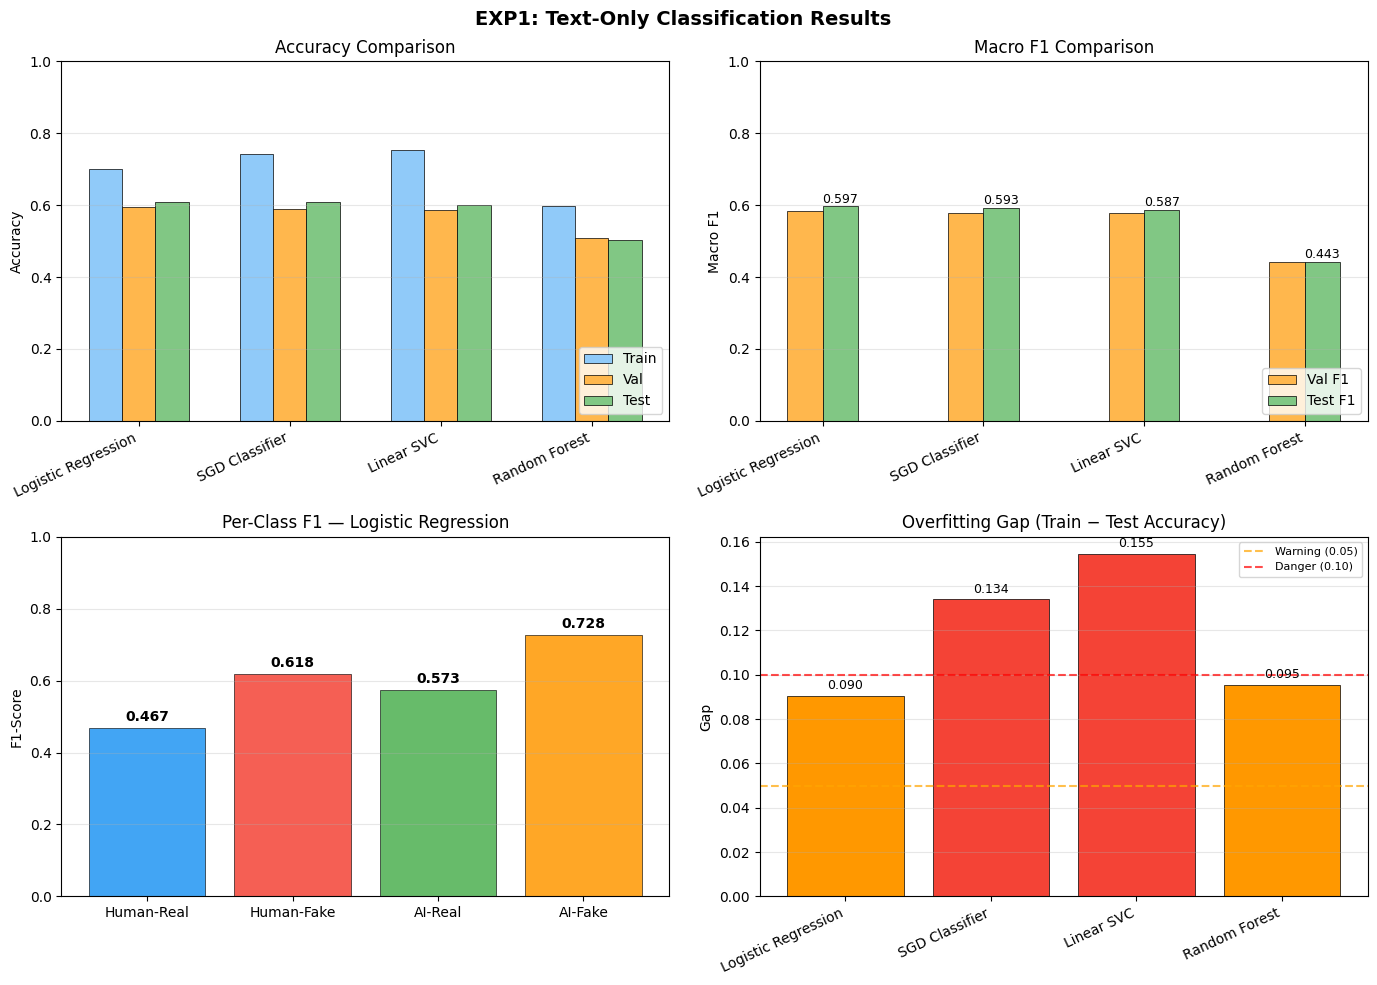

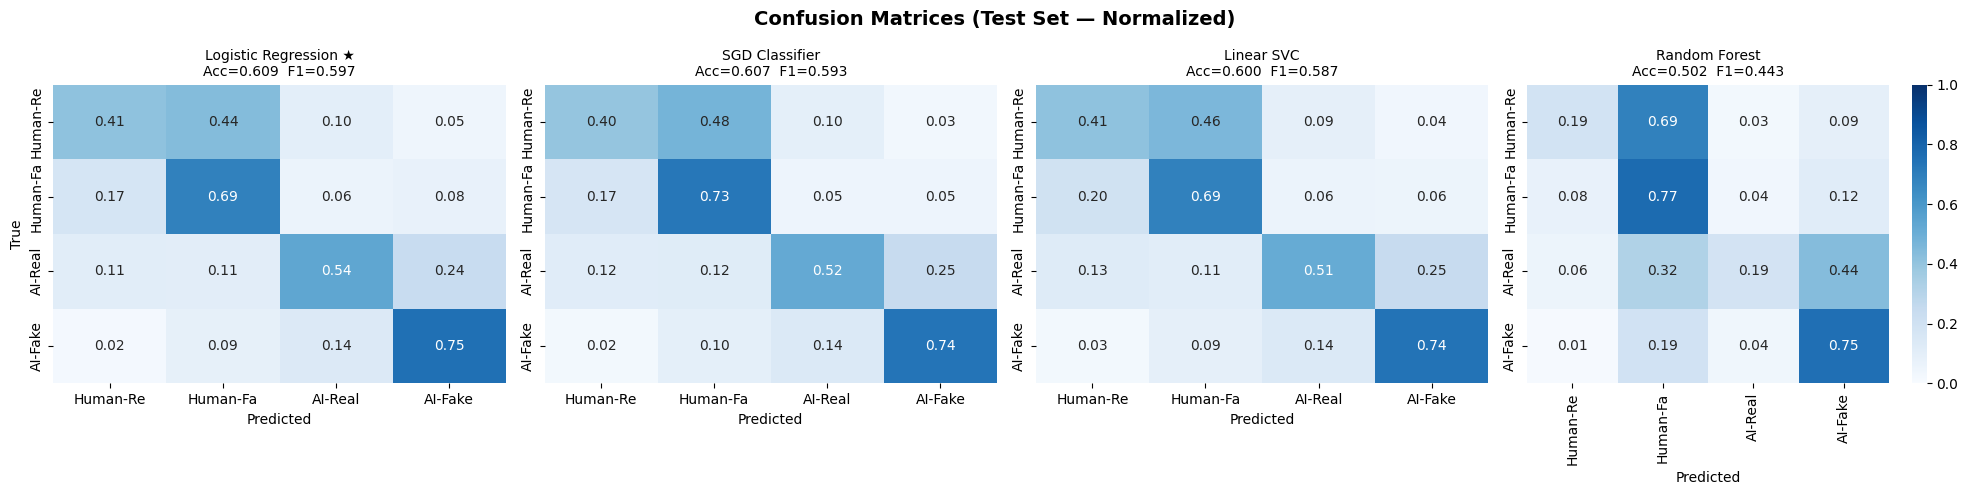

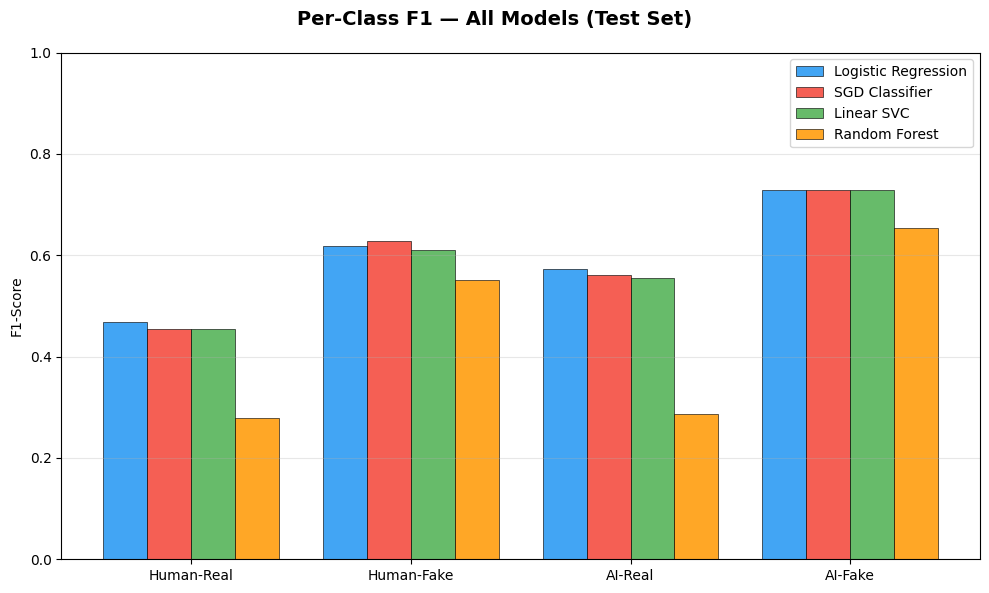

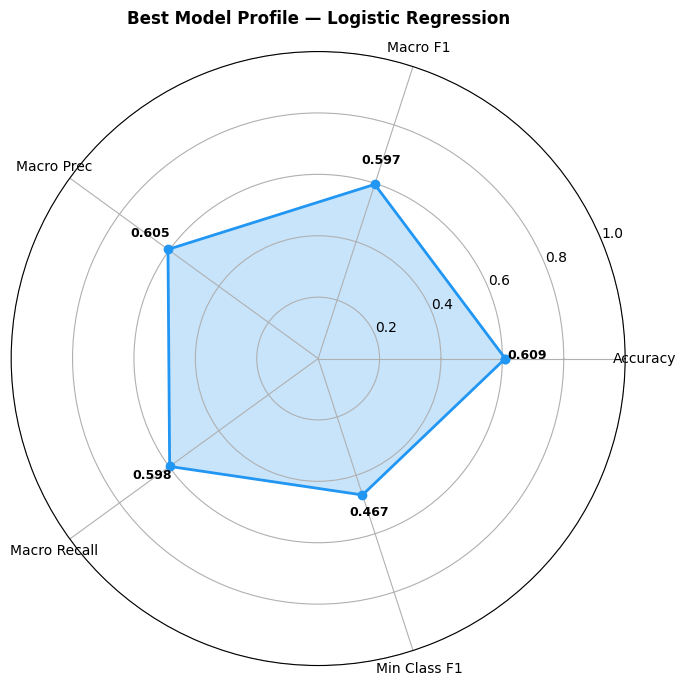


Plots saved: exp1_step3_1_comparison.png | _confusion_matrices.png | _perclass_f1.png | _radar.png
Results saved → exp1_step3_1_results.json

STEP 4 COMPLETE!


In [9]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from scipy.sparse import issparse, hstack, csr_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import json
from datetime import datetime
import time
import warnings
warnings.filterwarnings('ignore')

try:
    import lightgbm as lgb
    LIGHTGBM_AVAILABLE = True
except ImportError:
    LIGHTGBM_AVAILABLE = False
    print("LightGBM not available — will skip")

try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False


class FourWayTrainer:
    """
    4-way classification trainer for EXP1 (Text-Only).
    Models: LR, LinearSVC, Random Forest, LightGBM
    """

    CLASS_NAMES = ['Human-Real', 'Human-Fake', 'AI-Real', 'AI-Fake']

    def __init__(self):
        self.class_mapping   = {i: n for i, n in enumerate(self.CLASS_NAMES)}
        self.models          = {}
        self.results         = {}
        self.computed_weights= None
        self.training_times  = {}

    # ─────────────────────────────────────────────
    # Class weights
    # ─────────────────────────────────────────────

    def compute_balanced_weights(self, y_train):
        classes = np.unique(y_train)
        weights = compute_class_weight('balanced', classes=classes, y=y_train)
        weight_dict = {int(c): float(w) for c, w in zip(classes, weights)}

        print(f"\nBalanced Class Weights:")
        for cls, w in weight_dict.items():
            count = np.sum(y_train == cls)
            pct   = count / len(y_train) * 100
            print(f"  {self.class_mapping[cls]:15s}: weight={w:.4f}  n={count} ({pct:.1f}%)")

        self.computed_weights = weight_dict
        return weight_dict

    # ─────────────────────────────────────────────
    # Model initialization
    # ─────────────────────────────────────────────
    
    def initialize_models(self):
        print("\nInitializing models...")
    
        models = {}
    
        # 1. Logistic Regression
        models['LogisticRegression'] = {
            'model': LogisticRegression(
                C=1.0,
                max_iter=5000,
                tol=1e-3,
                multi_class='multinomial',
                solver='saga',
                random_state=42,
                n_jobs=-1
            ),
            'name': 'Logistic Regression',
            'needs_scaling': False,
            'needs_dense': False,
            'use_sample_weight': False
        }
    
        # 2. Linear SVC
        models['LinearSVC'] = {
            'model': LinearSVC(
                C=1.0,
                max_iter=5000,
                random_state=42,
                dual=True
            ),
            'name': 'Linear SVC',
            'needs_scaling': False,
            'needs_dense': False,
            'use_sample_weight': False
        }
    
        # 3. Random Forest
        models['RandomForest'] = {
            'model': RandomForestClassifier(
                n_estimators=200,
                max_depth=15,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            ),
            'name': 'Random Forest',
            'needs_scaling': False,
            'needs_dense': True,
            'use_sample_weight': False
        }
    
        # 4. LightGBM
        models['SGDClassifier'] = {
            'model': SGDClassifier(
                loss='log_loss',      # fast logistic-style
                alpha=1e-5,
                max_iter=2000,
                tol=1e-3,
                random_state=42
            ),
            'name': 'SGD Classifier',
            'needs_scaling': False,
            'needs_dense': False,
            'use_sample_weight': False
        }
    
        self.models = models
        return self.models

    # ─────────────────────────────────────────────
    # Data helpers
    # ─────────────────────────────────────────────

    def _to_dense(self, X):
        if issparse(X):
            return X.toarray()
        return np.array(X) if not isinstance(X, np.ndarray) else X

    def _prepare_data(self, X, needs_scaling, needs_dense, scaler=None, fit=False):
        X_out = X

        if needs_dense:
            X_out = self._to_dense(X_out)

        if needs_scaling:
            if scaler is None:
                scaler = StandardScaler(with_mean=not issparse(X_out))
            if fit:
                X_out = scaler.fit_transform(X_out)
            else:
                X_out = scaler.transform(X_out)

        return X_out, scaler

    # ─────────────────────────────────────────────
    # Single model training
    # ─────────────────────────────────────────────

    def train_single_model(self, model_key, model_info,
                           X_train, y_train,
                           X_val,   y_val,
                           X_test,  y_test):

        print(f"\n{'='*60}")
        print(f"Training: {model_info['name']}")
        print(f"{'='*60}")

        start = time.time()
        model = model_info['model']

        X_tr, scaler = self._prepare_data(
            X_train,
            model_info['needs_scaling'],
            model_info['needs_dense'],
            fit=True
        )
        X_v,  _      = self._prepare_data(X_val,  model_info['needs_scaling'], model_info['needs_dense'], scaler=scaler)
        X_te, _      = self._prepare_data(X_test, model_info['needs_scaling'], model_info['needs_dense'], scaler=scaler)

        # Cross-validation
        print("  Running 5-fold cross-validation...")
        cv           = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        cv_scores    = cross_val_score(model, X_tr, y_train, cv=cv, scoring='accuracy',  n_jobs=-1)
        cv_f1_scores = cross_val_score(model, X_tr, y_train, cv=cv, scoring='f1_macro',  n_jobs=-1)
        print(f"  CV Accuracy : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
        print(f"  CV Macro F1 : {cv_f1_scores.mean():.4f} ± {cv_f1_scores.std():.4f}")

        # Full training
        print("  Training on full training set...")
        if model_info.get('use_sample_weight', False):
            sw = compute_sample_weight('balanced', y_train)
            model.fit(X_tr, y_train, sample_weight=sw)
        else:
            model.fit(X_tr, y_train)

        # Predictions
        train_pred = model.predict(X_tr)
        val_pred   = model.predict(X_v)
        test_pred  = model.predict(X_te)

        metrics = self._compute_all_metrics(
            y_train, train_pred,
            y_val,   val_pred,
            y_test,  test_pred
        )

        elapsed = time.time() - start

        # Print
        print(f"\n  Results ({elapsed:.1f}s):")
        print(f"  {'':15s} {'Train':>8} {'Val':>8} {'Test':>8}")
        print(f"  {'Accuracy':15s} {metrics['train_accuracy']:>8.4f} {metrics['val_accuracy']:>8.4f} {metrics['test_accuracy']:>8.4f}")
        print(f"  {'Macro F1':15s} {metrics['train_macro_f1']:>8.4f} {metrics['val_macro_f1']:>8.4f} {metrics['test_macro_f1']:>8.4f}")
        print(f"  {'Weighted F1':15s} {metrics['train_weighted_f1']:>8.4f} {metrics['val_weighted_f1']:>8.4f} {metrics['test_weighted_f1']:>8.4f}")
        print(f"  {'Overfit gap':15s} {metrics['overfit_gap']:>8.4f}")

        print(f"\n  Per-Class Test Metrics:")
        print(f"  {'Class':15s} {'Prec':>8} {'Recall':>8} {'F1':>8} {'N':>6}")
        print(f"  {'-'*50}")
        for cn in self.CLASS_NAMES:
            m = metrics['test_per_class'][cn]
            print(f"  {cn:15s} {m['precision']:>8.4f} {m['recall']:>8.4f} {m['f1-score']:>8.4f} {m['support']:>6}")

        result = {
            'model_name'      : model_info['name'],
            'training_time'   : float(elapsed),
            'cv_accuracy'     : float(cv_scores.mean()),
            'cv_accuracy_std' : float(cv_scores.std()),
            'cv_macro_f1'     : float(cv_f1_scores.mean()),
            'cv_macro_f1_std' : float(cv_f1_scores.std()),
            **metrics,
            'val_pred'        : val_pred,
            'test_pred'       : test_pred,
            'trained_model'   : model,
            'scaler'          : scaler
        }

        self.results[model_key]        = result
        self.training_times[model_key] = elapsed
        return result

    def _compute_all_metrics(self, y_train, train_pred,
                             y_val,   val_pred,
                             y_test,  test_pred):
        metrics = {}

        metrics['train_accuracy']     = accuracy_score(y_train, train_pred)
        metrics['val_accuracy']       = accuracy_score(y_val,   val_pred)
        metrics['test_accuracy']      = accuracy_score(y_test,  test_pred)

        metrics['train_macro_f1']     = f1_score(y_train, train_pred, average='macro',    zero_division=0)
        metrics['val_macro_f1']       = f1_score(y_val,   val_pred,   average='macro',    zero_division=0)
        metrics['test_macro_f1']      = f1_score(y_test,  test_pred,  average='macro',    zero_division=0)

        metrics['train_weighted_f1']  = f1_score(y_train, train_pred, average='weighted', zero_division=0)
        metrics['val_weighted_f1']    = f1_score(y_val,   val_pred,   average='weighted', zero_division=0)
        metrics['test_weighted_f1']   = f1_score(y_test,  test_pred,  average='weighted', zero_division=0)

        metrics['test_macro_precision']= precision_score(y_test, test_pred, average='macro', zero_division=0)
        metrics['test_macro_recall']   = recall_score(y_test,    test_pred, average='macro', zero_division=0)

        metrics['overfit_gap'] = metrics['train_accuracy'] - metrics['test_accuracy']

        report = classification_report(
            y_test, test_pred,
            target_names=self.CLASS_NAMES,
            output_dict=True, zero_division=0
        )
        metrics['test_per_class'] = {
            cn: {
                'precision': float(report[cn]['precision']),
                'recall'   : float(report[cn]['recall']),
                'f1-score' : float(report[cn]['f1-score']),
                'support'  : int(report[cn]['support'])
            } for cn in self.CLASS_NAMES
        }

        class_f1s              = [report[cn]['f1-score'] for cn in self.CLASS_NAMES]
        metrics['min_class_f1']= float(min(class_f1s))
        metrics['max_class_f1']= float(max(class_f1s))

        metrics['val_confusion_matrix'] = confusion_matrix(y_val,  val_pred).tolist()
        metrics['test_confusion_matrix']= confusion_matrix(y_test, test_pred).tolist()

        return metrics

    # ─────────────────────────────────────────────
    # Train all models
    # ─────────────────────────────────────────────

    def train_all_models(self, X_train, y_train,
                         X_val,   y_val,
                         X_test,  y_test):

        total_start = time.time()

        print("\n" + "="*60)
        print("EXP1: TEXT-ONLY 4-WAY CLASSIFICATION")
        print("="*60)
        print(f"  Train  : {X_train.shape}  (sparse={issparse(X_train)})")
        print(f"  Val    : {X_val.shape}")
        print(f"  Test   : {X_test.shape}")
        print(f"  Classes: {self.CLASS_NAMES}")

        self.compute_balanced_weights(y_train)
        self.initialize_models()

        for key, info in self.models.items():
            self.train_single_model(
                key, info,
                X_train, y_train,
                X_val,   y_val,
                X_test,  y_test
            )

        total_time = time.time() - total_start
        print(f"\nTotal training time: {total_time/60:.1f} minutes")
        self.print_summary()
        return self.results

    # ─────────────────────────────────────────────
    # Summary & Reports
    # ─────────────────────────────────────────────

    def print_summary(self):
        sorted_r = sorted(
            self.results.items(),
            key=lambda x: x[1]['test_macro_f1'],
            reverse=True
        )
    
        print("\n" + "="*115)
        print("MODEL COMPARISON — EXP1 (Text-Only)")
        print("="*115)
        print(f"  {'Model':<22} {'CV F1 (±std)':>18} {'Val Acc':>8} {'Val F1':>8} "
              f"{'Test Acc':>9} {'Test F1':>9} {'Gap':>7} {'Time':>6}")
        print("-"*115)
    
        for rank, (key, r) in enumerate(sorted_r, 1):
            marker = "★" if rank == 1 else " "
            # ±std যোগ করা হয়েছে
            cv_f1_str = f"{r['cv_macro_f1']:.4f} ± {r['cv_macro_f1_std']:.4f}"
            print(f"{marker} {r['model_name']:<21}"
                  f"{cv_f1_str:>18}"
                  f"{r['val_accuracy']:>8.4f}"
                  f"{r['val_macro_f1']:>8.4f}"
                  f"{r['test_accuracy']:>9.4f}"
                  f"{r['test_macro_f1']:>9.4f}"
                  f"{r['overfit_gap']:>7.3f}"
                  f"{r['training_time']:>5.0f}s")
    
        best_key, best = sorted_r[0]
        print("\n" + "="*115)
        print(f"  BEST MODEL       : {best['model_name']}")
        print(f"  CV Macro F1      : {best['cv_macro_f1']:.4f} ± {best['cv_macro_f1_std']:.4f}")
        print(f"  Test Accuracy    : {best['test_accuracy']:.4f} ({best['test_accuracy']*100:.2f}%)")
        print(f"  Test Macro F1    : {best['test_macro_f1']:.4f}")
        print(f"  Test Macro Prec  : {best['test_macro_precision']:.4f}")
        print(f"  Test Macro Recall: {best['test_macro_recall']:.4f}")
        print(f"  Min Class F1     : {best['min_class_f1']:.4f}")
        print(f"  Overfit Gap      : {best['overfit_gap']:.4f}")
        print("="*115)
    
        # ── Per-class F1 summary (নতুন) ──────────────────────
        print(f"\n{'─'*75}")
        print("PER-CLASS F1 SUMMARY (Test Set)")
        print(f"{'─'*75}")
        print(f"  {'Model':<22} {'Human-Real':>12} {'Human-Fake':>12} "
              f"{'AI-Real':>10} {'AI-Fake':>10}")
        print(f"  {'─'*68}")
    
        for rank, (key, r) in enumerate(sorted_r, 1):
            marker = "★" if rank == 1 else " "
            hr = r['test_per_class']['Human-Real']['f1-score']
            hf = r['test_per_class']['Human-Fake']['f1-score']
            ar = r['test_per_class']['AI-Real']['f1-score']
            af = r['test_per_class']['AI-Fake']['f1-score']
            print(f"{marker} {r['model_name']:<21}"
                  f"{hr:>12.4f}"
                  f"{hf:>12.4f}"
                  f"{ar:>10.4f}"
                  f"{af:>10.4f}")
        print(f"{'─'*75}")

    def print_best_report(self):
        best_key = max(self.results, key=lambda k: self.results[k]['test_macro_f1'])
        best     = self.results[best_key]

        print(f"\n{'='*60}")
        print(f"DETAILED REPORT — {best['model_name']}")
        print(f"{'='*60}")
        print(f"\n  Test Accuracy    : {best['test_accuracy']:.4f}")
        print(f"  Test Macro F1    : {best['test_macro_f1']:.4f}")
        print(f"  Test Weighted F1 : {best['test_weighted_f1']:.4f}")
        print(f"  Test Macro Prec  : {best['test_macro_precision']:.4f}")
        print(f"  Test Macro Recall: {best['test_macro_recall']:.4f}")

        print(f"\n  Per-Class Metrics (Test):")
        print(f"  {'Class':15s} {'Precision':>10} {'Recall':>10} {'F1-Score':>10} {'Support':>10}")
        print(f"  {'-'*55}")
        for cn in self.CLASS_NAMES:
            m = best['test_per_class'][cn]
            print(f"  {cn:15s} {m['precision']:>10.4f} {m['recall']:>10.4f} "
                  f"{m['f1-score']:>10.4f} {m['support']:>10}")

        print(f"\n  Confusion Matrix (Test):")
        cm     = np.array(best['test_confusion_matrix'])
        header = f"  {'Predicted →':15s}" + "".join(f"{n[:10]:>12s}" for n in self.CLASS_NAMES)
        print(header)
        print(f"  {'Actual ↓':15s}")
        for i, row in enumerate(cm):
            print(f"  {self.CLASS_NAMES[i]:15s}" + "".join(f"{v:>12d}" for v in row))

    # ─────────────────────────────────────────────
    # Visualizations
    # ─────────────────────────────────────────────

    def plot_results(self, save_prefix='exp1'):

        sorted_r    = sorted(self.results.items(), key=lambda x: x[1]['test_macro_f1'], reverse=True)
        model_names = [r['model_name'] for _, r in sorted_r]
        n_models    = len(model_names)
        x           = np.arange(n_models)
        width       = 0.22

        # ── Figure 1: Main comparison ──────────────────────
        fig1, axes = plt.subplots(2, 2, figsize=(14, 10))
        fig1.suptitle('EXP1: Text-Only Classification Results', fontsize=14, fontweight='bold')

        # Accuracy
        axes[0,0].bar(x-width, [r['train_accuracy'] for _,r in sorted_r], width, label='Train', color='#90CAF9', edgecolor='black', linewidth=0.5)
        axes[0,0].bar(x,       [r['val_accuracy']   for _,r in sorted_r], width, label='Val',   color='#FFB74D', edgecolor='black', linewidth=0.5)
        axes[0,0].bar(x+width, [r['test_accuracy']  for _,r in sorted_r], width, label='Test',  color='#81C784', edgecolor='black', linewidth=0.5)
        axes[0,0].set_title('Accuracy Comparison')
        axes[0,0].set_xticks(x)
        axes[0,0].set_xticklabels(model_names, rotation=25, ha='right')
        axes[0,0].set_ylabel('Accuracy')
        axes[0,0].legend(loc='lower right')
        axes[0,0].grid(axis='y', alpha=0.3)
        axes[0,0].set_ylim(0, 1)

        # Macro F1
        axes[0,1].bar(x-width/2, [r['val_macro_f1']  for _,r in sorted_r], width, label='Val F1',  color='#FFB74D', edgecolor='black', linewidth=0.5)
        axes[0,1].bar(x+width/2, [r['test_macro_f1'] for _,r in sorted_r], width, label='Test F1', color='#81C784', edgecolor='black', linewidth=0.5)
        axes[0,1].set_title('Macro F1 Comparison')
        axes[0,1].set_xticks(x)
        axes[0,1].set_xticklabels(model_names, rotation=25, ha='right')
        axes[0,1].set_ylabel('Macro F1')
        axes[0,1].legend(loc='lower right')
        axes[0,1].grid(axis='y', alpha=0.3)
        axes[0,1].set_ylim(0, 1)
        for i, (_, r) in enumerate(sorted_r):
            axes[0,1].text(i+width/2, r['test_macro_f1']+0.01,
                           f"{r['test_macro_f1']:.3f}", ha='center', fontsize=9)

        # Per-class F1 (best model)
        best = sorted_r[0][1]
        f1_scores = [best['test_per_class'][cn]['f1-score'] for cn in self.CLASS_NAMES]
        colors    = ['#2196F3', '#F44336', '#4CAF50', '#FF9800']
        bars = axes[1,0].bar(self.CLASS_NAMES, f1_scores, color=colors, edgecolor='black', linewidth=0.5, alpha=0.85)
        axes[1,0].set_title(f'Per-Class F1 — {best["model_name"]}')
        axes[1,0].set_ylabel('F1-Score')
        axes[1,0].set_ylim(0, 1)
        axes[1,0].grid(axis='y', alpha=0.3)
        for bar, v in zip(bars, f1_scores):
            axes[1,0].text(bar.get_x()+bar.get_width()/2, v+0.02,
                           f'{v:.3f}', ha='center', fontsize=10, fontweight='bold')

        # Overfitting gap
        gaps       = [r['overfit_gap'] for _, r in sorted_r]
        gap_colors = ['#F44336' if g > 0.1 else '#FF9800' if g > 0.05 else '#4CAF50' for g in gaps]
        axes[1,1].bar(model_names, gaps, color=gap_colors, edgecolor='black', linewidth=0.5)
        axes[1,1].set_title('Overfitting Gap (Train − Test Accuracy)')
        axes[1,1].set_ylabel('Gap')
        axes[1,1].axhline(y=0.05, color='orange', linestyle='--', alpha=0.7, label='Warning (0.05)')
        axes[1,1].axhline(y=0.10, color='red',    linestyle='--', alpha=0.7, label='Danger (0.10)')
        axes[1,1].legend(fontsize=8)
        axes[1,1].set_xticklabels(model_names, rotation=25, ha='right')
        axes[1,1].grid(axis='y', alpha=0.3)
        for i, g in enumerate(gaps):
            axes[1,1].text(i, g+0.003, f'{g:.3f}', ha='center', fontsize=9)

        plt.tight_layout()
        plt.savefig(f'{save_prefix}_comparison.png', dpi=300, bbox_inches='tight')
        plt.show()

        # ── Figure 2: Confusion matrices ───────────────────
        fig2, axes2 = plt.subplots(1, n_models, figsize=(5*n_models, 5))
        fig2.suptitle('Confusion Matrices (Test Set — Normalized)', fontsize=14, fontweight='bold')
        if n_models == 1:
            axes2 = [axes2]

        for idx, (key, r) in enumerate(sorted_r):
            cm      = np.array(r['test_confusion_matrix'])
            cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
            sns.heatmap(
                cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=[n[:8] for n in self.CLASS_NAMES],
                yticklabels=[n[:8] for n in self.CLASS_NAMES],
                ax=axes2[idx], vmin=0, vmax=1,
                cbar=(idx == n_models-1)
            )
            marker = " ★" if idx == 0 else ""
            axes2[idx].set_title(
                f"{r['model_name']}{marker}\n"
                f"Acc={r['test_accuracy']:.3f}  F1={r['test_macro_f1']:.3f}",
                fontsize=10
            )
            axes2[idx].set_ylabel('True' if idx == 0 else '')
            axes2[idx].set_xlabel('Predicted')

        plt.tight_layout()
        plt.savefig(f'{save_prefix}_confusion_matrices.png', dpi=300, bbox_inches='tight')
        plt.show()

        # ── Figure 3: Per-class F1 all models ──────────────
        fig3, ax3 = plt.subplots(figsize=(10, 6))
        fig3.suptitle('Per-Class F1 — All Models (Test Set)', fontsize=14, fontweight='bold')

        x_class     = np.arange(len(self.CLASS_NAMES))
        width_class = 0.8 / n_models
        colors_m    = ['#2196F3', '#F44336', '#4CAF50', '#FF9800']

        for idx, (key, r) in enumerate(sorted_r):
            f1s = [r['test_per_class'][cn]['f1-score'] for cn in self.CLASS_NAMES]
            ax3.bar(x_class + idx*width_class, f1s, width_class,
                    label=r['model_name'],
                    color=colors_m[idx % len(colors_m)],
                    edgecolor='black', linewidth=0.5, alpha=0.85)

        ax3.set_ylabel('F1-Score')
        ax3.set_xticks(x_class + width_class*(n_models-1)/2)
        ax3.set_xticklabels(self.CLASS_NAMES)
        ax3.set_ylim(0, 1)
        ax3.legend(loc='upper right')
        ax3.grid(axis='y', alpha=0.3)
        plt.tight_layout()
        plt.savefig(f'{save_prefix}_perclass_f1.png', dpi=300, bbox_inches='tight')
        plt.show()

        # ── Figure 4: Radar chart (best model) ─────────────
        fig4, ax4 = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
        radar_metrics = ['Accuracy', 'Macro F1', 'Macro Prec', 'Macro Recall', 'Min Class F1']
        radar_values  = [
            best['test_accuracy'],
            best['test_macro_f1'],
            best['test_macro_precision'],
            best['test_macro_recall'],
            best['min_class_f1']
        ]
        angles = np.linspace(0, 2*np.pi, len(radar_metrics), endpoint=False).tolist()
        angles       += [angles[0]]
        radar_values += [radar_values[0]]

        ax4.fill(angles, radar_values, color='#2196F3', alpha=0.25)
        ax4.plot(angles, radar_values, color='#2196F3', linewidth=2, marker='o', markersize=6)
        ax4.set_xticks(angles[:-1])
        ax4.set_xticklabels(radar_metrics, fontsize=10)
        ax4.set_ylim(0, 1)
        ax4.set_title(f'Best Model Profile — {best["model_name"]}',
                      fontsize=12, fontweight='bold', pad=20)
        for angle, value in zip(angles[:-1], radar_values[:-1]):
            ax4.text(angle, value+0.07, f'{value:.3f}', ha='center', fontsize=9, fontweight='bold')

        plt.tight_layout()
        plt.savefig(f'{save_prefix}_radar.png', dpi=300, bbox_inches='tight')
        plt.show()

        print(f"\nPlots saved: {save_prefix}_comparison.png | _confusion_matrices.png | _perclass_f1.png | _radar.png")

    # ─────────────────────────────────────────────
    # Save
    # ─────────────────────────────────────────────

    def save_results(self, filepath='exp1_results.json'):
        save_data = {
            'timestamp'       : datetime.now().isoformat(),
            'experiment'      : 'EXP1 — Text Only (F1+F2+F8)',
            'feature_families': 'F1 (Lexical TF-IDF) + F2 (Char N-grams) + F8 (Punctuation)',
            'class_mapping'   : self.class_mapping,
            'computed_weights': {str(k): v for k, v in self.computed_weights.items()},
            'models': {
                k: {kk: vv for kk, vv in v.items()
                    if kk not in ['trained_model', 'scaler', 'val_pred', 'test_pred']}
                for k, v in self.results.items()
            }
        }
        with open(filepath, 'w') as f:
            json.dump(save_data, f, indent=2)
        print(f"Results saved → {filepath}")


# ============================================================
# RUN EXP1
# ============================================================

# ============================================================
# RUN STEP 4 AFTER STEP 3.1
# ============================================================

if 'step3_1_results' in globals():
    
    best_k = step3_1_results['best']['k']
    
    print("="*60)
    print("PREPARING STEP 4 DATA FROM STEP 3.1 RESULTS")
    print("="*60)
    print(f"  Best text experiment : {step3_1_results['best']['best_exp']}")
    print(f"  Families            : {step3_1_results['best']['families']}")
    print(f"  Selected k          : {best_k}")
    print(f"  Val Macro F1        : {step3_1_results['best']['val_macro_f1']:.4f}")
    print(f"  Test Macro F1       : {step3_1_results['best']['test_macro_f1']:.4f}")
    
    X_train = step3_1_results['best']['X_train']
    X_val   = step3_1_results['best']['X_val']
    X_test  = step3_1_results['best']['X_test']
    
    y_train = step3_1_results['best']['y_train']
    y_val   = step3_1_results['best']['y_val']
    y_test  = step3_1_results['best']['y_test']
    
    print(f"\n  X_train : {X_train.shape}  sparse={issparse(X_train)}")
    print(f"  X_val   : {X_val.shape}")
    print(f"  X_test  : {X_test.shape}")
    
    trainer = FourWayTrainer()
    exp1_results = trainer.train_all_models(
        X_train, y_train,
        X_val, y_val,
        X_test, y_test
    )
    
    trainer.print_best_report()
    trainer.plot_results(save_prefix='exp1_step3_1')
    trainer.save_results('exp1_step3_1_results.json')
    
    print("\n" + "="*60)
    print("STEP 4 COMPLETE!")
    print("="*60)

else:
    print("ERROR: Run Step 3.1 first!")


FEATURE IMPORTANCE ANALYSIS — EXP1 (LR Coefficients)
  LR coefficient shape : (4, 4000)
  Classes              : ['Human-Real', 'Human-Fake', 'AI-Real', 'AI-Fake']

  Best text families   : ['f1', 'f2', 'f8']
  Total feature names  : 10011
  Chi-sq mask length   : 10011
  LR coef columns      : 4000
  Final feature names  : 4000


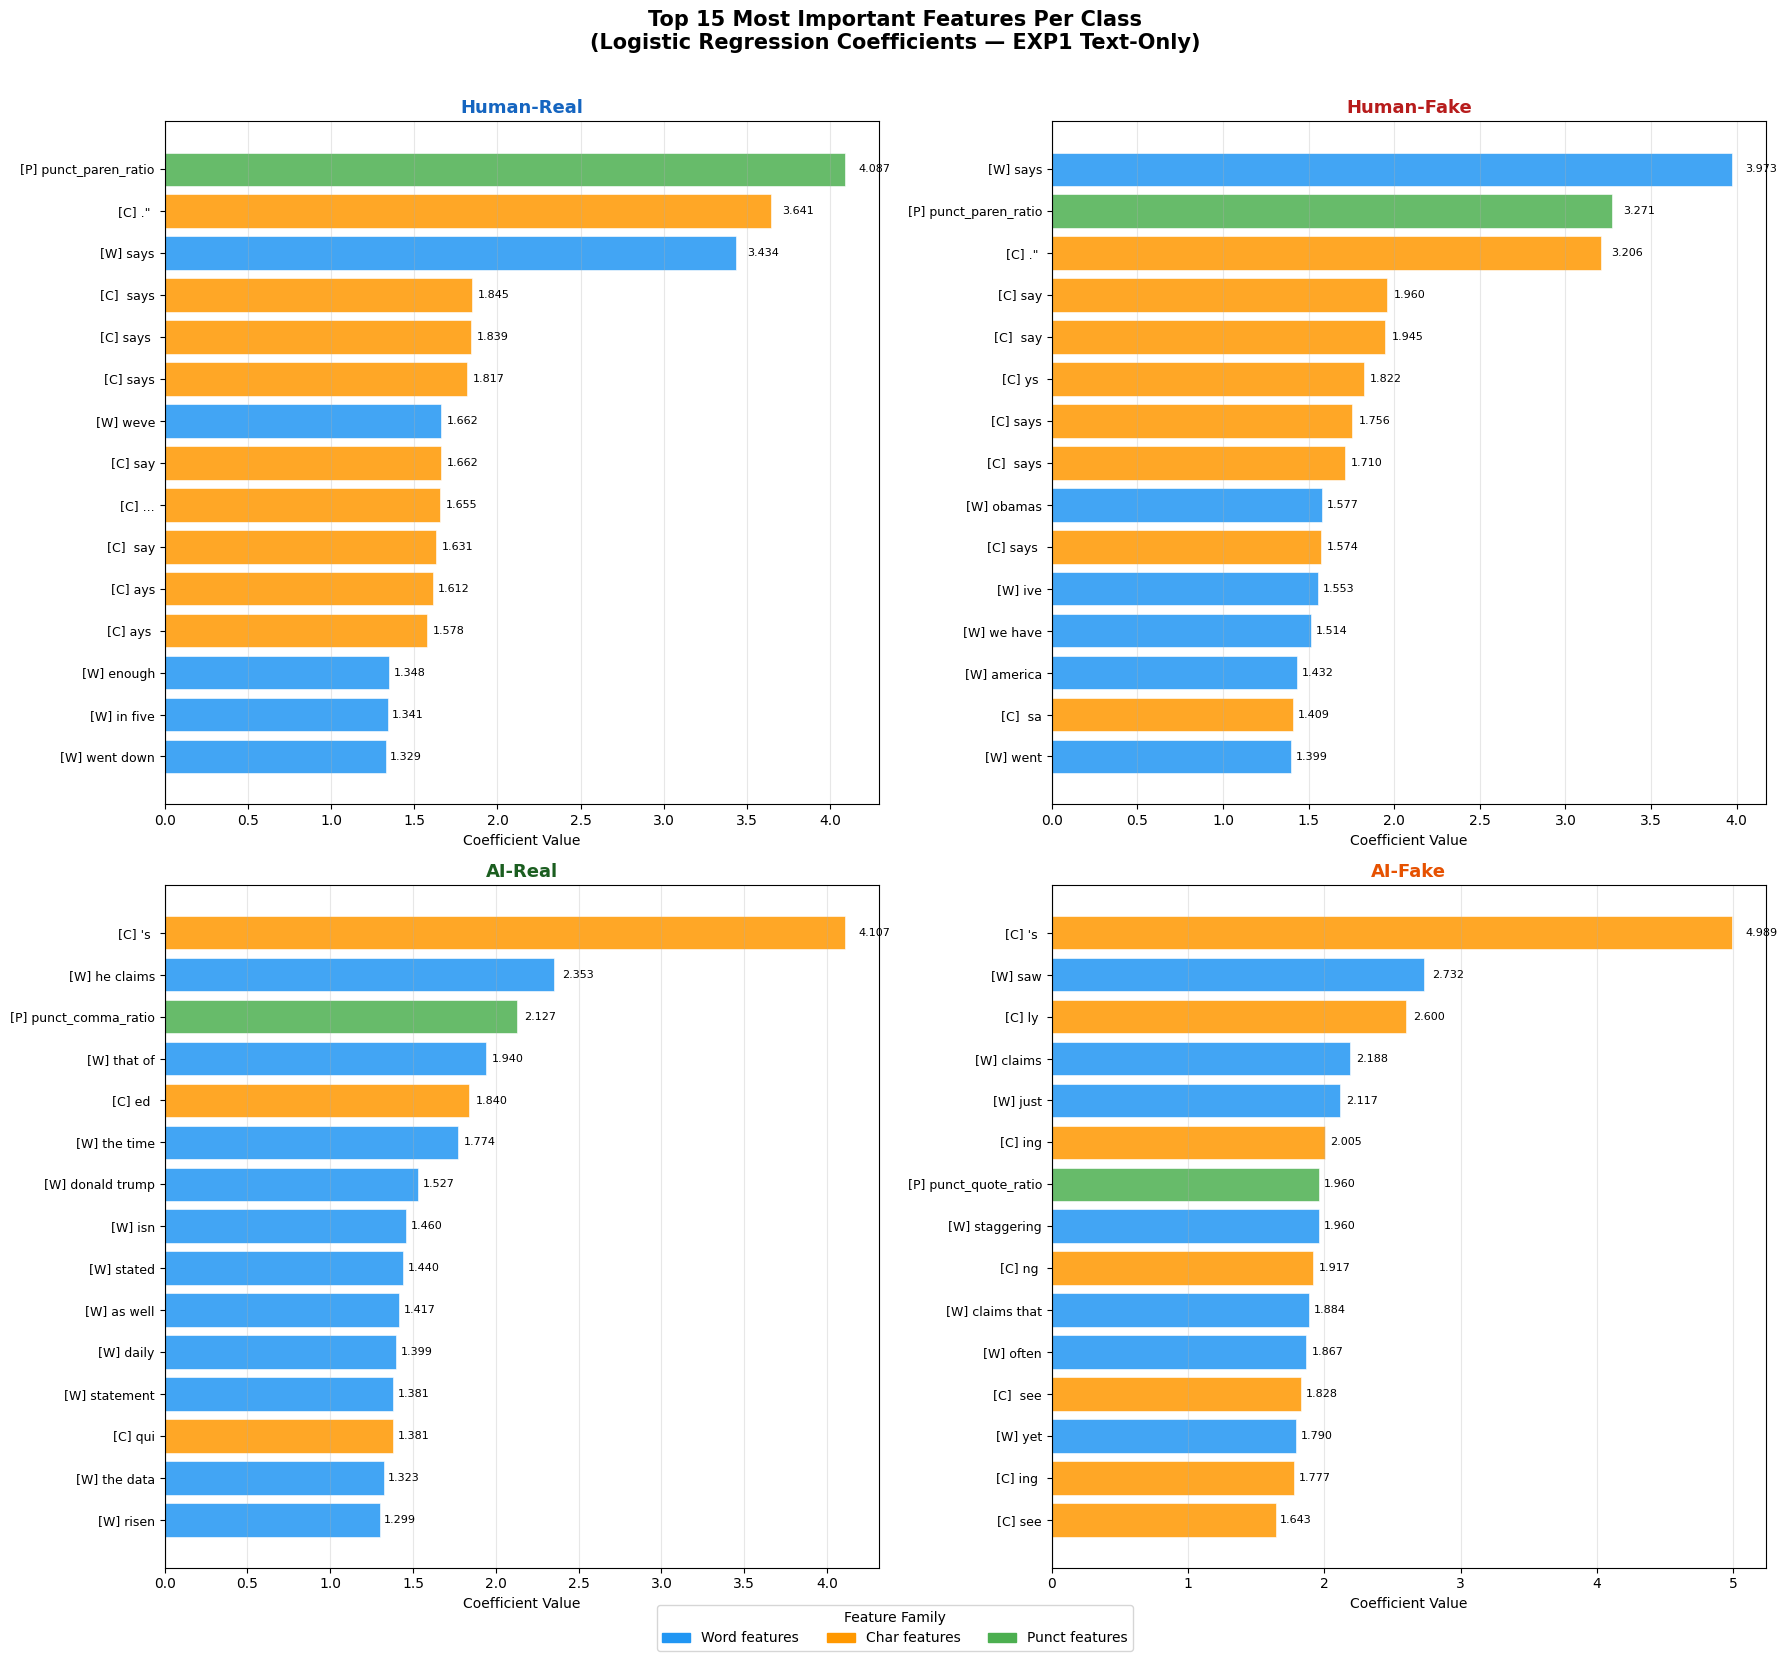


  Saved → exp1_feature_importance_per_class.png


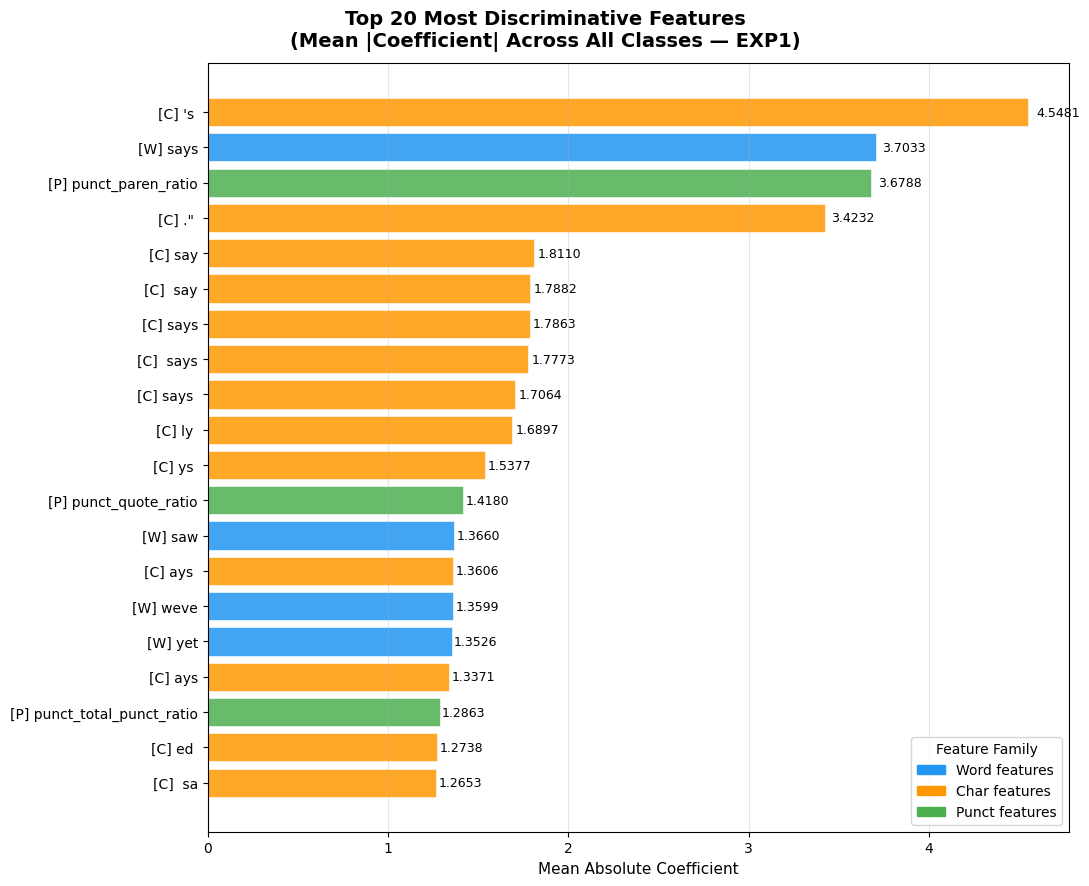

  Saved → exp1_feature_importance_overall.png

────────────────────────────────────────────────────────────
FEATURE FAMILY CONTRIBUTION (Top 20 Overall)
────────────────────────────────────────────────────────────
  char      : █████████████ (13/20)
  word      : ████ (4/20)
  punct     : ███ (3/20)

────────────────────────────────────────────────────────────
TOP 5 FEATURES PER CLASS
────────────────────────────────────────────────────────────

  Human-Real:
    1. [P] punct_paren_ratio                coef = +4.0868
    2. [C] ."                               coef = +3.6406
    3. [W] says                             coef = +3.4339
    4. [C]  says                            coef = +1.8448
    5. [C] says                             coef = +1.8387

  Human-Fake:
    1. [W] says                             coef = +3.9727
    2. [P] punct_paren_ratio                coef = +3.2709
    3. [C] ."                               coef = +3.2059
    4. [C] say                              coef 

In [10]:
# ============================================================
# FEATURE IMPORTANCE ANALYSIS (EXP1)
# LR Coefficient Analysis — Per Class + Overall
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')


def plot_feature_importance_exp1(trainer, runner, step3_1_results,
                                  top_n=15, save_prefix='feature_importance'):
    """
    Extract and visualize top features from Logistic Regression (EXP1).

    Shows:
    1. Top features per class (4 subplots)
    2. Top overall discriminative features (mean absolute coefficient)
    """

    print("\n" + "="*70)
    print("FEATURE IMPORTANCE ANALYSIS — EXP1 (LR Coefficients)")
    print("="*70)

    # ── Step 1: Get LR model ──────────────────────────────
    lr_result = trainer.results.get('LogisticRegression', None)
    if lr_result is None:
        print("ERROR: Logistic Regression result not found!")
        return None

    lr_model = lr_result['trained_model']
    print(f"  LR coefficient shape : {lr_model.coef_.shape}")
    print(f"  Classes              : {trainer.CLASS_NAMES}")

    # ── Step 2: Build feature name list ───────────────────
    # Best families from ablation
    best_exp = max(runner.results,
                   key=lambda k: runner.results[k]['val_macro_f1'])
    families = runner.results[best_exp]['families']
    print(f"\n  Best text families   : {families}")

    feature_names = []

    for fam in families:
        if fam == 'f1':
            vocab = runner.f1.vectorizer.get_feature_names_out()
            feature_names.extend([f'word::{v}' for v in vocab])

        elif fam == 'f2':
            vocab = runner.f2.vectorizer.get_feature_names_out()
            feature_names.extend([f'char::{v}' for v in vocab])

        elif fam == 'f8':
            sample_f8 = runner._dense_cache['train']['f8']
            feature_names.extend([f'punct::{c}' for c in sample_f8.columns])

        elif fam == 'f3':
            sample_f3 = runner._dense_cache['train']['f3']
            feature_names.extend([f'struct::{c}' for c in sample_f3.columns])

        elif fam == 'f4':
            sample_f4 = runner._dense_cache['train']['f4']
            feature_names.extend([f'vocab::{c}' for c in sample_f4.columns])

        elif fam == 'f5':
            sample_f5 = runner._dense_cache['train']['f5']
            feature_names.extend([f'read::{c}' for c in sample_f5.columns])

        elif fam == 'f6':
            sample_f6 = runner._dense_cache['train']['f6']
            feature_names.extend([f'pos::{c}' for c in sample_f6.columns])

        elif fam == 'f7':
            sample_f7 = runner._dense_cache['train']['f7']
            feature_names.extend([f'sent::{c}' for c in sample_f7.columns])

    print(f"  Total feature names  : {len(feature_names)}")

    # ── Step 3: Apply chi-square selection mask ────────────
    selector = step3_1_results['best']['selector']
    selected_mask = selector.get_support()

    print(f"  Chi-sq mask length   : {len(selected_mask)}")
    print(f"  LR coef columns      : {lr_model.coef_.shape[1]}")

    if len(feature_names) >= len(selected_mask):
        selected_names = [
            feature_names[i]
            for i, sel in enumerate(selected_mask) if sel
        ]
    else:
        print("  Warning: feature name mismatch — using generic names")
        selected_names = [f'feature_{i}' for i in range(lr_model.coef_.shape[1])]

    # Trim or pad if needed
    n_coef = lr_model.coef_.shape[1]
    if len(selected_names) > n_coef:
        selected_names = selected_names[:n_coef]
    elif len(selected_names) < n_coef:
        selected_names += [f'feature_{i}' for i in range(len(selected_names), n_coef)]

    print(f"  Final feature names  : {len(selected_names)}")

    # ── Step 4: Color mapping by feature family ────────────
    FAMILY_COLORS = {
        'word'   : '#2196F3',   # Blue
        'char'   : '#FF9800',   # Orange
        'punct'  : '#4CAF50',   # Green
        'struct' : '#9C27B0',   # Purple
        'vocab'  : '#F44336',   # Red
        'read'   : '#00BCD4',   # Cyan
        'pos'    : '#795548',   # Brown
        'sent'   : '#607D8B',   # Grey-Blue
    }

    def get_color(name):
        prefix = name.split('::')[0] if '::' in name else 'other'
        return FAMILY_COLORS.get(prefix, '#9E9E9E')

    def clean_name(name, max_len=28):
        """Clean feature name for display"""
        if '::' in name:
            prefix, val = name.split('::', 1)
            short_prefix = {
                'word': 'W', 'char': 'C', 'punct': 'P',
                'struct': 'ST', 'vocab': 'V', 'read': 'R',
                'pos': 'POS', 'sent': 'SN'
            }.get(prefix, prefix[:2].upper())
            display = f"[{short_prefix}] {val}"
        else:
            display = name
        return display[:max_len] + '...' if len(display) > max_len else display

    # ── Step 5: Per-class top features ────────────────────
    CLASS_NAMES = trainer.CLASS_NAMES
    CLASS_COLORS = ['#1565C0', '#B71C1C', '#1B5E20', '#E65100']

    fig1, axes = plt.subplots(2, 2, figsize=(18, 16))
    fig1.suptitle(
        f'Top {top_n} Most Important Features Per Class\n'
        f'(Logistic Regression Coefficients — EXP1 Text-Only)',
        fontsize=15, fontweight='bold', y=1.01
    )

    importance_data = {}

    for idx, (class_name, cls_color) in enumerate(zip(CLASS_NAMES, CLASS_COLORS)):
        ax = axes[idx // 2][idx % 2]

        coefs = lr_model.coef_[idx]
        top_idx = np.argsort(coefs)[-top_n:][::-1]

        top_names   = [selected_names[i] for i in top_idx]
        top_values  = coefs[top_idx]
        top_display = [clean_name(n) for n in top_names]
        top_colors  = [get_color(n) for n in top_names]

        y_pos = np.arange(len(top_display))
        bars  = ax.barh(y_pos, top_values,
                        color=top_colors, alpha=0.85,
                        edgecolor='white', linewidth=0.5)

        ax.set_yticks(y_pos)
        ax.set_yticklabels(top_display, fontsize=9)
        ax.set_xlabel('Coefficient Value', fontsize=10)
        ax.set_title(f'{class_name}', fontsize=13,
                     fontweight='bold', color=cls_color)
        ax.invert_yaxis()
        ax.grid(axis='x', alpha=0.3)
        ax.axvline(x=0, color='black', linewidth=0.8, alpha=0.5)

        for bar, val in zip(bars, top_values):
            ax.text(val + abs(val) * 0.02,
                    bar.get_y() + bar.get_height() / 2,
                    f'{val:.3f}', va='center', fontsize=8)

        importance_data[class_name] = {
            'features'     : top_names,
            'display_names': top_display,
            'coefficients' : top_values.tolist()
        }

    # Legend for feature families
    legend_handles = [
        mpatches.Patch(color=c, label=f'{k.capitalize()} features')
        for k, c in FAMILY_COLORS.items()
        if any(n.startswith(k + '::') for n in selected_names)
    ]
    fig1.legend(handles=legend_handles,
                loc='lower center', ncol=4,
                fontsize=10, bbox_to_anchor=(0.5, -0.02),
                title='Feature Family', title_fontsize=10)

    plt.tight_layout()
    plt.savefig(f'{save_prefix}_per_class.png',
                dpi=300, bbox_inches='tight')
    plt.show()
    print(f"\n  Saved → {save_prefix}_per_class.png")

    # ── Step 6: Overall top features ──────────────────────
    mean_abs_coef = np.mean(np.abs(lr_model.coef_), axis=0)
    top_n_overall = 20
    top_overall_idx    = np.argsort(mean_abs_coef)[-top_n_overall:][::-1]
    top_overall_names  = [selected_names[i] for i in top_overall_idx]
    top_overall_values = mean_abs_coef[top_overall_idx]
    top_overall_display= [clean_name(n, max_len=35) for n in top_overall_names]
    top_overall_colors = [get_color(n) for n in top_overall_names]

    fig2, ax2 = plt.subplots(figsize=(11, 9))
    fig2.suptitle(
        f'Top {top_n_overall} Most Discriminative Features\n'
        f'(Mean |Coefficient| Across All Classes — EXP1)',
        fontsize=14, fontweight='bold'
    )

    y_pos = np.arange(len(top_overall_display))
    bars  = ax2.barh(y_pos, top_overall_values,
                     color=top_overall_colors, alpha=0.85,
                     edgecolor='white', linewidth=0.5)

    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(top_overall_display, fontsize=10)
    ax2.set_xlabel('Mean Absolute Coefficient', fontsize=11)
    ax2.invert_yaxis()
    ax2.grid(axis='x', alpha=0.3)

    for bar, val in zip(bars, top_overall_values):
        ax2.text(val + abs(val) * 0.01,
                 bar.get_y() + bar.get_height() / 2,
                 f'{val:.4f}', va='center', fontsize=9)

    legend_handles2 = [
        mpatches.Patch(color=c, label=f'{k.capitalize()} features')
        for k, c in FAMILY_COLORS.items()
        if any(n.startswith(k + '::') for n in top_overall_names)
    ]
    ax2.legend(handles=legend_handles2,
               loc='lower right', fontsize=10,
               title='Feature Family')

    plt.tight_layout()
    plt.savefig(f'{save_prefix}_overall.png',
                dpi=300, bbox_inches='tight')
    plt.show()
    print(f"  Saved → {save_prefix}_overall.png")

    # ── Step 7: Feature family contribution ───────────────
    print(f"\n{'─'*60}")
    print(f"FEATURE FAMILY CONTRIBUTION (Top {top_n_overall} Overall)")
    print(f"{'─'*60}")

    family_counts = {}
    for name in top_overall_names:
        prefix = name.split('::')[0] if '::' in name else 'other'
        family_counts[prefix] = family_counts.get(prefix, 0) + 1

    for family, count in sorted(family_counts.items(),
                                  key=lambda x: x[1], reverse=True):
        bar_str = '█' * count
        print(f"  {family:<10}: {bar_str} ({count}/{top_n_overall})")

    # ── Step 8: Print top 5 per class ─────────────────────
    print(f"\n{'─'*60}")
    print("TOP 5 FEATURES PER CLASS")
    print(f"{'─'*60}")

    for class_name in CLASS_NAMES:
        data = importance_data[class_name]
        print(f"\n  {class_name}:")
        for i, (feat, coef) in enumerate(
            zip(data['display_names'][:5], data['coefficients'][:5])
        ):
            print(f"    {i+1}. {feat:<35s}  coef = {coef:+.4f}")

    print(f"\n{'='*70}")
    print("FEATURE IMPORTANCE ANALYSIS COMPLETE")
    print(f"{'='*70}")

    return importance_data


# ============================================================
# RUN FEATURE IMPORTANCE
# ============================================================

if 'trainer' in globals() and 'runner' in globals() and 'step3_1_results' in globals():

    importance_data = plot_feature_importance_exp1(
        trainer         = trainer,
        runner          = runner,
        step3_1_results = step3_1_results,
        top_n           = 15,
        save_prefix     = 'exp1_feature_importance'
    )

else:
    print("ERROR: Required variables not found!")
    print("  Need: trainer, runner, step3_1_results")

EXP 2 Adding metadata

Starting EXP2 pipeline...

EXP2 PIPELINE: TEXT SELECTION + CREDIBILITY METADATA

Best EXP1 text setup : F1+F2+F8: +Punctuation
Feature families     : ['f1', 'f2', 'f8']

STEP 3.1: WITHIN-FAMILY TEXT FEATURE SELECTION
Original feature count: 10011
Testing k values: [1000, 2000, 3000, 4000, 5000]

k             Val Acc   Val Macro F1   Test Acc  Test Macro F1
------------------------------------------------------------
1000           0.5562         0.5376     0.5740         0.5546 ←
2000           0.5739         0.5600     0.6040         0.5892 ←
3000           0.5788         0.5657     0.6055         0.5910 ←
4000           0.5951         0.5847     0.6095         0.5966 ←
5000           0.5897         0.5797     0.6006         0.5879

BEST k = 4000
  Val  Accuracy : 0.5951
  Val  Macro F1 : 0.5847
  Test Accuracy : 0.6095
  Test Macro F1 : 0.5966

Selected text features: 4000

Extracting training metadata...

FITTING CREDIBILITY METADATA EXTRACTOR
Training samples: 16215
Global credibi

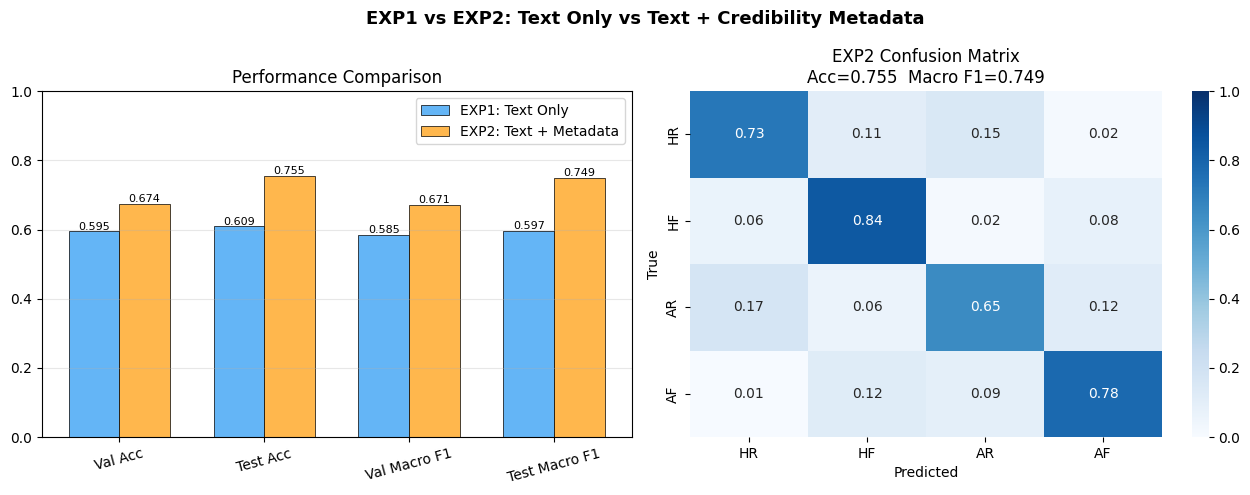


Plot saved → exp2_results.png


In [11]:
# ============================================================
# EXP2: TEXT + CREDIBILITY METADATA
# (Your original approach + Step 3.1 text feature selection)
# ============================================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)
from scipy.sparse import csr_matrix, hstack, issparse
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


# ============================================================
# STEP 3.1: TEXT FEATURE SELECTION
# ============================================================

class TextFeatureSelector:
    """
    Step 3.1: Within-family text feature selection.
    Selects top-k features from F1+F2+F8 using chi-square.
    Fitted on train only, applied to val/test.
    """
    
    def __init__(self, k_values=[3000, 5000, 7000, 10000]):
        self.k_values = k_values
        self.best_k = None
        self.selector = None
        self.selection_results = []
    
    def fit_select(self, X_train, y_train, X_val, y_val, X_test):
        """Try different k values, select best by val Macro F1"""
        
        print("\n" + "="*70)
        print("STEP 3.1: WITHIN-FAMILY TEXT FEATURE SELECTION")
        print("="*70)
        print(f"Original feature count: {X_train.shape[1]}")
        print(f"Testing k values: {self.k_values}")
        print()
        
        best_val_f1 = -1
        best_selector = None
        best_k = None
        
        print(f"{'k':<10} {'Val Acc':>10} {'Val Macro F1':>14} {'Test Acc':>10} {'Test Macro F1':>14}")
        print("-"*60)
        
        for k in self.k_values:
            k_eff = min(k, X_train.shape[1])
            
            selector = SelectKBest(score_func=chi2, k=k_eff)
            X_tr_sel = selector.fit_transform(X_train, y_train)
            X_v_sel  = selector.transform(X_val)
            X_te_sel = selector.transform(X_test)
            
            # Same LR as EXP1
            model = LogisticRegression(
                C=1.0, max_iter=5000, tol=1e-3,
                multi_class='multinomial', solver='saga',
                random_state=42, n_jobs=-1
            )
            model.fit(X_tr_sel, y_train)
            
            val_pred  = model.predict(X_v_sel)
            test_pred = model.predict(X_te_sel)
            
            val_acc  = accuracy_score(y_val,  val_pred)
            val_f1   = f1_score(y_val,  val_pred,  average='macro')
            test_acc = accuracy_score(y_test, test_pred)
            test_f1  = f1_score(y_test, test_pred, average='macro')
            
            marker = " ←" if val_f1 > best_val_f1 else ""
            print(f"{k_eff:<10} {val_acc:>10.4f} {val_f1:>14.4f} "
                  f"{test_acc:>10.4f} {test_f1:>14.4f}{marker}")
            
            self.selection_results.append({
                'k': k_eff,
                'val_accuracy': val_acc,
                'val_macro_f1': val_f1,
                'test_accuracy': test_acc,
                'test_macro_f1': test_f1
            })
            
            if val_f1 > best_val_f1:
                best_val_f1 = val_f1
                best_selector = selector
                best_k = k_eff
                best_val_acc = val_acc
                best_test_acc = test_acc
                best_test_f1 = test_f1
        
        self.best_k = best_k
        self.selector = best_selector
        
        print("\n" + "="*70)
        print(f"BEST k = {best_k}")
        print(f"  Val  Accuracy : {best_val_acc:.4f}")
        print(f"  Val  Macro F1 : {best_val_f1:.4f}")
        print(f"  Test Accuracy : {best_test_acc:.4f}")
        print(f"  Test Macro F1 : {best_test_f1:.4f}")
        print("="*70)
        
        # Apply best selector
        X_train_sel = self.selector.transform(X_train)
        X_val_sel   = self.selector.transform(X_val)
        X_test_sel  = self.selector.transform(X_test)
        
        return X_train_sel, X_val_sel, X_test_sel
    
    def transform(self, X):
        """Apply fitted selector"""
        if self.selector is None:
            raise ValueError("Selector not fitted yet!")
        return self.selector.transform(X)


# ============================================================
# METADATA FEATURE EXTRACTOR (YOUR ORIGINAL APPROACH)
# ============================================================

class CredibilityMetadataExtractor:
    """
    Credibility-based metadata extractor.
    
    Statistics computed from training data only,
    applied to all splits (train/val/test).
    
    This is a standard and widely-used approach in
    fake news and credibility detection literature.
    """
    
    def __init__(self):
        self.speaker_stats = {}
        self.party_stats = {}
        self.subject_stats = {}
        self.context_stats = {}
        self.job_stats = {}
        self.state_stats = {}
        self.label_encoders = {}
        self.global_mean = None
        self.fitted = False
        
        self.class_mapping = {
            0: 'Human-Real',
            1: 'Human-Fake',
            2: 'AI-Real',
            3: 'AI-Fake'
        }
    
    def _compute_credibility(self, df, col):
        """Compute credibility stats for a metadata column"""
        stats = {}
        
        for val in df[col].unique():
            subset = df[df[col] == val]
            total = len(subset)
            real_count = len(subset[subset['label'].isin([0, 2])])
            fake_count = total - real_count
            
            if total > 0:
                stats[val] = {
                    'credibility_score': real_count / total,
                    'fake_rate': fake_count / total,
                    'total_statements': total,
                    'real_count': real_count,
                    'fake_count': fake_count
                }
            else:
                stats[val] = {
                    'credibility_score': self.global_mean,
                    'fake_rate': 1 - self.global_mean,
                    'total_statements': 0,
                    'real_count': 0,
                    'fake_count': 0
                }
        
        return stats
    
    def fit(self, train_df):
        """Fit on training data only"""
        print("\n" + "="*70)
        print("FITTING CREDIBILITY METADATA EXTRACTOR")
        print("="*70)
        print(f"Training samples: {len(train_df)}")
        
        # Global baseline
        real_total = len(train_df[train_df['label'].isin([0, 2])])
        self.global_mean = real_total / len(train_df)
        print(f"Global credibility baseline: {self.global_mean:.4f}")
        
        # Compute stats for each metadata column
        print("\nComputing credibility statistics...")
        self.speaker_stats = self._compute_credibility(train_df, 'speaker')
        self.party_stats   = self._compute_credibility(train_df, 'party_affiliation')
        self.subject_stats = self._compute_credibility(train_df, 'subject')
        self.context_stats = self._compute_credibility(train_df, 'context')
        self.job_stats     = self._compute_credibility(train_df, 'speaker_job_title')
        self.state_stats   = self._compute_credibility(train_df, 'state_info')
        
        print(f"  speaker:           {len(self.speaker_stats)} unique values")
        print(f"  party_affiliation: {len(self.party_stats)} unique values")
        print(f"  subject:           {len(self.subject_stats)} unique values")
        print(f"  context:           {len(self.context_stats)} unique values")
        print(f"  speaker_job_title: {len(self.job_stats)} unique values")
        print(f"  state_info:        {len(self.state_stats)} unique values")
        
        # Fit label encoders
        categorical_cols = [
            'speaker', 'subject', 'party_affiliation',
            'state_info', 'speaker_job_title', 'context'
        ]
        for col in categorical_cols:
            if col in train_df.columns:
                le = LabelEncoder()
                le.fit(train_df[col].fillna('unknown').astype(str))
                self.label_encoders[col] = le
        
        self.fitted = True
        print("\nMetadata extractor fitted successfully!")
        return self
    
    def transform(self, df):
        """Extract metadata features"""
        if not self.fitted:
            raise ValueError("Must fit before transform!")
        
        print(f"  Extracting metadata features from {len(df)} samples...")
        
        features = pd.DataFrame(index=range(len(df)))
        df_reset = df.reset_index(drop=True)
        
        # ====================================================
        # 1. CATEGORICAL ENCODINGS
        # ====================================================
        for col, encoder in self.label_encoders.items():
            if col in df_reset.columns:
                values = df_reset[col].fillna('unknown').astype(str)
                encoded = []
                for val in values:
                    try:
                        encoded.append(encoder.transform([val])[0])
                    except ValueError:
                        encoded.append(0)
                features[f'{col}_encoded'] = encoded
        
        # ====================================================
        # 2. SPEAKER CREDIBILITY
        # ====================================================
        speaker_cred, speaker_fake, speaker_total = [], [], []
        for speaker in df_reset['speaker'].fillna('unknown'):
            s = self.speaker_stats.get(speaker, {
                'credibility_score': self.global_mean,
                'fake_rate': 1 - self.global_mean,
                'total_statements': 0
            })
            speaker_cred.append(s['credibility_score'])
            speaker_fake.append(s['fake_rate'])
            speaker_total.append(s['total_statements'])
        
        features['speaker_credibility']      = speaker_cred
        features['speaker_fake_rate']        = speaker_fake
        features['speaker_statement_count']  = speaker_total
        
        # ====================================================
        # 3. PARTY FEATURES
        # ====================================================
        party_cred, party_fake = [], []
        for party in df_reset['party_affiliation'].fillna('unknown'):
            s = self.party_stats.get(party, {
                'credibility_score': self.global_mean,
                'fake_rate': 1 - self.global_mean
            })
            party_cred.append(s['credibility_score'])
            party_fake.append(s['fake_rate'])
        
        features['party_credibility'] = party_cred
        features['party_fake_rate']   = party_fake
        
        # ====================================================
        # 4. SUBJECT FEATURES
        # ====================================================
        subject_cred, subject_risk = [], []
        for subject in df_reset['subject'].fillna('unknown'):
            s = self.subject_stats.get(subject, {
                'credibility_score': self.global_mean,
                'fake_rate': 1 - self.global_mean
            })
            subject_cred.append(s['credibility_score'])
            subject_risk.append(s['fake_rate'])
        
        features['subject_credibility'] = subject_cred
        features['subject_risk_score']  = subject_risk
        
        # ====================================================
        # 5. CONTEXT FEATURES
        # ====================================================
        context_cred, context_fake = [], []
        for context in df_reset['context'].fillna('unknown'):
            s = self.context_stats.get(context, {
                'credibility_score': self.global_mean,
                'fake_rate': 1 - self.global_mean
            })
            context_cred.append(s['credibility_score'])
            context_fake.append(s['fake_rate'])
        
        features['context_credibility'] = context_cred
        features['context_fake_rate']   = context_fake
        
        # ====================================================
        # 6. JOB TITLE FEATURES
        # ====================================================
        job_cred, job_fake = [], []
        for job in df_reset['speaker_job_title'].fillna('unknown'):
            s = self.job_stats.get(job, {
                'credibility_score': self.global_mean,
                'fake_rate': 1 - self.global_mean
            })
            job_cred.append(s['credibility_score'])
            job_fake.append(s['fake_rate'])
        
        features['job_credibility'] = job_cred
        features['job_fake_rate']   = job_fake
        
        # ====================================================
        # 7. STATE FEATURES
        # ====================================================
        state_cred, state_fake = [], []
        for state in df_reset['state_info'].fillna('unknown'):
            s = self.state_stats.get(state, {
                'credibility_score': self.global_mean,
                'fake_rate': 1 - self.global_mean
            })
            state_cred.append(s['credibility_score'])
            state_fake.append(s['fake_rate'])
        
        features['state_credibility'] = state_cred
        features['state_fake_rate']   = state_fake
        
        # ====================================================
        # 8. BINARY FEATURES
        # ====================================================
        features['is_politician'] = (
            df_reset['speaker_job_title'].fillna('')
            .str.contains(
                'senator|representative|governor|president|'
                'congressman|congresswoman|mayor|council|minister',
                case=False, regex=True
            ).astype(int)
        )
        features['has_state_info'] = (
            ~df_reset['state_info'].isna()
        ).astype(int)
        features['has_job_title'] = (
            ~df_reset['speaker_job_title'].isna()
        ).astype(int)
        
        # ====================================================
        # 9. INTERACTION FEATURES
        # ====================================================
        features['speaker_x_party_cred']   = (
            features['speaker_credibility'] * features['party_credibility']
        )
        features['speaker_x_subject_risk'] = (
            features['speaker_credibility'] * features['subject_risk_score']
        )
        features['party_x_subject_risk']   = (
            features['party_credibility'] * features['subject_risk_score']
        )
        features['context_x_speaker_cred'] = (
            features['context_credibility'] * features['speaker_credibility']
        )
        features['job_x_speaker_cred']     = (
            features['job_credibility'] * features['speaker_credibility']
        )
        features['state_x_party_cred']     = (
            features['state_credibility'] * features['party_credibility']
        )
        
        # ====================================================
        # 10. AGGREGATE RISK SCORES
        # ====================================================
        features['overall_credibility'] = (
            features['speaker_credibility'] +
            features['party_credibility'] +
            features['subject_credibility'] +
            features['context_credibility']
        ) / 4
        
        features['overall_risk'] = (
            features['party_fake_rate'] +
            features['subject_risk_score'] +
            features['context_fake_rate']
        ) / 3
        
        features['credibility_variance'] = features[[
            'speaker_credibility', 'party_credibility',
            'subject_credibility', 'context_credibility'
        ]].var(axis=1)
        
        # ====================================================
        # 11. SIGNAL CONFLICT FEATURES
        # ====================================================
        cred_cols = [
            'speaker_credibility', 'party_credibility',
            'subject_credibility', 'context_credibility'
        ]
        features['credibility_range'] = (
            features[cred_cols].max(axis=1) -
            features[cred_cols].min(axis=1)
        )
        features['speaker_party_mismatch'] = abs(
            features['speaker_credibility'] - features['party_credibility']
        )
        features['speaker_subject_mismatch'] = abs(
            features['speaker_credibility'] - features['subject_credibility']
        )
        features['high_conflict'] = (
            features['credibility_range'] > 0.3
        ).astype(int)
        
        # ====================================================
        # 12. EXTREME VALUE FLAGS
        # ====================================================
        features['very_credible_speaker'] = (
            features['speaker_credibility'] > 0.75
        ).astype(int)
        features['very_risky_speaker'] = (
            features['speaker_credibility'] < 0.25
        ).astype(int)
        features['very_risky_subject'] = (
            features['subject_risk_score'] > 0.65
        ).astype(int)
        features['rare_speaker'] = (
            features['speaker_statement_count'] < 3
        ).astype(int)
        
        # ====================================================
        # 13. WEIGHTED CREDIBILITY
        # ====================================================
        speaker_weights = np.minimum(
            features['speaker_statement_count'] / 10, 1.0
        )
        features['weighted_speaker_cred'] = (
            features['speaker_credibility'] * speaker_weights
        )
        features['credibility_confidence'] = (
            1 - features['credibility_variance']
        )
        
        print(f"    Extracted {features.shape[1]} metadata features")
        return features
    
    def fit_transform(self, df):
        self.fit(df)
        return self.transform(df)


# ============================================================
# PREPARE EXP2 FEATURES
# ============================================================

def prepare_exp2_features(k_values=[3000, 5000, 7000, 10000],
                          scale_metadata=True):
    """
    Full EXP2 pipeline:
    Step 3.1: Text feature selection
    Step 5:   Text (selected) + Credibility metadata
    """
    
    print("\n" + "="*70)
    print("EXP2 PIPELINE: TEXT SELECTION + CREDIBILITY METADATA")
    print("="*70)
    
    # --------------------------------------------------------
    # Step 3.1: Get and select text features
    # --------------------------------------------------------
    best_exp = max(runner.results, key=lambda k: runner.results[k]['val_macro_f1'])
    families = runner.results[best_exp]['families']
    
    print(f"\nBest EXP1 text setup : {best_exp}")
    print(f"Feature families     : {families}")
    
    X_train_text_full = runner._build_X('train', families, runner._dense_cache)
    X_val_text_full   = runner._build_X('val',   families, runner._dense_cache)
    X_test_text_full  = runner._build_X('test',  families, runner._dense_cache)
    
    y_train = train_processed['label'].values
    y_val   = val_processed['label'].values
    y_test  = test_processed['label'].values
    
    # Apply step 3.1 selection
    text_selector = TextFeatureSelector(k_values=k_values)
    X_train_text, X_val_text, X_test_text = text_selector.fit_select(
        X_train_text_full, y_train,
        X_val_text_full,   y_val,
        X_test_text_full
    )
    
    print(f"\nSelected text features: {X_train_text.shape[1]}")
    
    # --------------------------------------------------------
    # Step 5: Extract credibility metadata
    # --------------------------------------------------------
    extractor = CredibilityMetadataExtractor()
    
    print("\nExtracting training metadata...")
    X_train_meta_df = extractor.fit_transform(train_processed)
    
    print("\nTransforming validation metadata...")
    X_val_meta_df = extractor.transform(val_processed)
    
    print("\nTransforming test metadata...")
    X_test_meta_df = extractor.transform(test_processed)
    
    print(f"\nMetadata features: {X_train_meta_df.shape[1]}")
    
    # --------------------------------------------------------
    # Scale metadata block only
    # --------------------------------------------------------
    if scale_metadata:
        print("\nScaling metadata block...")
        scaler = StandardScaler()
        X_train_meta_arr = scaler.fit_transform(
            X_train_meta_df.values.astype(np.float32)
        )
        X_val_meta_arr  = scaler.transform(
            X_val_meta_df.values.astype(np.float32)
        )
        X_test_meta_arr = scaler.transform(
            X_test_meta_df.values.astype(np.float32)
        )
    else:
        scaler = None
        X_train_meta_arr = X_train_meta_df.values.astype(np.float32)
        X_val_meta_arr   = X_val_meta_df.values.astype(np.float32)
        X_test_meta_arr  = X_test_meta_df.values.astype(np.float32)
    
    X_train_meta = csr_matrix(X_train_meta_arr)
    X_val_meta   = csr_matrix(X_val_meta_arr)
    X_test_meta  = csr_matrix(X_test_meta_arr)
    
    # --------------------------------------------------------
    # Combine text + metadata
    # --------------------------------------------------------
    X_train_combined = hstack([X_train_text, X_train_meta])
    X_val_combined   = hstack([X_val_text,   X_val_meta])
    X_test_combined  = hstack([X_test_text,  X_test_meta])
    
    print("\n" + "-"*50)
    print("FEATURE SUMMARY")
    print("-"*50)
    print(f"  Text features (selected) : {X_train_text.shape[1]}")
    print(f"  Metadata features        : {X_train_meta.shape[1]}")
    print(f"  Combined features        : {X_train_combined.shape[1]}")
    
    exp2_data = {
        'best_text_experiment': best_exp,
        'families': families,
        'best_k': text_selector.best_k,
        'text_selector': text_selector,
        'text': {
            'X_train': X_train_text,
            'X_val': X_val_text,
            'X_test': X_test_text
        },
        'metadata': {
            'X_train': X_train_meta,
            'X_val': X_val_meta,
            'X_test': X_test_meta
        },
        'combined': {
            'X_train': X_train_combined,
            'X_val': X_val_combined,
            'X_test': X_test_combined
        },
        'labels': {
            'y_train': y_train,
            'y_val': y_val,
            'y_test': y_test
        },
        'extractor': extractor,
        'scaler': scaler
    }
    
    globals()['exp2_data'] = exp2_data
    return exp2_data


# ============================================================
# RUN EXP2
# ============================================================

def run_exp2(exp2_data):
    """
    Fair comparison:
    EXP1 = Selected text only + LR
    EXP2 = Selected text + credibility metadata + same LR
    """
    
    print("\n" + "="*70)
    print("RUNNING EXP2: TEXT + CREDIBILITY METADATA")
    print("="*70)
    
    y_train = exp2_data['labels']['y_train']
    y_val   = exp2_data['labels']['y_val']
    y_test  = exp2_data['labels']['y_test']
    
    # Same LR as EXP1
    lr = LogisticRegression(
        C=1.0, max_iter=5000, tol=1e-3,
        multi_class='multinomial', solver='saga',
        random_state=42, n_jobs=-1
    )
    
    # ── EXP1 fair baseline (selected text only) ─────────────
    print("\nRunning EXP1 fair baseline (selected text only)...")
    lr_exp1 = LogisticRegression(
        C=1.0, max_iter=5000, tol=1e-3,
        multi_class='multinomial', solver='saga',
        random_state=42, n_jobs=-1
    )
    lr_exp1.fit(exp2_data['text']['X_train'], y_train)
    
    exp1_val_pred  = lr_exp1.predict(exp2_data['text']['X_val'])
    exp1_test_pred = lr_exp1.predict(exp2_data['text']['X_test'])
    
    exp1_val_acc  = accuracy_score(y_val,  exp1_val_pred)
    exp1_test_acc = accuracy_score(y_test, exp1_test_pred)
    exp1_val_f1   = f1_score(y_val,  exp1_val_pred,  average='macro')
    exp1_test_f1  = f1_score(y_test, exp1_test_pred, average='macro')
    
    # ── EXP2 (selected text + metadata) ────────────────────
    print("Running EXP2 (text + metadata)...")
    lr.fit(exp2_data['combined']['X_train'], y_train)
    
    train_pred = lr.predict(exp2_data['combined']['X_train'])
    val_pred   = lr.predict(exp2_data['combined']['X_val'])
    test_pred  = lr.predict(exp2_data['combined']['X_test'])
    
    train_acc = accuracy_score(y_train, train_pred)
    val_acc   = accuracy_score(y_val,   val_pred)
    test_acc  = accuracy_score(y_test,  test_pred)
    
    train_f1 = f1_score(y_train, train_pred, average='macro')
    val_f1   = f1_score(y_val,   val_pred,   average='macro')
    test_f1  = f1_score(y_test,  test_pred,  average='macro')
    
    val_weighted_f1  = f1_score(y_val,  val_pred,  average='weighted')
    test_weighted_f1 = f1_score(y_test, test_pred, average='weighted')
    
    # ── Comparison table ────────────────────────────────────
    print("\n" + "-"*65)
    print("EXP1 vs EXP2 COMPARISON (Fair: same text selection + same LR)")
    print("-"*65)
    print(f"{'Metric':<22} {'EXP1 Text':>12} {'EXP2 +Metadata':>15} {'Delta':>10}")
    print("-"*65)
    
    metrics = [
        ('Val Accuracy',  exp1_val_acc,  val_acc),
        ('Test Accuracy', exp1_test_acc, test_acc),
        ('Val Macro F1',  exp1_val_f1,   val_f1),
        ('Test Macro F1', exp1_test_f1,  test_f1),
    ]
    
    for name, e1, e2 in metrics:
        delta = e2 - e1
        sign  = "+" if delta >= 0 else ""
        print(f"  {name:<20} {e1:>12.4f} {e2:>15.4f} {sign}{delta:>9.4f}")
    
    print(f"\n  {'Test Weighted F1':<20} {'—':>12} {test_weighted_f1:>15.4f}")
    print(f"  {'Overfit Gap':<20} {'—':>12} {train_acc-test_acc:>15.4f}")
    
    print("\n" + "-"*65)
    print("Test Classification Report (EXP2):")
    print("-"*65)
    print(classification_report(
        y_test, test_pred,
        target_names=['Human-Real', 'Human-Fake', 'AI-Real', 'AI-Fake'],
        digits=4
    ))
    
    cm = confusion_matrix(y_test, test_pred)
    
    # ── Plots ───────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle('EXP1 vs EXP2: Text Only vs Text + Credibility Metadata',
                 fontsize=13, fontweight='bold')
    
    # Bar chart
    metric_names = ['Val Acc', 'Test Acc', 'Val Macro F1', 'Test Macro F1']
    exp1_vals = [exp1_val_acc, exp1_test_acc, exp1_val_f1, exp1_test_f1]
    exp2_vals = [val_acc, test_acc, val_f1, test_f1]
    
    x     = np.arange(len(metric_names))
    width = 0.35
    
    axes[0].bar(x - width/2, exp1_vals, width,
                label='EXP1: Text Only',
                color='#64B5F6', edgecolor='black', linewidth=0.5)
    axes[0].bar(x + width/2, exp2_vals, width,
                label='EXP2: Text + Metadata',
                color='#FFB74D', edgecolor='black', linewidth=0.5)
    
    for i, (e1, e2) in enumerate(zip(exp1_vals, exp2_vals)):
        axes[0].text(i - width/2, e1 + 0.005, f'{e1:.3f}',
                     ha='center', fontsize=8)
        axes[0].text(i + width/2, e2 + 0.005, f'{e2:.3f}',
                     ha='center', fontsize=8)
    
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(metric_names, rotation=15)
    axes[0].set_ylim(0, 1)
    axes[0].set_title('Performance Comparison')
    axes[0].legend()
    axes[0].grid(axis='y', alpha=0.3)
    
    # Confusion matrix
    cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
    sns.heatmap(
        cm_norm, annot=True, fmt='.2f', cmap='Blues',
        xticklabels=['HR', 'HF', 'AR', 'AF'],
        yticklabels=['HR', 'HF', 'AR', 'AF'],
        ax=axes[1], vmin=0, vmax=1
    )
    axes[1].set_title(f'EXP2 Confusion Matrix\n'
                      f'Acc={test_acc:.3f}  Macro F1={test_f1:.3f}')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('True')
    
    plt.tight_layout()
    plt.savefig('exp2_results.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\nPlot saved → exp2_results.png")
    
    exp2_results = {
        'model': lr,
        'train_accuracy': train_acc,
        'val_accuracy': val_acc,
        'test_accuracy': test_acc,
        'train_macro_f1': train_f1,
        'val_macro_f1': val_f1,
        'test_macro_f1': test_f1,
        'val_weighted_f1': val_weighted_f1,
        'test_weighted_f1': test_weighted_f1,
        'test_confusion_matrix': cm,
        'test_pred': test_pred,
        'exp1_baseline': {
            'val_accuracy': exp1_val_acc,
            'test_accuracy': exp1_test_acc,
            'val_macro_f1': exp1_val_f1,
            'test_macro_f1': exp1_test_f1
        },
        'improvement': {
            'val_accuracy_delta':  val_acc  - exp1_val_acc,
            'test_accuracy_delta': test_acc - exp1_test_acc,
            'val_macro_f1_delta':  val_f1   - exp1_val_f1,
            'test_macro_f1_delta': test_f1  - exp1_test_f1
        }
    }
    
    globals()['exp2_results'] = exp2_results
    return exp2_results


# ============================================================
# RUN
# ============================================================

print("Starting EXP2 pipeline...")
exp2_data = prepare_exp2_features(
    k_values=[1000, 2000, 3000, 4000, 5000],
    scale_metadata=True
)

print("\nRunning EXP2 model comparison...")
exp2_results = run_exp2(exp2_data)

  X_train : (16215, 4041)  sparse=True
  X_val   : (2030, 4041)
  X_test  : (2028, 4041)

STEP 6: EXP2 — TEXT + CREDIBILITY METADATA
  Train  : (16215, 4041)  sparse=True
  Val    : (2030, 4041)
  Test   : (2028, 4041)
  Classes: ['Human-Real', 'Human-Fake', 'AI-Real', 'AI-Fake']

Initializing models...
Initialized 4 models:
  - Logistic Regression
  - Linear SVC
  - SGD Classifier
  - Random Forest (dense)

Training: Logistic Regression
  Running 5-fold cross-validation...
  CV Accuracy : 0.7832 ± 0.0099
  CV Macro F1 : 0.7774 ± 0.0103
  Training on full training set...

  Results (78.3s):
                     Train      Val     Test
  Accuracy          0.8434   0.6744   0.7549
  Macro F1          0.8393   0.6705   0.7493
  Weighted F1       0.8433   0.6758   0.7538
  Overfit gap       0.0884

  Per-Class Test Metrics:
  Class               Prec   Recall       F1      N
  --------------------------------------------------
  Human-Real        0.7389   0.7261   0.7325    460
  Human-Fak

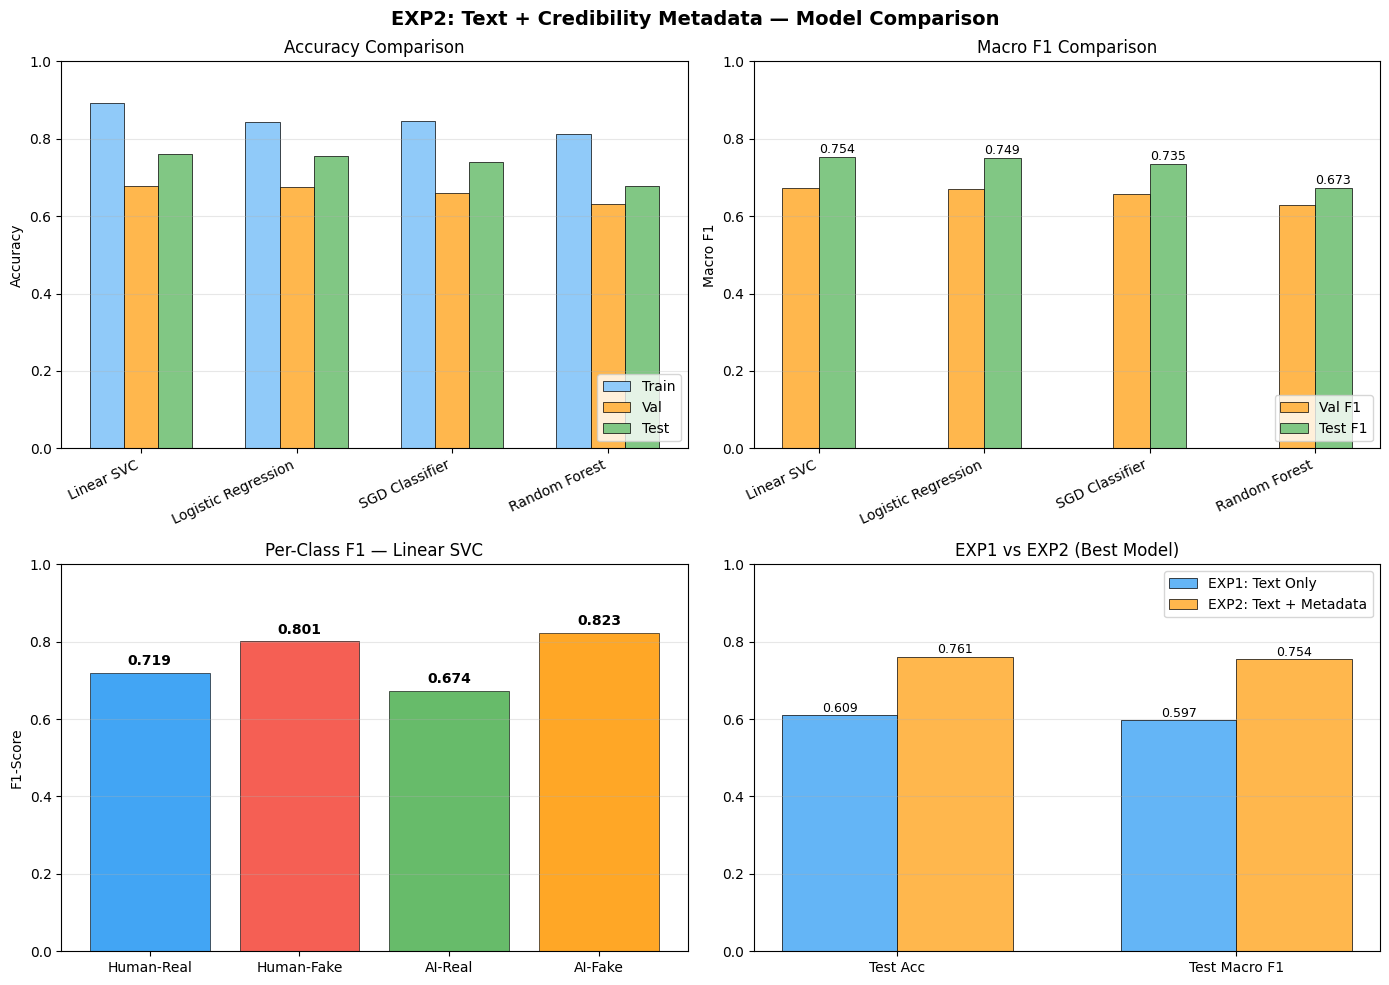

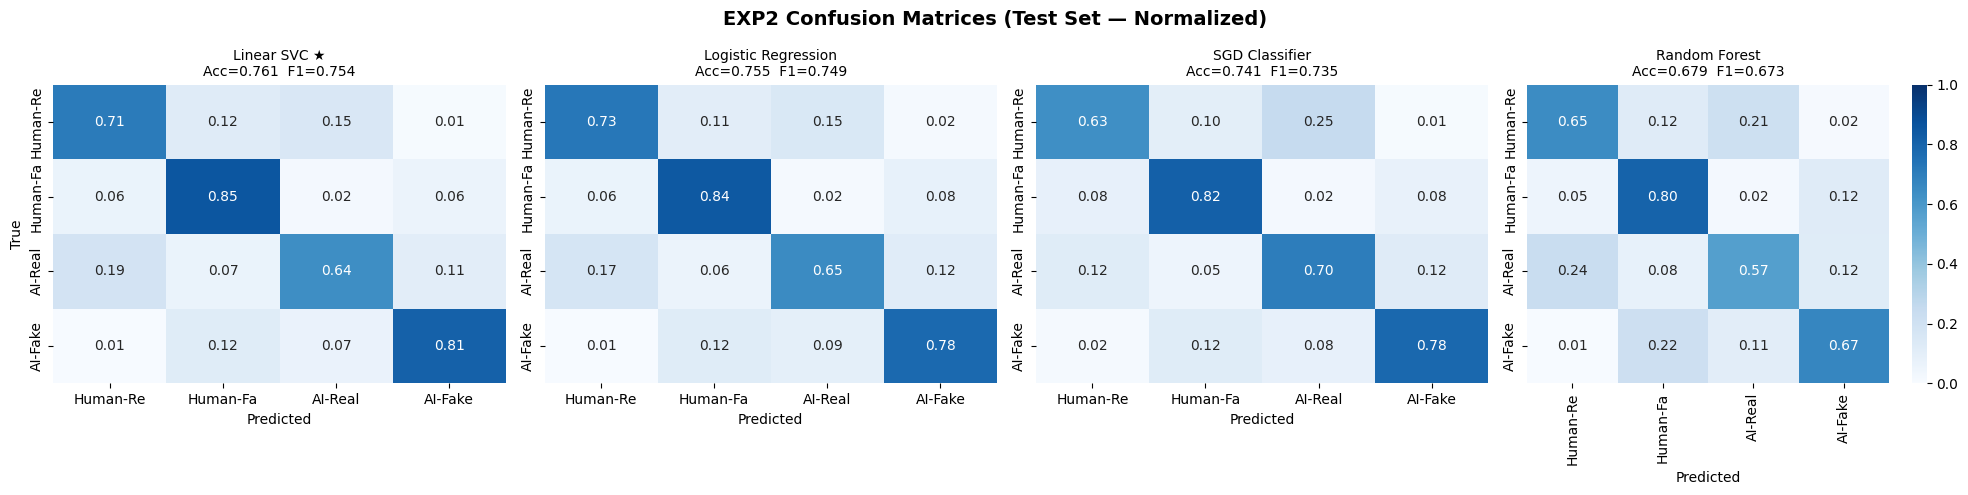

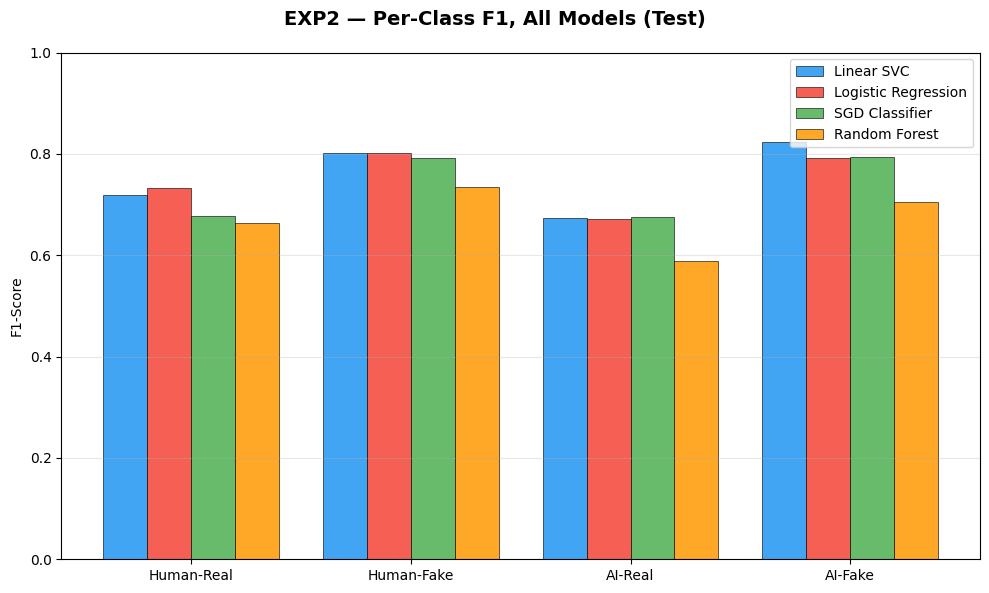

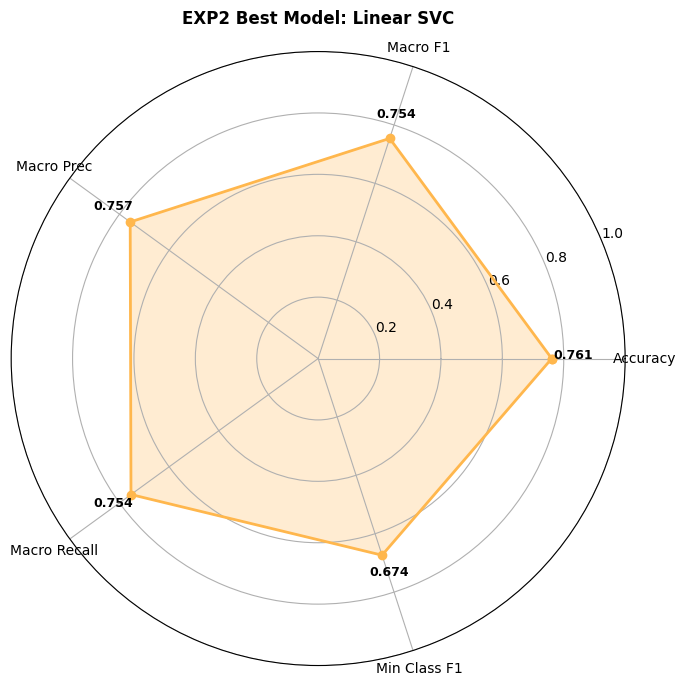


Plots saved: exp2_model_comparison.png | _confusion_matrices.png | _perclass_f1.png | _radar.png
Results saved → exp2_model_results.json

STEP 6: EXP2 MODEL TRAINING COMPLETE!


In [13]:
# ============================================================
# STEP 6: EXP2 MODEL TRAINING (4 Models)
# Text (Selected) + Credibility Metadata
# ============================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, classification_report, confusion_matrix)
from scipy.sparse import issparse
import matplotlib.pyplot as plt
import seaborn as sns
import json
from datetime import datetime
import time
import warnings
warnings.filterwarnings('ignore')


class EXP2Trainer:
    """
    EXP2 4-way classification trainer.

    Models : LR, LinearSVC, SGDClassifier, Random Forest
    CV     : 5-fold (same as EXP1 for fair comparison)
    Weights: None (dataset nearly balanced)
    Scaling: None (text sparse + metadata already scaled)
    """

    CLASS_NAMES = ['Human-Real', 'Human-Fake', 'AI-Real', 'AI-Fake']

    def __init__(self):
        self.class_mapping  = {i: n for i, n in enumerate(self.CLASS_NAMES)}
        self.models         = {}
        self.results        = {}
        self.training_times = {}

    # ─────────────────────────────────────────────
    # Model initialization
    # ─────────────────────────────────────────────

    def initialize_models(self):
        print("\nInitializing models...")

        models = {}

        # 1. Logistic Regression
        models['LogisticRegression'] = {
            'model': LogisticRegression(
                C=1.0,
                max_iter=5000,
                tol=1e-3,
                multi_class='multinomial',
                solver='saga',
                random_state=42,
                n_jobs=-1
            ),
            'name': 'Logistic Regression',
            'needs_dense': False
        }

        # 2. Linear SVC
        models['LinearSVC'] = {
            'model': LinearSVC(
                C=1.0,
                max_iter=6000,
                random_state=42,
                dual=True
            ),
            'name': 'Linear SVC',
            'needs_dense': False
        }

        # 3. SGD Classifier (fast LR-style)
        models['SGDClassifier'] = {
            'model': SGDClassifier(
                loss='log_loss',
                alpha=1e-5,
                max_iter=2000,
                tol=1e-3,
                random_state=42,
                n_jobs=-1
            ),
            'name': 'SGD Classifier',
            'needs_dense': False
        }

        # 4. Random Forest
        models['RandomForest'] = {
            'model': RandomForestClassifier(
                n_estimators=200,
                max_depth=15,
                min_samples_leaf=5,
                max_features='sqrt',
                random_state=42,
                n_jobs=-1
            ),
            'name': 'Random Forest',
            'needs_dense': True
        }

        self.models = models

        print(f"Initialized {len(self.models)} models:")
        for key, info in self.models.items():
            dense_tag = " (dense)" if info['needs_dense'] else ""
            print(f"  - {info['name']}{dense_tag}")

        return self.models

    # ─────────────────────────────────────────────
    # Data helpers
    # ─────────────────────────────────────────────

    def _to_dense(self, X):
        if issparse(X):
            return X.toarray()
        return np.array(X) if not isinstance(X, np.ndarray) else X

    # ─────────────────────────────────────────────
    # Single model training
    # ─────────────────────────────────────────────

    def train_single_model(self, model_key, model_info,
                           X_train, y_train,
                           X_val,   y_val,
                           X_test,  y_test):

        print(f"\n{'='*60}")
        print(f"Training: {model_info['name']}")
        print(f"{'='*60}")

        start = time.time()
        model = model_info['model']

        if model_info['needs_dense']:
            X_tr = self._to_dense(X_train)
            X_v  = self._to_dense(X_val)
            X_te = self._to_dense(X_test)
        else:
            X_tr, X_v, X_te = X_train, X_val, X_test

        # 5-fold Cross-validation (same as EXP1)
        print("  Running 5-fold cross-validation...")
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

        cv_acc_scores = cross_val_score(
            model, X_tr, y_train,
            cv=cv, scoring='accuracy', n_jobs=-1
        )
        cv_f1_scores = cross_val_score(
            model, X_tr, y_train,
            cv=cv, scoring='f1_macro', n_jobs=-1
        )

        print(f"  CV Accuracy : {cv_acc_scores.mean():.4f} ± {cv_acc_scores.std():.4f}")
        print(f"  CV Macro F1 : {cv_f1_scores.mean():.4f} ± {cv_f1_scores.std():.4f}")

        # Full training
        print("  Training on full training set...")
        model.fit(X_tr, y_train)

        # Predictions
        train_pred = model.predict(X_tr)
        val_pred   = model.predict(X_v)
        test_pred  = model.predict(X_te)

        # Metrics
        train_acc = accuracy_score(y_train, train_pred)
        val_acc   = accuracy_score(y_val,   val_pred)
        test_acc  = accuracy_score(y_test,  test_pred)

        train_f1 = f1_score(y_train, train_pred, average='macro', zero_division=0)
        val_f1   = f1_score(y_val,   val_pred,   average='macro', zero_division=0)
        test_f1  = f1_score(y_test,  test_pred,  average='macro', zero_division=0)

        train_weighted = f1_score(y_train, train_pred, average='weighted', zero_division=0)
        val_weighted   = f1_score(y_val,   val_pred,   average='weighted', zero_division=0)
        test_weighted  = f1_score(y_test,  test_pred,  average='weighted', zero_division=0)

        test_prec   = precision_score(y_test, test_pred, average='macro', zero_division=0)
        test_recall = recall_score(y_test, test_pred,    average='macro', zero_division=0)

        report = classification_report(
            y_test, test_pred,
            target_names=self.CLASS_NAMES,
            output_dict=True, zero_division=0
        )

        val_cm  = confusion_matrix(y_val,  val_pred)
        test_cm = confusion_matrix(y_test, test_pred)

        class_f1s = [report[cn]['f1-score'] for cn in self.CLASS_NAMES]

        elapsed = time.time() - start

        # Print results
        print(f"\n  Results ({elapsed:.1f}s):")
        print(f"  {'':15s} {'Train':>8} {'Val':>8} {'Test':>8}")
        print(f"  {'Accuracy':15s} {train_acc:>8.4f} {val_acc:>8.4f} {test_acc:>8.4f}")
        print(f"  {'Macro F1':15s} {train_f1:>8.4f} {val_f1:>8.4f} {test_f1:>8.4f}")
        print(f"  {'Weighted F1':15s} {train_weighted:>8.4f} {val_weighted:>8.4f} {test_weighted:>8.4f}")
        print(f"  {'Overfit gap':15s} {train_acc-test_acc:>8.4f}")

        print(f"\n  Per-Class Test Metrics:")
        print(f"  {'Class':15s} {'Prec':>8} {'Recall':>8} {'F1':>8} {'N':>6}")
        print(f"  {'-'*50}")
        for cn in self.CLASS_NAMES:
            m = report[cn]
            print(f"  {cn:15s} {m['precision']:>8.4f} {m['recall']:>8.4f} "
                  f"{m['f1-score']:>8.4f} {m['support']:>6}")

        result = {
            'model_name'        : model_info['name'],
            'training_time'     : float(elapsed),
            'cv_accuracy'       : float(cv_acc_scores.mean()),
            'cv_accuracy_std'   : float(cv_acc_scores.std()),
            'cv_macro_f1'       : float(cv_f1_scores.mean()),
            'cv_macro_f1_std'   : float(cv_f1_scores.std()),
            'train_accuracy'    : float(train_acc),
            'val_accuracy'      : float(val_acc),
            'test_accuracy'     : float(test_acc),
            'train_macro_f1'    : float(train_f1),
            'val_macro_f1'      : float(val_f1),
            'test_macro_f1'     : float(test_f1),
            'train_weighted_f1' : float(train_weighted),
            'val_weighted_f1'   : float(val_weighted),
            'test_weighted_f1'  : float(test_weighted),
            'test_macro_precision': float(test_prec),
            'test_macro_recall' : float(test_recall),
            'overfit_gap'       : float(train_acc - test_acc),
            'min_class_f1'      : float(min(class_f1s)),
            'max_class_f1'      : float(max(class_f1s)),
            'test_per_class'    : {
                cn: {
                    'precision': float(report[cn]['precision']),
                    'recall'   : float(report[cn]['recall']),
                    'f1-score' : float(report[cn]['f1-score']),
                    'support'  : int(report[cn]['support'])
                } for cn in self.CLASS_NAMES
            },
            'val_confusion_matrix' : val_cm.tolist(),
            'test_confusion_matrix': test_cm.tolist(),
            'val_pred'          : val_pred,
            'test_pred'         : test_pred,
            'trained_model'     : model
        }

        self.results[model_key]        = result
        self.training_times[model_key] = elapsed
        return result

    # ─────────────────────────────────────────────
    # Train all models
    # ─────────────────────────────────────────────

    def train_all(self, X_train, y_train, X_val, y_val, X_test, y_test):

        total_start = time.time()

        print("\n" + "="*70)
        print("STEP 6: EXP2 — TEXT + CREDIBILITY METADATA")
        print("="*70)
        print(f"  Train  : {X_train.shape}  sparse={issparse(X_train)}")
        print(f"  Val    : {X_val.shape}")
        print(f"  Test   : {X_test.shape}")
        print(f"  Classes: {self.CLASS_NAMES}")

        self.initialize_models()

        for key, info in self.models.items():
            self.train_single_model(
                key, info,
                X_train, y_train,
                X_val,   y_val,
                X_test,  y_test
            )

        total_time = time.time() - total_start
        print(f"\nTotal training time: {total_time/60:.1f} minutes")

        self.print_summary()
        return self.results

    # ─────────────────────────────────────────────
    # Summary & Reports
    # ─────────────────────────────────────────────

    def print_summary(self):
        sorted_r = sorted(
            self.results.items(),
            key=lambda x: x[1]['test_macro_f1'],
            reverse=True
        )
    
        print("\n" + "="*115)
        print("EXP2 MODEL COMPARISON — TEXT + CREDIBILITY METADATA (sorted by Test Macro F1)")
        print("="*115)
        print(f"  {'Model':<22} {'CV F1 (±std)':>18} {'Val Acc':>8} {'Val F1':>8} "
              f"{'Test Acc':>9} {'Test F1':>9} {'Gap':>7} {'Time':>6}")
        print("-"*115)
    
        for rank, (key, r) in enumerate(sorted_r, 1):
            marker = "★" if rank == 1 else " "
            # ±std যোগ করা হয়েছে
            cv_f1_str = f"{r['cv_macro_f1']:.4f} ± {r['cv_macro_f1_std']:.4f}"
            print(f"{marker} {r['model_name']:<21}"
                  f"{cv_f1_str:>18}"
                  f"{r['val_accuracy']:>8.4f}"
                  f"{r['val_macro_f1']:>8.4f}"
                  f"{r['test_accuracy']:>9.4f}"
                  f"{r['test_macro_f1']:>9.4f}"
                  f"{r['overfit_gap']:>7.3f}"
                  f"{r['training_time']:>5.0f}s")
    
        best_key, best = sorted_r[0]
        print("\n" + "="*115)
        print(f"  BEST MODEL       : {best['model_name']}")
        print(f"  CV Macro F1      : {best['cv_macro_f1']:.4f} ± {best['cv_macro_f1_std']:.4f}")
        print(f"  Test Accuracy    : {best['test_accuracy']:.4f} ({best['test_accuracy']*100:.2f}%)")
        print(f"  Test Macro F1    : {best['test_macro_f1']:.4f}")
        print(f"  Test Macro Prec  : {best['test_macro_precision']:.4f}")
        print(f"  Test Macro Recall: {best['test_macro_recall']:.4f}")
        print(f"  Min Class F1     : {best['min_class_f1']:.4f}")
        print(f"  Overfit Gap      : {best['overfit_gap']:.4f}")
        print("="*115)
    
        # ── Per-class F1 summary (নতুন) ──────────────────────
        print(f"\n{'─'*75}")
        print("PER-CLASS F1 SUMMARY (Test Set)")
        print(f"{'─'*75}")
        print(f"  {'Model':<22} {'Human-Real':>12} {'Human-Fake':>12} "
              f"{'AI-Real':>10} {'AI-Fake':>10}")
        print(f"  {'─'*68}")
    
        for rank, (key, r) in enumerate(sorted_r, 1):
            marker = "★" if rank == 1 else " "
            hr = r['test_per_class']['Human-Real']['f1-score']
            hf = r['test_per_class']['Human-Fake']['f1-score']
            ar = r['test_per_class']['AI-Real']['f1-score']
            af = r['test_per_class']['AI-Fake']['f1-score']
            print(f"{marker} {r['model_name']:<21}"
                  f"{hr:>12.4f}"
                  f"{hf:>12.4f}"
                  f"{ar:>10.4f}"
                  f"{af:>10.4f}")
        print(f"{'─'*75}")

    def print_best_report(self):
        best_key = max(self.results, key=lambda k: self.results[k]['test_macro_f1'])
        best     = self.results[best_key]

        print(f"\n{'='*60}")
        print(f"DETAILED REPORT — {best['model_name']}")
        print(f"{'='*60}")
        print(f"\n  Test Accuracy    : {best['test_accuracy']:.4f}")
        print(f"  Test Macro F1    : {best['test_macro_f1']:.4f}")
        print(f"  Test Weighted F1 : {best['test_weighted_f1']:.4f}")
        print(f"  Test Macro Prec  : {best['test_macro_precision']:.4f}")
        print(f"  Test Macro Recall: {best['test_macro_recall']:.4f}")

        print(f"\n  Per-Class Metrics (Test):")
        print(f"  {'Class':15s} {'Precision':>10} {'Recall':>10} "
              f"{'F1-Score':>10} {'Support':>10}")
        print(f"  {'-'*55}")
        for cn in self.CLASS_NAMES:
            m = best['test_per_class'][cn]
            print(f"  {cn:15s} {m['precision']:>10.4f} {m['recall']:>10.4f} "
                  f"{m['f1-score']:>10.4f} {m['support']:>10}")

        print(f"\n  Confusion Matrix (Test):")
        cm     = np.array(best['test_confusion_matrix'])
        header = f"  {'Predicted →':15s}" + "".join(
            f"{n[:10]:>12s}" for n in self.CLASS_NAMES
        )
        print(header)
        print(f"  {'Actual ↓':15s}")
        for i, row in enumerate(cm):
            print(f"  {self.CLASS_NAMES[i]:15s}" + "".join(f"{v:>12d}" for v in row))

    # ─────────────────────────────────────────────
    # Visualizations
    # ─────────────────────────────────────────────

    def plot_results(self, exp1_results=None, save_prefix='exp2'):

        sorted_r    = sorted(self.results.items(),
                             key=lambda x: x[1]['test_macro_f1'], reverse=True)
        model_names = [r['model_name'] for _, r in sorted_r]
        n_models    = len(model_names)
        x           = np.arange(n_models)
        width       = 0.22
        best        = sorted_r[0][1]

        # ── Figure 1: Main comparison ──────────────────────
        fig1, axes = plt.subplots(2, 2, figsize=(14, 10))
        fig1.suptitle('EXP2: Text + Credibility Metadata — Model Comparison',
                      fontsize=14, fontweight='bold')

        # Accuracy
        axes[0,0].bar(x-width, [r['train_accuracy'] for _,r in sorted_r],
                      width, label='Train', color='#90CAF9', edgecolor='black', linewidth=0.5)
        axes[0,0].bar(x,       [r['val_accuracy']   for _,r in sorted_r],
                      width, label='Val',   color='#FFB74D', edgecolor='black', linewidth=0.5)
        axes[0,0].bar(x+width, [r['test_accuracy']  for _,r in sorted_r],
                      width, label='Test',  color='#81C784', edgecolor='black', linewidth=0.5)
        axes[0,0].set_title('Accuracy Comparison')
        axes[0,0].set_xticks(x)
        axes[0,0].set_xticklabels(model_names, rotation=25, ha='right')
        axes[0,0].set_ylabel('Accuracy')
        axes[0,0].legend(loc='lower right')
        axes[0,0].grid(axis='y', alpha=0.3)
        axes[0,0].set_ylim(0, 1)

        # Macro F1
        axes[0,1].bar(x-width/2, [r['val_macro_f1']  for _,r in sorted_r],
                      width, label='Val F1',  color='#FFB74D', edgecolor='black', linewidth=0.5)
        axes[0,1].bar(x+width/2, [r['test_macro_f1'] for _,r in sorted_r],
                      width, label='Test F1', color='#81C784', edgecolor='black', linewidth=0.5)
        axes[0,1].set_title('Macro F1 Comparison')
        axes[0,1].set_xticks(x)
        axes[0,1].set_xticklabels(model_names, rotation=25, ha='right')
        axes[0,1].set_ylabel('Macro F1')
        axes[0,1].legend(loc='lower right')
        axes[0,1].grid(axis='y', alpha=0.3)
        axes[0,1].set_ylim(0, 1)
        for i, (_, r) in enumerate(sorted_r):
            axes[0,1].text(i+width/2, r['test_macro_f1']+0.01,
                           f"{r['test_macro_f1']:.3f}", ha='center', fontsize=9)

        # Per-class F1 (best model)
        f1_scores = [best['test_per_class'][cn]['f1-score'] for cn in self.CLASS_NAMES]
        colors    = ['#2196F3', '#F44336', '#4CAF50', '#FF9800']
        bars = axes[1,0].bar(self.CLASS_NAMES, f1_scores, color=colors,
                             edgecolor='black', linewidth=0.5, alpha=0.85)
        axes[1,0].set_title(f'Per-Class F1 — {best["model_name"]}')
        axes[1,0].set_ylabel('F1-Score')
        axes[1,0].set_ylim(0, 1)
        axes[1,0].grid(axis='y', alpha=0.3)
        for bar, v in zip(bars, f1_scores):
            axes[1,0].text(bar.get_x()+bar.get_width()/2, v+0.02,
                           f'{v:.3f}', ha='center', fontsize=10, fontweight='bold')

        # EXP1 vs EXP2
        if exp1_results is not None:
            metrics   = ['Test Acc', 'Test Macro F1']
            exp1_vals = [
                exp1_results.get('test_accuracy', 0),
                exp1_results.get('test_macro_f1', 0)
            ]
            exp2_vals = [best['test_accuracy'], best['test_macro_f1']]

            x_comp = np.arange(len(metrics))
            axes[1,1].bar(x_comp-0.17, exp1_vals, 0.34,
                          label='EXP1: Text Only',
                          color='#64B5F6', edgecolor='black', linewidth=0.5)
            axes[1,1].bar(x_comp+0.17, exp2_vals, 0.34,
                          label='EXP2: Text + Metadata',
                          color='#FFB74D', edgecolor='black', linewidth=0.5)
            axes[1,1].set_xticks(x_comp)
            axes[1,1].set_xticklabels(metrics)
            axes[1,1].set_ylim(0, 1)
            axes[1,1].set_title('EXP1 vs EXP2 (Best Model)')
            axes[1,1].legend()
            axes[1,1].grid(axis='y', alpha=0.3)
            for i, (e1, e2) in enumerate(zip(exp1_vals, exp2_vals)):
                axes[1,1].text(i-0.17, e1+0.01, f'{e1:.3f}', ha='center', fontsize=9)
                axes[1,1].text(i+0.17, e2+0.01, f'{e2:.3f}', ha='center', fontsize=9)
        else:
            gaps = [r['overfit_gap'] for _, r in sorted_r]
            gap_colors = [
                '#F44336' if g > 0.15 else
                '#FF9800' if g > 0.08 else
                '#4CAF50' for g in gaps
            ]
            axes[1,1].bar(model_names, gaps, color=gap_colors,
                          edgecolor='black', linewidth=0.5)
            axes[1,1].set_title('Overfitting Gap')
            axes[1,1].set_ylabel('Train - Test Accuracy')
            axes[1,1].set_xticklabels(model_names, rotation=25, ha='right')
            axes[1,1].grid(axis='y', alpha=0.3)

        plt.tight_layout()
        plt.savefig(f'{save_prefix}_model_comparison.png', dpi=300, bbox_inches='tight')
        plt.show()

        # ── Figure 2: Confusion matrices ───────────────────
        fig2, axes2 = plt.subplots(1, n_models, figsize=(5*n_models, 5))
        fig2.suptitle('EXP2 Confusion Matrices (Test Set — Normalized)',
                      fontsize=14, fontweight='bold')
        if n_models == 1:
            axes2 = [axes2]

        for idx, (key, r) in enumerate(sorted_r):
            cm      = np.array(r['test_confusion_matrix'])
            cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
            sns.heatmap(
                cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=[n[:8] for n in self.CLASS_NAMES],
                yticklabels=[n[:8] for n in self.CLASS_NAMES],
                ax=axes2[idx], vmin=0, vmax=1,
                cbar=(idx == n_models-1)
            )
            marker = " ★" if idx == 0 else ""
            axes2[idx].set_title(
                f"{r['model_name']}{marker}\n"
                f"Acc={r['test_accuracy']:.3f}  F1={r['test_macro_f1']:.3f}",
                fontsize=10
            )
            axes2[idx].set_ylabel('True' if idx == 0 else '')
            axes2[idx].set_xlabel('Predicted')

        plt.tight_layout()
        plt.savefig(f'{save_prefix}_confusion_matrices.png', dpi=300, bbox_inches='tight')
        plt.show()

        # ── Figure 3: Per-class F1 all models ──────────────
        fig3, ax3 = plt.subplots(figsize=(10, 6))
        fig3.suptitle('EXP2 — Per-Class F1, All Models (Test)',
                      fontsize=14, fontweight='bold')

        x_class     = np.arange(len(self.CLASS_NAMES))
        width_class = 0.8 / n_models
        colors_m    = ['#2196F3', '#F44336', '#4CAF50', '#FF9800']

        for idx, (key, r) in enumerate(sorted_r):
            f1s = [r['test_per_class'][cn]['f1-score'] for cn in self.CLASS_NAMES]
            ax3.bar(x_class + idx*width_class, f1s, width_class,
                    label=r['model_name'],
                    color=colors_m[idx % len(colors_m)],
                    edgecolor='black', linewidth=0.5, alpha=0.85)

        ax3.set_ylabel('F1-Score')
        ax3.set_xticks(x_class + width_class*(n_models-1)/2)
        ax3.set_xticklabels(self.CLASS_NAMES)
        ax3.set_ylim(0, 1)
        ax3.legend(loc='upper right')
        ax3.grid(axis='y', alpha=0.3)
        plt.tight_layout()
        plt.savefig(f'{save_prefix}_perclass_f1.png', dpi=300, bbox_inches='tight')
        plt.show()

        # ── Figure 4: Radar chart (best model) ─────────────
        fig4, ax4 = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
        radar_metrics = ['Accuracy', 'Macro F1', 'Macro Prec', 'Macro Recall', 'Min Class F1']
        radar_values  = [
            best['test_accuracy'],
            best['test_macro_f1'],
            best['test_macro_precision'],
            best['test_macro_recall'],
            best['min_class_f1']
        ]
        angles = np.linspace(0, 2*np.pi, len(radar_metrics), endpoint=False).tolist()
        angles       += [angles[0]]
        radar_values += [radar_values[0]]

        ax4.fill(angles, radar_values, color='#FFB74D', alpha=0.25)
        ax4.plot(angles, radar_values, color='#FFB74D',
                 linewidth=2, marker='o', markersize=6)
        ax4.set_xticks(angles[:-1])
        ax4.set_xticklabels(radar_metrics, fontsize=10)
        ax4.set_ylim(0, 1)
        ax4.set_title(f'EXP2 Best Model: {best["model_name"]}',
                      fontsize=12, fontweight='bold', pad=20)
        for angle, value in zip(angles[:-1], radar_values[:-1]):
            ax4.text(angle, value+0.07, f'{value:.3f}',
                     ha='center', fontsize=9, fontweight='bold')

        plt.tight_layout()
        plt.savefig(f'{save_prefix}_radar.png', dpi=300, bbox_inches='tight')
        plt.show()

        print(f"\nPlots saved: {save_prefix}_model_comparison.png | "
              f"_confusion_matrices.png | _perclass_f1.png | _radar.png")

    # ─────────────────────────────────────────────
    # Save
    # ─────────────────────────────────────────────

    def save_results(self, filepath='exp2_model_results.json'):
        save_data = {
            'timestamp' : datetime.now().isoformat(),
            'experiment': 'EXP2 — Text + Credibility Metadata',
            'class_mapping': self.class_mapping,
            'models': {
                k: {kk: vv for kk, vv in v.items()
                    if kk not in ['trained_model', 'val_pred', 'test_pred']}
                for k, v in self.results.items()
            }
        }
        with open(filepath, 'w') as f:
            json.dump(save_data, f, indent=2)
        print(f"Results saved → {filepath}")


# ============================================================
# RUN STEP 6
# ============================================================

if 'exp2_data' in globals():

    X_train = exp2_data['combined']['X_train']
    X_val   = exp2_data['combined']['X_val']
    X_test  = exp2_data['combined']['X_test']

    y_train = exp2_data['labels']['y_train']
    y_val   = exp2_data['labels']['y_val']
    y_test  = exp2_data['labels']['y_test']

    print(f"  X_train : {X_train.shape}  sparse={issparse(X_train)}")
    print(f"  X_val   : {X_val.shape}")
    print(f"  X_test  : {X_test.shape}")

    # Train all 4 models
    exp2_trainer = EXP2Trainer()
    exp2_model_results = exp2_trainer.train_all(
        X_train, y_train,
        X_val,   y_val,
        X_test,  y_test
    )

    # Detailed report
    exp2_trainer.print_best_report()

    # EXP1 baseline for comparison plot
    exp1_baseline = {
        'test_accuracy': exp2_results['exp1_baseline']['test_accuracy'],
        'test_macro_f1': exp2_results['exp1_baseline']['test_macro_f1']
    }

    # Plots
    exp2_trainer.plot_results(
        exp1_results=exp1_baseline,
        save_prefix='exp2'
    )

    # Save
    exp2_trainer.save_results('exp2_model_results.json')

    print("\n" + "="*60)
    print("STEP 6: EXP2 MODEL TRAINING COMPLETE!")
    print("="*60)

else:
    print("ERROR: Run EXP2 feature preparation (Step 5) first!")
    print("  Required: exp2_data")


METADATA FEATURE IMPORTANCE ANALYSIS — EXP2
  LR coefficient shape : (4, 4041)
  Text features        : 4000
  Metadata features    : 41
  Total features       : 4041
  LR coef columns      : 4041
  Extracting metadata features from 5 samples...
    Extracted 41 metadata features
  Metadata feature names: 41
  Meta coef shape      : (4, 41)


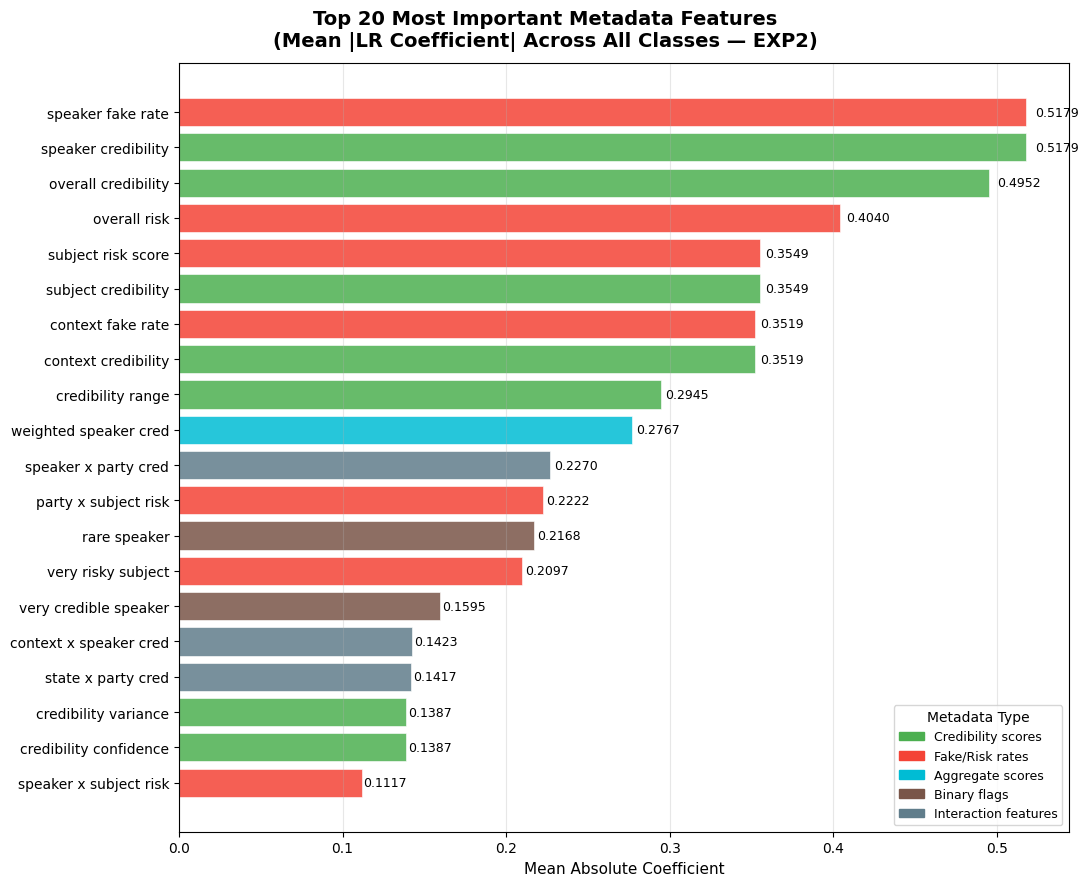


  Saved → exp2_metadata_importance_overall.png


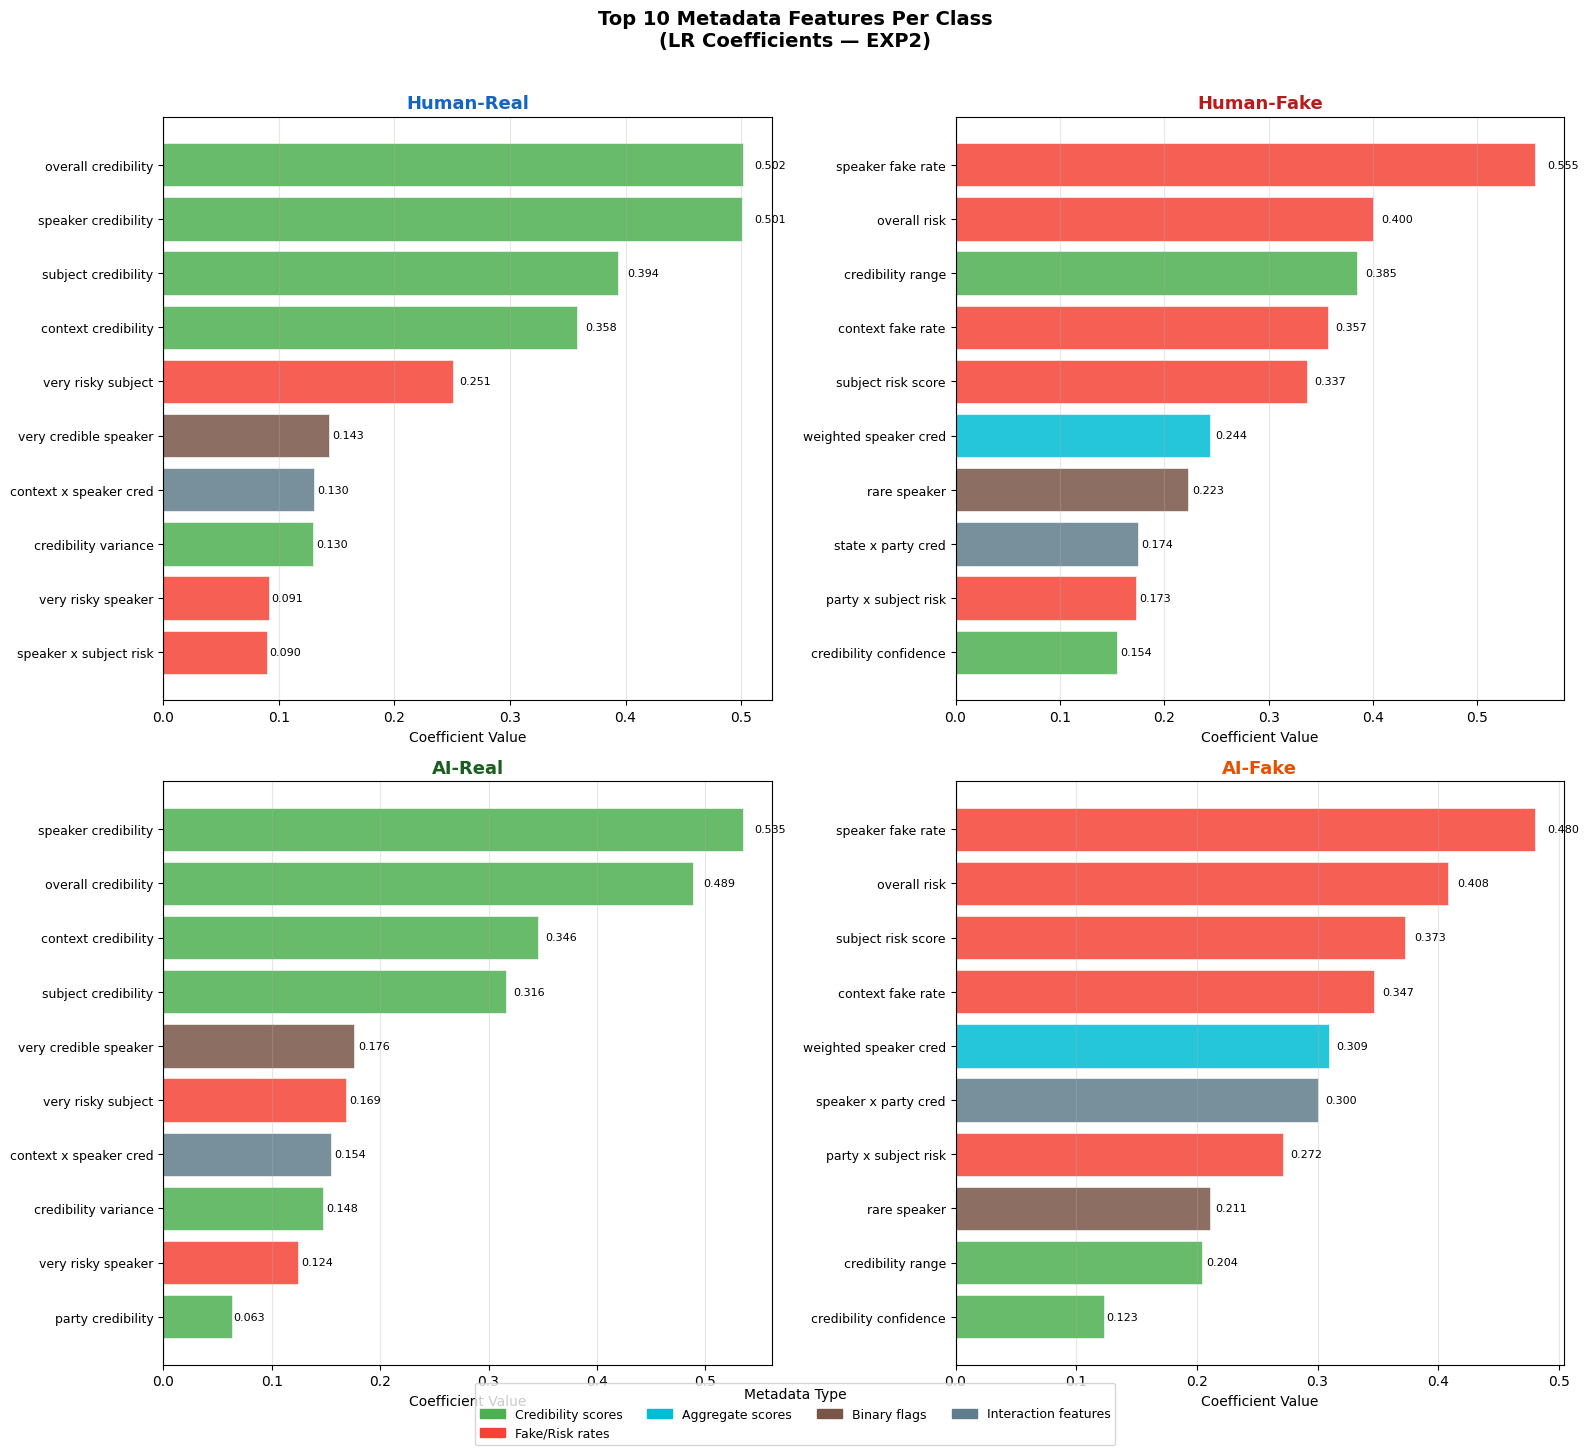

  Saved → exp2_metadata_importance_per_class.png


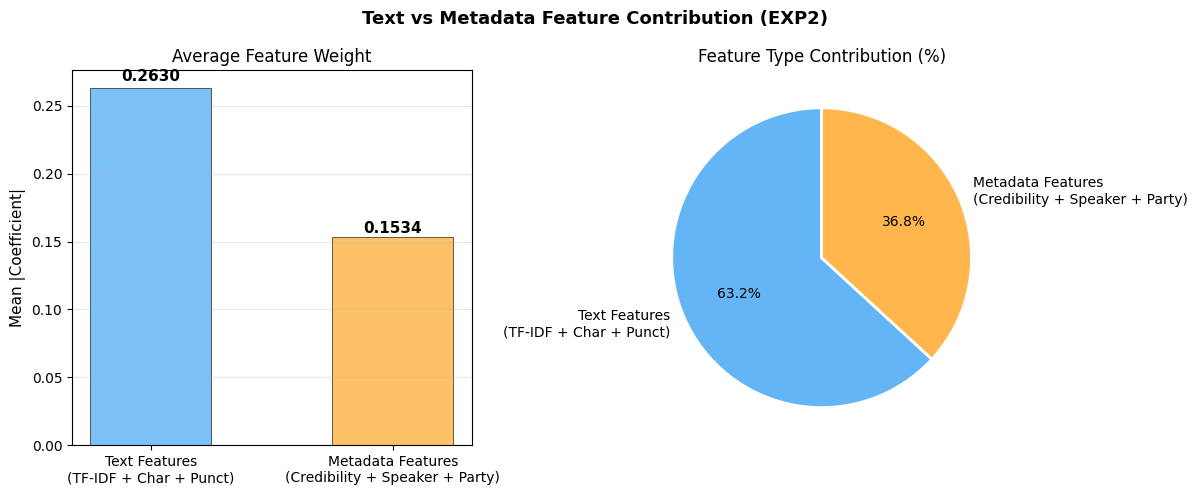

  Saved → exp2_metadata_importance_text_vs_meta.png

──────────────────────────────────────────────────────────────────────
METADATA IMPORTANCE SUMMARY
──────────────────────────────────────────────────────────────────────

  Mean |coef| — Text features     : 0.2630
  Mean |coef| — Metadata features  : 0.1534
  Metadata / Text ratio             : 0.58x

  Top 10 Most Important Metadata Features (Overall):
  Rank   Feature                              Mean |Coef|
  ───────────────────────────────────────────────────────
  1      speaker fake rate                         0.5179
  2      speaker credibility                       0.5179
  3      overall credibility                       0.4952
  4      overall risk                              0.4040
  5      subject risk score                        0.3549
  6      subject credibility                       0.3549
  7      context fake rate                         0.3519
  8      context credibility                       0.3519
  9      cr

In [14]:
# ============================================================
# METADATA FEATURE IMPORTANCE ANALYSIS (EXP2)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')


def plot_metadata_importance_exp2(exp2_trainer, exp2_data,
                                   top_n=20, save_prefix='exp2_metadata_importance'):
    """
    Extract and visualize top metadata features from
    Logistic Regression coefficients (EXP2).

    Shows:
    1. Top metadata features overall (mean absolute coefficient)
    2. Per-class top metadata features (4 subplots)
    3. Text vs Metadata contribution comparison
    """

    print("\n" + "="*70)
    print("METADATA FEATURE IMPORTANCE ANALYSIS — EXP2")
    print("="*70)

    # ── Step 1: Get LR model from EXP2 ────────────────────
    lr_result = exp2_trainer.results.get('LogisticRegression', None)
    if lr_result is None:
        print("ERROR: Logistic Regression result not found in EXP2!")
        return None

    lr_model = lr_result['trained_model']
    print(f"  LR coefficient shape : {lr_model.coef_.shape}")

    # ── Step 2: Feature split info ─────────────────────────
    n_text = exp2_data['text']['X_train'].shape[1]
    n_meta = exp2_data['metadata']['X_train'].shape[1]
    n_total = n_text + n_meta

    print(f"  Text features        : {n_text}")
    print(f"  Metadata features    : {n_meta}")
    print(f"  Total features       : {n_total}")
    print(f"  LR coef columns      : {lr_model.coef_.shape[1]}")

    # ── Step 3: Get metadata feature names ────────────────
    try:
        sample_meta = exp2_data['extractor'].transform(
            train_processed.head(5)
        )
        meta_feature_names = sample_meta.columns.tolist()
        print(f"  Metadata feature names: {len(meta_feature_names)}")
    except Exception as e:
        print(f"  Warning: Could not get feature names — {e}")
        meta_feature_names = [f'meta_feature_{i}' for i in range(n_meta)]

    # Ensure length matches
    if len(meta_feature_names) != n_meta:
        print(f"  Warning: name count ({len(meta_feature_names)}) != n_meta ({n_meta})")
        meta_feature_names = [f'meta_feature_{i}' for i in range(n_meta)]

    # ── Step 4: Extract metadata coefficients ─────────────
    # Combined feature space: [text_features | metadata_features]
    meta_coefs = lr_model.coef_[:, n_text:n_text + n_meta]
    text_coefs = lr_model.coef_[:, :n_text]

    print(f"  Meta coef shape      : {meta_coefs.shape}")

    # ── Step 5: Color mapping by metadata type ─────────────
    def get_meta_color(name):
        if 'credibility' in name:
            return '#4CAF50'    # Green
        elif 'fake_rate' in name or 'risk' in name:
            return '#F44336'    # Red
        elif 'encoded' in name:
            return '#2196F3'    # Blue
        elif 'mismatch' in name or 'conflict' in name or 'range' in name:
            return '#FF9800'    # Orange
        elif 'count' in name or 'statement' in name:
            return '#9C27B0'    # Purple
        elif any(x in name for x in ['overall', 'weighted', 'confidence', 'variance']):
            return '#00BCD4'    # Cyan
        elif any(x in name for x in ['is_', 'has_', 'very_', 'rare_', 'high_']):
            return '#795548'    # Brown
        elif 'x_' in name:
            return '#607D8B'    # Grey-Blue (interaction)
        else:
            return '#9E9E9E'    # Grey

    META_LEGEND = {
        '#4CAF50': 'Credibility scores',
        '#F44336': 'Fake/Risk rates',
        '#2196F3': 'Categorical encodings',
        '#FF9800': 'Conflict/Mismatch',
        '#9C27B0': 'Statement counts',
        '#00BCD4': 'Aggregate scores',
        '#795548': 'Binary flags',
        '#607D8B': 'Interaction features',
    }

    def clean_meta_name(name, max_len=32):
        name = name.replace('_', ' ').replace('grouped', '').strip()
        return name[:max_len] + '...' if len(name) > max_len else name

    # ── Step 6: Overall top metadata features ─────────────
    mean_abs_meta = np.mean(np.abs(meta_coefs), axis=0)
    top_idx = np.argsort(mean_abs_meta)[-top_n:][::-1]

    top_names   = [meta_feature_names[i] for i in top_idx]
    top_values  = mean_abs_meta[top_idx]
    top_display = [clean_meta_name(n) for n in top_names]
    top_colors  = [get_meta_color(n) for n in top_names]

    fig1, ax1 = plt.subplots(figsize=(11, 9))
    fig1.suptitle(
        f'Top {top_n} Most Important Metadata Features\n'
        f'(Mean |LR Coefficient| Across All Classes — EXP2)',
        fontsize=14, fontweight='bold'
    )

    y_pos = np.arange(len(top_display))
    bars  = ax1.barh(y_pos, top_values,
                     color=top_colors, alpha=0.85,
                     edgecolor='white', linewidth=0.5)

    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(top_display, fontsize=10)
    ax1.set_xlabel('Mean Absolute Coefficient', fontsize=11)
    ax1.invert_yaxis()
    ax1.grid(axis='x', alpha=0.3)

    for bar, val in zip(bars, top_values):
        ax1.text(val + abs(val) * 0.01,
                 bar.get_y() + bar.get_height() / 2,
                 f'{val:.4f}', va='center', fontsize=9)

    # Legend
    used_colors = set(top_colors)
    legend_handles = [
        mpatches.Patch(color=c, label=l)
        for c, l in META_LEGEND.items()
        if c in used_colors
    ]
    ax1.legend(handles=legend_handles,
               loc='lower right', fontsize=9,
               title='Metadata Type')

    plt.tight_layout()
    plt.savefig(f'{save_prefix}_overall.png',
                dpi=300, bbox_inches='tight')
    plt.show()
    print(f"\n  Saved → {save_prefix}_overall.png")

    # ── Step 7: Per-class metadata features ───────────────
    CLASS_NAMES  = exp2_trainer.CLASS_NAMES
    CLASS_COLORS = ['#1565C0', '#B71C1C', '#1B5E20', '#E65100']
    top_n_class  = 10

    fig2, axes = plt.subplots(2, 2, figsize=(16, 14))
    fig2.suptitle(
        f'Top {top_n_class} Metadata Features Per Class\n'
        f'(LR Coefficients — EXP2)',
        fontsize=14, fontweight='bold', y=1.01
    )

    per_class_data = {}

    for idx, (class_name, cls_color) in enumerate(zip(CLASS_NAMES, CLASS_COLORS)):
        ax = axes[idx // 2][idx % 2]

        coefs    = meta_coefs[idx]
        top_cidx = np.argsort(coefs)[-top_n_class:][::-1]

        c_names   = [meta_feature_names[i] for i in top_cidx]
        c_values  = coefs[top_cidx]
        c_display = [clean_meta_name(n) for n in c_names]
        c_colors  = [get_meta_color(n) for n in c_names]

        y_pos = np.arange(len(c_display))
        bars  = ax.barh(y_pos, c_values,
                        color=c_colors, alpha=0.85,
                        edgecolor='white', linewidth=0.5)

        ax.set_yticks(y_pos)
        ax.set_yticklabels(c_display, fontsize=9)
        ax.set_xlabel('Coefficient Value', fontsize=10)
        ax.set_title(f'{class_name}', fontsize=13,
                     fontweight='bold', color=cls_color)
        ax.invert_yaxis()
        ax.grid(axis='x', alpha=0.3)
        ax.axvline(x=0, color='black', linewidth=0.8, alpha=0.5)

        for bar, val in zip(bars, c_values):
            ax.text(val + abs(val) * 0.02,
                    bar.get_y() + bar.get_height() / 2,
                    f'{val:.3f}', va='center', fontsize=8)

        per_class_data[class_name] = {
            'features'    : c_names,
            'display'     : c_display,
            'coefficients': c_values.tolist()
        }

    # Shared legend
    all_colors_used = set()
    for data in per_class_data.values():
        all_colors_used.update(
            get_meta_color(n) for n in data['features']
        )
    legend_handles2 = [
        mpatches.Patch(color=c, label=l)
        for c, l in META_LEGEND.items()
        if c in all_colors_used
    ]
    fig2.legend(handles=legend_handles2,
                loc='lower center', ncol=4,
                fontsize=9, bbox_to_anchor=(0.5, -0.02),
                title='Metadata Type', title_fontsize=10)

    plt.tight_layout()
    plt.savefig(f'{save_prefix}_per_class.png',
                dpi=300, bbox_inches='tight')
    plt.show()
    print(f"  Saved → {save_prefix}_per_class.png")

    # ── Step 8: Text vs Metadata contribution ─────────────
    text_importance = float(np.mean(np.abs(text_coefs)))
    meta_importance = float(np.mean(np.abs(meta_coefs)))
    ratio = meta_importance / text_importance if text_importance > 0 else 0

    fig3, axes3 = plt.subplots(1, 2, figsize=(12, 5))
    fig3.suptitle('Text vs Metadata Feature Contribution (EXP2)',
                  fontsize=13, fontweight='bold')

    # Bar chart
    categories = ['Text Features\n(TF-IDF + Char + Punct)',
                  'Metadata Features\n(Credibility + Speaker + Party)']
    values     = [text_importance, meta_importance]
    colors_bar = ['#64B5F6', '#FFB74D']

    bars3 = axes3[0].bar(categories, values,
                          color=colors_bar,
                          edgecolor='black', linewidth=0.5,
                          alpha=0.85, width=0.5)
    axes3[0].set_ylabel('Mean |Coefficient|', fontsize=11)
    axes3[0].set_title('Average Feature Weight')
    axes3[0].grid(axis='y', alpha=0.3)

    for bar, val in zip(bars3, values):
        axes3[0].text(bar.get_x() + bar.get_width() / 2,
                      val + val * 0.02,
                      f'{val:.4f}', ha='center',
                      fontsize=11, fontweight='bold')

    # Pie chart
    axes3[1].pie(
        values,
        labels=categories,
        colors=colors_bar,
        autopct='%1.1f%%',
        startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    axes3[1].set_title('Feature Type Contribution (%)')

    plt.tight_layout()
    plt.savefig(f'{save_prefix}_text_vs_meta.png',
                dpi=300, bbox_inches='tight')
    plt.show()
    print(f"  Saved → {save_prefix}_text_vs_meta.png")

    # ── Step 9: Print summary ──────────────────────────────
    print(f"\n{'─'*70}")
    print("METADATA IMPORTANCE SUMMARY")
    print(f"{'─'*70}")
    print(f"\n  Mean |coef| — Text features     : {text_importance:.4f}")
    print(f"  Mean |coef| — Metadata features  : {meta_importance:.4f}")
    print(f"  Metadata / Text ratio             : {ratio:.2f}x")

    print(f"\n  Top 10 Most Important Metadata Features (Overall):")
    print(f"  {'Rank':<6} {'Feature':<35} {'Mean |Coef|':>12}")
    print(f"  {'─'*55}")
    for i, (name, val) in enumerate(zip(top_names[:10], top_values[:10])):
        print(f"  {i+1:<6} {clean_meta_name(name):<35} {val:>12.4f}")

    print(f"\n  Top 3 Metadata Features Per Class:")
    for class_name in CLASS_NAMES:
        data = per_class_data[class_name]
        print(f"\n  {class_name}:")
        for i, (feat, coef) in enumerate(
            zip(data['display'][:3], data['coefficients'][:3])
        ):
            print(f"    {i+1}. {feat:<35s}  coef = {coef:+.4f}")

    # Metadata type contribution
    print(f"\n  Metadata Type Contribution (Top {top_n} Overall):")
    type_counts = {}
    for name in top_names:
        color = get_meta_color(name)
        label = META_LEGEND.get(color, 'Other')
        type_counts[label] = type_counts.get(label, 0) + 1

    for label, count in sorted(type_counts.items(),
                                key=lambda x: x[1], reverse=True):
        bar_str = '█' * count
        print(f"  {label:<25}: {bar_str} ({count}/{top_n})")

    print(f"\n{'='*70}")
    print("METADATA FEATURE IMPORTANCE ANALYSIS COMPLETE")
    print(f"{'='*70}")

    return per_class_data


# ============================================================
# RUN METADATA IMPORTANCE
# ============================================================

if 'exp2_trainer' in globals() and 'exp2_data' in globals():

    meta_importance_data = plot_metadata_importance_exp2(
        exp2_trainer = exp2_trainer,
        exp2_data    = exp2_data,
        top_n        = 20,
        save_prefix  = 'exp2_metadata_importance'
    )

else:
    print("ERROR: Required variables not found!")
    print("  Need: exp2_trainer, exp2_data")